# MAE O3 · 16-step schedule planning

**Complete** · 6/6 arms complete.

Updated 2026-11-24T17:29:17+01:00 Stockholm time.

## Matched pilot

Seeds 2026, 2027, 2028 start from the registered Fixed-128 calibration.
Each arm consumes 2,048 arrivals after the common 8,000-image prefix.
The planner sees the 16-image block before executing any of it. It compares eight schedules with matching masks
and commits all 16 actions of the winner. This introduces a 15-arrival lookahead for the first action.

Each schedule has four skips, eight 0.25× updates and four 1× updates. The shuffle uses an independent
permutation at each block and preserves its exact action counts. Every seed is a paired comparison.
The planner minimizes scaled terminal current-image reconstruction loss minus 0.25 times scaled Fixed-128
RankMe. Held-out labels enter only the five endpoint linear probes.

The planner performs 96 scratch optimizer steps per block plus eight terminal readouts. Time excludes
initialization, probe evaluation and notebook publishing. The historical dense and sparse +16
[feedback pilot](MAE_O3_t_plus_16_Sparse_Paired_Rollouts.ipynb) used about 752 and 47 scratch steps
per 16 arrivals, respectively.

## Completed pairs

| Seed | Planner probe | Shuffle probe | Difference | Planner time | Shuffle time |
| --- | ---: | ---: | ---: | ---: | ---: |
| 2026 | 60.86% | 60.90% | -0.04 pp | 31.1 s | 12.6 s |
| 2027 | 61.30% | 60.61% | +0.69 pp | 30.1 s | 12.7 s |
| 2028 | 60.53% | 60.20% | +0.33 pp | 29.9 s | 12.6 s |

Mean paired endpoint difference across 3 completed seeds: +0.33 pp.

Mean terminal O3 cost was 6.5762 with planning and 6.6586 with shuffling. Lower is better. Each arm follows its own learner trajectory.

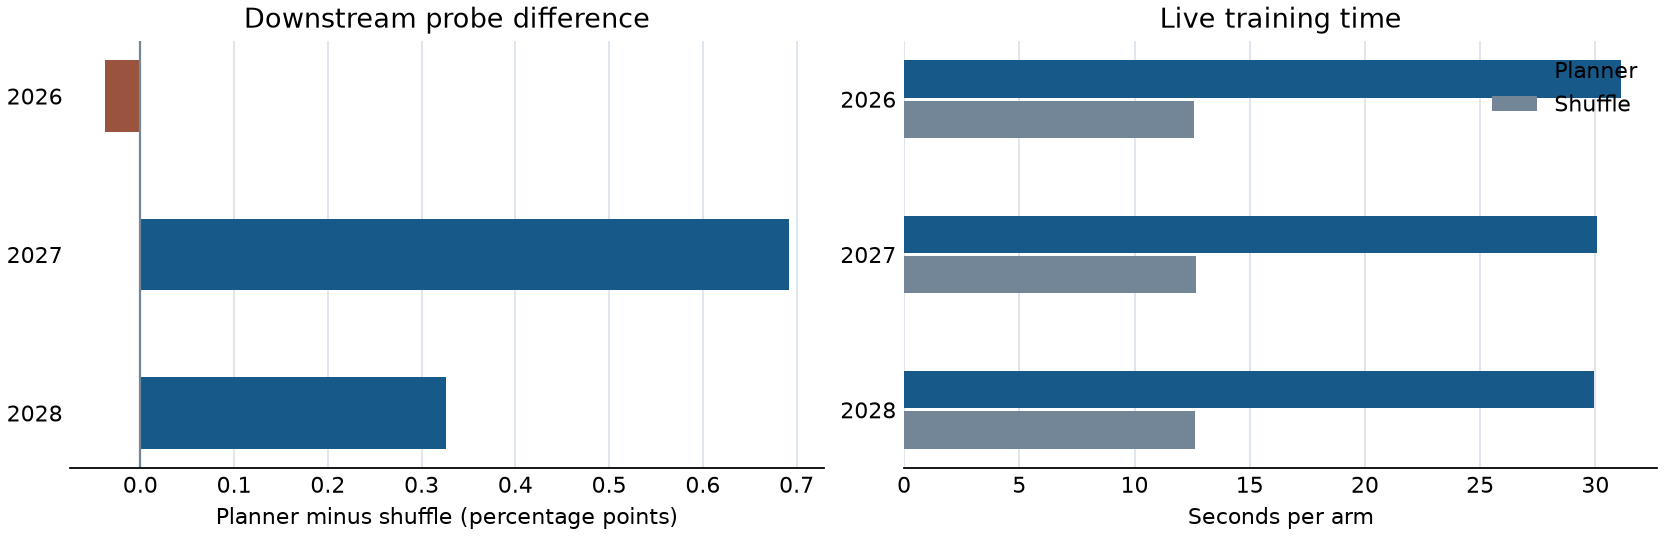

## Training trajectories

Each recorded point comes from the learner after committing all 16 actions in a block.
Reconstruction MSE measures the final image of that block. RankMe uses the same Fixed-128
bank as the planner. O3 cost combines the two using the registered seed-specific scales,
with lower cost preferred. The faint lines show the recorded block readouts. The solid
lines show trailing averages over eight blocks (128 images).

In [1]:
# Embedded study design and six completed run receipts.
from base64 import b85decode
import json
import zlib

packed = (
    'c-ri}+ma;5nWXtD6kO+)*!j>8FqiWJD<zadA<=|12yg*#dPZ9M-B&-g%t|+ph$Jd2Gi5K9AOXV5Bf`VN>_6(S`d{DuaR2*H|NhH&'
    '|Mp+s{eFM{!|&hy+y9+HYIpiu=WpZV-FKgU`|YRy_33B*Sqf#`efRy(zkdFY@BS^eyYD`K`uV5tfBW>uPrvFdMhM~VyZ`+3^MCyH'
    '_rHBgwSD(*-+h1oeJ=Msk6C`~>Arue^M~3;i|PA%e;-QyF@OJgw)-D{ywBg)GVgPVpMM;mOUvKS&)<Ll-Q9P;efs4;{`$TCrnmba'
    'KmG6fAN~^4(DmOx|Ly*VfBt;`I}iWkKY#xDFZZ8*`}zOy4er)o@$^?%f9Wgv_Mbofaj&}{u3p^z@Gg&c|NW;Qe)#$E{?k3jPvHJv'
    '|M}ZrKL4N3dbYp({>P`^{`l#afBy?_;%8g;-T3F})%U;raCmKa_{<ys)NB9v&tD&3`kz1j@i)KlFQ5MS%lE(PU-V|bAD$q5`3Bp+'
    '>s`E#>$N}q^2hyeKi_})Us`s*<NxzdeV_Z^9^U8pzp(#L@52KB%eT3B;r6EK<9}-derALH_4BX){N)e6LAe`u<>R*dzU;XF`i}j}'
    '&inL3`mx@BfB*T@%(3NMzVG9Hj_@hvnC|a;jIsaleQBd<YmT1Mr~4REu0MYM9LD@nJB&lXJEdOIr`gNrA9EjL{Ls2SqJ0h}|9JoT'
    'haWzD|2f{bAH%0lpFe$$KmIsN$whBC;}11||EaBa8hWQ6KK1Z<hVR3t`TY-izR#ai4NY%#U%&tKdG;CV$n!q+p-1YULXAUz{&}XB'
    '?mvCX?YsZhYW()kUs!~7U^$aIt~#TC*ZcqD=TE=<qE&r3qYt;S10PT4@Ap67fBu8l9nQex3jhA6PQ%Z?{;nIthn7YzrOsM%N+Z^F'
    'Qva?aQa?<sV@b2O+-IIefA;y;-}MmXLyl$6TJwm#&5`*Lwa0(ZWBip{{PTY3rOy;o4q=WS=iTMYbY;XiTkU1`oQF2VhZbf|JvJ?('
    'ep+3qv5qwLm}ykK)-MV%wb^Et5h}d#2&KdlgC4Z$X{#=k9#gF$*ECXWqiPEtRuQxJimNz=zCuqG3pqla$5kA8XbtqW#?<4@$3<*f'
    '`m9}}eKx1|_Pn-;x@olBM!{y6oV7_VU#BZtz7%E{y~S8MS4IqaQ6HhlQit!Uda#mP)nc+lx>Tngc#K|y9@;PChptg?6?2Q3D>>*L'
    'du{sRw4(be=CrNipRg3i<^5MS<7s*4)Hxre=b(r0W80*?=3M!q!$_%r*`r-go`#P5EKPq}+O_5FA9!E=I89qD#@g=mGJQa3wFH(q'
    '>VmdZ)b0;+dMj7%8ELenC2CO%&a1jUI))&R*z`7e-4t}>TM9#eqMu1O<r&MUxoh9HlJ6d$QU6P2w2=4J#Y-Re=uLlgT-1N<nZE4V'
    'IHq=Gs6oGf=chcJ{1B>ERi=Sk%F~|J!3jEiqf~v7lCJMr?WLr((*MSYi47X~0d+tpN4XYV(Z6)9hU|m3W1not^Ly)x_N<J7j&%v%'
    '#9C3Ahwdj1GOJwD4%LsGl77fK*u-JzXp}ixuiCb8U({A!_2BCZ<&=wJA=x->&wXdgrfRDMe(-$QnTZn@W$(1LY8%&gCPp$BPI}jF'
    'WV4)KrYriL^vh-abB<JWCF}nvE^B(OIs>oDP0L=2%#++%p1vn)@5ZEUAG}j#mSh`3&RWT|uC!d_FZCNG{WbO_9O34^JVrYEg8r+R'
    '=gY3tm*dQa9BY?vJ}#)%LBGFjeh6vigCPw=C#cHyHaYBmeN%Qhh&;8ZiA`8+BOC4`v6G7JsN#aeaZK7eC04fAP}HHdlPltE-(7x~'
    'UX`1khrhIb8Kc>?Lv`|HTfINHB2yf5W#zTzeP7Vo-f}^8$_rbuWSyl^wjCN}(X`M*=OpKLSW#K2lJq(qH=UvzE1KBzTDeqkvV6<t'
    '4WpPT>R3ju#2RFnTa@Kyv++CNrsThp>_cC_10Plug~;xD{j`1MZn8|V{^1`cDIQSxC#x)n*8EfH4RjW?t}@K~g2wnReksagv8?)r'
    'QAa%OUSG>6)7521N6t@YUteAEjcjAnCJQ&bl75da`=uYO=*-#&$;iws%c!HQZ>L*Q)Jkfxa~z6yeNWL3tdA^sz3h8*j<t$%kMe;S'
    '4DI)<a8y=TmU;OyeHN*l9=AWbDIQS)6^B9(u`g}fozkC4GS2SlU!)t4`!;AxbbLY9u`S!ao!WTX20EDXlI=@K#i|b(hbkjkqWs&n'
    ')zwXkniSkC_R-0eMb!H#{>5BsKWYsIS2!8^vWlaWPE@Wa0#H7nN7Av6T#-4}cIRgZG9|u8mY_8vQT@przR6F-dn7)WoAi>%35Yzv'
    '9+$@Qy6#EmsVlJ7Ldi$!|2{1u&Q+F=m{99gV|fbh^{*8(965ZWUJvdY9zwyQ{C8Tx{rP3OqCF-9zz--l#T5ldTGv#xy83;Z!~KBC'
    '(B^A8(a~4*%j$QPJq>v#uIQKUGQ|32tM)hVtY44BL}peN{dD?Uc+<FP79LfHH{fEoCDmTh7SIOJ0gCb9@fA$Asqamcs25*9^?_B='
    'Ei$4CfVxg%Or>e#=$mtFxe_pmI+zJ>uB_wk@x2K$WQGe@lq|@iD&SZ0qZrI@q?On2EMqT29Q{VJOIpF9#g~WU9vNnBWG$=KHS9iL'
    '`}KVyeH~qS$V$+z$I1D)x{2&c0bOZw(KS7;ZvLPxC|g@|B3d0+ZE7YCN_bxaQT=dtdYQ5y<uFq*p$w)%$NZt-f#Oi$K`PaJMUiI4'
    '&cr%>1t*`PR!Pym0;lYo^s{O2Yx%V^lkckdME#<Q^owHryT`}uing!@bI+yZMc*(8kc%XE(i4(z<g(cTeK#e23VD<d+Gaj%T5TSZ'
    'a_uIi=uQHzY}$$sUd~x(pM9k0ifE$iOUkdX`)W~qp&U$Ms}|Dt$TTQ~pICx|JM(90TkCgKRzH1<qALAhMHaXgze|%1$T)muY<}N?'
    'DIqk|wX!XzvaVM(q_Wq8AO$C(KqhVr7!?lsQAiWZlQ+^1P}-sdT=8PbH@uNno}^I059d7JUB0Z6s#WEimBdC{Rad(Hppj$suAPXZ'
    '(Z-!vN$poECfp-Gq<tD>b7iNO>q!dp6$EsmE$)#8^=2G6z_I)Kly+zIugj9x4C?Iy<x>u&&7nX=`Hfu4h+7z?#nGS3J7{-}V|t%R'
    '?Fot$eua6%q$)Zqm}~uJV`Vn_H<<u!7c&0R$=#KuYWwQE>d-5}<cjik9d_9O-RHC_O&tvxN1c(PZE*MS`DrT5RhW|Fx+&=(RRYq7'
    '#EKi_WCsT;?Ityq@IEG0j#?&7&n5#e``GsipR(q}4kUj$)b|=ol5|4#g>TjO@J$MBWGCgmJI-9^ylF85=Tu3tLjYOb$-irB4z4Je'
    'Q$SKNo-*`>S7oJCvW$wI>Ix-viexExIQ_CQt#{T&muppUAyadA@re7{*7iO-SHCZ1;y(DETl_yMrz)&&PGSyLRmn-'
    'tS`sZB&bVIRxJq-|lvghV=gBU-CgLEX0mZg#O4(Qa0^|zHHJt)Ps#3D6gP_PY0|H&`RE2)j`20S6KF>yGZ@;fdK-*i-s{c6wNJMR'
    '!D8i-eeQA5TG_0#-v#;U5YTkUwp$f@{0vckb-nN8a-<+>fl=Bl~KQ7|HXX)fAt5jq}<?_lJUfwjc8icy?=TuZ>-G+SfWcMhYkS~('
    's);&Qxt`*tE;iz6$w8}D=1WY<f+@o9M)p_%QU*n!gDyT3z6N~v(sgxqyE0e2}H}^#x<1L+ishx7AzEdQI-ZK8t2m;tsld9X(w$yP'
    '_&?t9Ih@NllN=GxwT(n`jw~9iC=(kkRhJ9u~P4=~-RP9)AO9fh#@TLqrrIowKPm@trpgHXB6?Dn8%GFPD`tDt*kYLuHIAvOIF6oM'
    '5g07?^%QbFmn#1d+PO?%uY|4=vRrY-ql>#VmB-m3vG7gm}Qo5v_s>7s18L!t(NDbxTt5R5<PO2p9W%}Zk4gpn?$j_4<0?VgxL9wc'
    'wRB|0EQ6$mtBqt&RAS+Nhg(&^G;#<XDQBJN6U*Q027t$MPejomC;R}TnPW62KAg_G3so0PqCMuO%)Ty1R)g_cuY?;c_(Ux_i7(wu'
    '(;ALDt+Uq9m)mX5HI&N8UfI@lgMI~X`M;nW#6$_L<2FE|qiO~Tl)ke|BUtfBXb5O?hEsDi-sPz-h=(FEwIyTA;oZ3N!l`KyNC69R'
    '8g87}?PS<ghwWji1>_U!7lAJ2No1(xxAN)?HEUqw9i8!A2Ml`Qe+;9{+<8s+_C>pMf7+>evVGgN|{;ZLWmA<aX@6#>N4@NPO&|D{'
    'evO%X#QFI;p^!a?4a<YL*W*hs8qFQPPMTT0@{vOij`j#0I4KqdY!>u)$vu#aBq1H6xq&sm4lavCoOK}<c>qdZ2d{_wslwPquin{d'
    'z#iUwjZB^}3;&6rUGRci%iguc=Br<pkwp9Hyoze5B@jkT0WC04btF9|l0JZUnx3o$5ES)<oI+j+MK->LLZm*doMLtWe4ij|hB{v@'
    '%J+1;G?WSA~S!UN?L;#8+OSusa5iLbZrdl%P|91~BOY|>OUcrx!tdjMq_(w|`d{YaN8miv969TM0-H48JB5h{3;FP*4!6o7>Zurp'
    '?z;F;X`;DVM73Z)2>g4SeyFAK!6+~O57gX3Eau-`^L_szsetlnMa!*;3mYuJea>Hl#c%wC<Jx>cQBv;cZ$!E&im42Oq^nfSfo<!4'
    '5?-iQc$J`;StL4HT;>XB<lmt8YY$5x~$b?9Ps5SVlPfx^$QF;a?pr0`A{kn33JG_-iWm{D$L3&c$&*rL%BW_HZGW|obd1^5f1Xk)'
    'CE!{}(<!C$MekT`SZB76Qxhr|<#mT&^!XQy~-^3*Vf>At^viU;N?i#i7Q=0Iyq4b<DKi@U#SluJ+-l_O|ny_+jk?xAj*uJ{)?K)3'
    'U)`{N2a8a|mVRwk2^!qD7q5!SG%_sL?`vkW@15*|)U3dQ@>KoAv)UM1)PFV|4@yV;tgs=BG&=;10R8Go03fgG?$<o+n-d%o{?rDH'
    '1rqhAUE&MZ5qNZt6h!8q$5iRqOEmAnUujjh~B6MIzqEf0vrSGVnLCPZomdIFS#||ODAYvkj)VgR{uG?C=#En*A13p5^sEA)HDHAF'
    'KWSglSm^uIy$8RpHIJW0eh)G@1Q{Y$F_l-1!=)KTL<!Y9BnSNtM4ce2D%%Qn8?I(1X3lqFA?pxy_IH|Oa0=>7gBcb?i`YuX4WV6P'
    '>2GBXBzaBZv<wnB^6j`DK0+M7kiiREH3<gU0=qg`STqG+ra66Z8&7o0R;i|LDYr)<7H&U=F_c(OoxhKd;XhT!wRmf#CLD9TxV`Ga'
    '?=Jf=Jc(V<wV42F9VwyqcVJkunx&O{r4YY<1^;7Z~?W)9yOY{2L%8@8jV29BbU~MzqEWH^egWw(<5$7PykO`F8;7ZpILE%)#zvp!'
    'iKo@G%1iD<HNm!%Xbn?7@k+yqwW*fk#oF8ys*>NS8dO)9^gRAFps846UgNUnS()zKthN#YuLPHrTLY97LH-lkR$W7-g&(d$4ctw~'
    '>3AM4^^!Is|L2Pu4IO8sXp5KYnE9WMs6tZIel?W&mC4-$HDuS<&7IZROy;*DP%)5O;<O}FgSLo^wI=O~M?aMgd(nHCj4Im4I;UkV'
    'yTLjFZPMR|A)Q+W+$ywEsHGm?y-Y7n45o*?6k%v}1MA1l@CtdtbJZT?=>nW29T8cVJH{F3N-f4tOmmkKfz-)n0Bdm9ls)NHGmGPx'
    'V?Lt=oJ`kw&^;0je##gQ2X=6rkp0Y^T&ycs+$#oxH>&mAOy^$u%<pvQEWi06i`0;#GSBBBMYe0&VK%}-0V1?+nH_Di<rhs?Q5^+{'
    'r1}j22UI)E$lguMmh&Z+F^dmJz0pNVJ)#Qux3d+jOA64o3%SdP&q&?HGX}tF7)(Mc~)C1^aQ`@}{6$yPLrJZ~T?uS8AviJIvnQyI'
    'O&7k2rg<zQnzN#V_8XS0Q#YcCSZ=@?E8dD3g3S7P=v%}~J7O&x;xe3Z4DdsAE8<J4Bn1IAB_>_K&$Ob4>f_CRqUmNV8&!=CcJ(F~'
    '1wgf3qT&BLLKgsQYWbOv&k&TR`Wx9c6mY-Gtue~#92H!ot%yB%ZPawzyvs1fH;R|g~K*<#O6i4a<M>GCGj(UPum1jw$s9aewnX+^'
    '~!&j2x{6;si7o#2IV!)0KQY{&aeGyM+hquc=fp(Cp>m&!Iy=_D0(c{iKUWFj49pa-l$oZ+LC{n+bBN?cz7b~hC%N>)}>rIv9v-KU'
    'uXsc;O6!7W?eh7YMUrntH{E91vnqUodZLTXc@)UFgC8>7(=O-fc(yycRN@)|Ql6`r5d*up=JjzObW%IXICy_*P&l`MeIzYy>dt{S'
    '<373U-y5hqp&F~7IIM>xLUoVr7plnrKn)d?IuM4zO%R+x?1LMGlmL9Jz<3m<dsIKU+`%2I<0OAMA=I~%l5KV#8j;k`V3>TDRW*g7'
    'bBF=Y8i$Gjg;0)c>ioMmTwMzg;^mSLZ{;);$_2gc3_{kn)z15{Bh|#8`-QoSHb?Siq<*@Tu;d#|@9dzX)4Y?K6Yf-CmF|apdW$`#'
    '<jD0Qr0azxJsg#F)fb6^De42C}gNuv5dwfRnkEAu;>!K~Zx-U|wq0^#`p(8R+s4=#!Vq+3e_SqrQOp$&G8BC8ic4<*YO5UHao-P9'
    'GdsAO2Af4sp?=IhHrJKr0WdS2SPzRc_@%(0mhgh#tVotc&sU!Iw{Z>=~0_DG&osuecdYCrpWe+r4Dz6(A>64Vg%KzcbsihwmF%fw'
    'T;<y8l8Jq{vbEC;a6mlb*Jl(_&lHbMTk)wO#0YOOIsAX#ltVlgz0z=lr3~yJ)si^h?^k11`p$AHgpBMmf4k|+rgixQQ?A4iTU=l~'
    '!8cmfwvTW}KY2bK+kku~qciK`RKr+A(^lf@SEUw%#E?(J(QV~a3*H#zkao3%M3!}46N-nvbLs7F~o|STi@@u(lK;^zdpD1=4QrGk'
    'vfQN*Y#K8KB{5&~OiGxa~uT+4l6bQjN++9B7zP$Byhn8jpOB@Jdl%(wN1^XxM7|=4U9gyLZ;f__)tgDWHCFWFq3Z{eR4`BPd$Cnj'
    '`pmZcw2oCnnBTTq@hw{C~IO*&v@L$s%6PRcr1!wUc+%vaA_iNHD_N!9oglVr*rQ!<lXCi3}%$Dqn*x$()QAyM;lJQpx<ecl^>Wx{'
    'iV7C%*?k~|O*kJZiGwN_$k46FWC4jw3`9oPf9wI0@FL*Lv!FVfD)8@@|QCA-*Hv<C7@<l=6hM`b6_3T>|DuA0FU~d89FbgH0AF5&'
    'H1hwl4dr&-^fa&aud%`umS+$<gp5Rumg6}<9(#Fi7tz`a`_r#~2TL>-rTW9{@Mk_?_nF+<tjS9%LnRK4@Wk&{^me+KGtUy*g3EZP'
    'PThdVliW57|(fb`_KmiF&JH!J|=a1Jtz(uqLlr!i{__GvWfIU-Gt9W`hu06aD8gIDO>ol8g<re05hG!bZv(OJ^COtUOkTwae+<I%'
    '0F$0=W)Fab5Jvig3yFgm5qp*f+s`4|YZKxLHHSAbulScU*k~*%q!LJxU(&-@YT%WEbBv0}}wnR};7A7&8v0jB^$mCEB%+$WN=}kw'
    'PoV)95lEMJyI<Dv>Agyc)fDFgZUBfn0%*+54Z){fp5A-y3Jl6=0oQzV%>1;lA+fW6mN{9o4iP~1)o!WAhe`UDSO}W#D>6U^u)_!!'
    'm${j!%eCGNHoeU+>=1mGr_0<N$Qu~VLS01qC!~-anbEmPfd3;4f-Qyg3;B-9k;A&;k0LI63!&k|f>$RCqI<Wh@hnFQf&LE=Lgw-j'
    'e!AS~)vQKKw3#L-(+VLuV4oyU*^-6f`&ng%pPgrK-@G%R0&HVs%&HiohV}&J5^@I}ZHNEnzBBe}4Hwn04KaG0hEEOrwK;!X%3&Vj'
    'lN+aO`Fm?@QOP`_>oM+tH-NVbMelq;>IJ`)Qo+#84vlPu!qZ2=D!gWOpI@n4y;*BE7Av3=0H4ZL^Cim)en5l&<Oc;~jU|bc}Q<m7'
    '5u)Wu~67yeadMG<FKD-0OWx$LdtZd(>kW?{>?4EKME#9~V5Kp9mjbWr!IFh3V*R6dfGs=`OzC0x=)v^U01H1Yljlq5$L>Y%h0IE'
    '--c1Q1$VQOPc62KAK|74eUmrtb6a-`LPv}q@wPWgBzgn00Gnbd+oyl#uDj8yLA0epY(N!>Z3Vjbo*Z=L>5E4Rp*DP9T>GoaeVlPM'
    'Wsvo3Uo2I_wTz%|Ta<^5Qes)t%H;$s4JJ_;=L?(*YTl{HZd#O=FYDsv?>L&q;LNx7}<2(R5h!mInR72`F=UL8q2D~8st($C)xeh8'
    'GHOe1v+_j<1`qvCCloQfNjPK;@ohrTMay1LlCu;(}8Rf;6s6iiWn#ub3`%+Gg^C_mhkV298W>vt)BqtZALh4F6F7U<iMG%0GH)bv'
    'gZd5!Dgn-;Qy)}U&p4WPJiY}*kt2YQ$Zjyj%(l$5l9CzeA9GQXo=kL?3Q4iwCpF7|BEWPX>dsM3nOyYfcm114IA5^$ByJF`Z>bLH'
    'T*CYc1RFr-o%8&A3YV$o18Dr*mVoP5ex<dg94%1h)W_C?I^HB!rj5|L71RQnWt1~7VnwQD=h(+|3Mo*)L3TW)sbfW<Yvxkrd8Vgf'
    'tN*gjZDXsspMY$GzCkUbj$ct1Fa1&Wtf8;@nBD~fOO6`CG;IBkevFe<$%?$Zr4>+T*OQ7g{)$POAA<$aQ-3Ex9=5@S|}ZE5Ae>HI'
    'JfaB%;0*O<W~Kxu%uZl(KKF&GCglbL$nFf;5JDS)K{)FaS>0#XKqWVpW;88mEkikOgbCQpXSgdanad3E>p&*uu`<kNL#nNHsXNL='
    'Zb0<A`QVPD=?W_-{QgKHte;{k|Zi$sH)Nu1%827Q^RC1lq2Q&!hvyfIQcz_3#l)}G0W`G%K)($w!&JwL0cXE5nl$BLR@*^%4VJ2!'
    '@piU(+wQF^|-JP=RlCTb>`0dijL;oOm#O<_xt(39HBoK2!=;6ch1_EmgS(gznS!D0j9z6kC!h5%zfMm_G#pydh}HP3Nf4NM`ysc?'
    'l*5Gt$jt2e9UOFelMQBIkzlTHV%diR)VwaDibcs3jXoIlG~sOJGN*Ax0x4Dto-zK+}TmBRdf^CUz(0dK~9ZKp(eQr?#xq-WdVA#('
    'S`<^&)i)B^<(^V4hzYCt{TNHQrCGEt&nk<sJ31>TQ<Wg=aXMZ<D>CuR>ALjajr2e#47EHIk%DX*l*@jY&zGJXW%5LY7BzX6!a6ls'
    '}Qz|HHYi5|4tmT|_{O_6kv5*SOFAPP8p(T?CLFv&+6bHISna#Qrd;ivz0J&Ffk3u2j{hHBvD%M`IEg_w$jU>H#}$`!gojf{dmr|*'
    '%;)W&kMRo3Juj7?y3C{cr8)`x+SAQVf?nE7Q2{S&#VLfIB}2Q*J$hPP|aDKaj!G8de7TindJPyh*bob+n+e!#lPyj7^MuJ6#|!4C'
    'zAp_8aMucmz74E)e?IzMO5F;a2`Yve>9TupVE5K<OjDPT*rg&Fbj8-ZBVxq%M~v>aFT4*X~VFppFJ{TcVgE$@>eb%?Q&>|J4Oa!>'
    '9n^Z<$~8L=Inmiw}Esg)|gmR}jS`b`W9)l4wYoYC5YgV`5_+vGpK5}4f1&4Zin9DyL`kVg{y+#eBka#f6Y^Xp%JJb*goOmtZ)kLw'
    'fAO~qAh-TH1sXM5cg$$&6w>XBIkib>lRB{Bhg*>K9~FpN0ql_VG%7{|FDeJ0vvGFKf66%Pn9T+jGAXIAm&-NPFJoS!B(Vc5tcVf3'
    'qMZy4&O2%V#n71!tHxA7=YfFwl^&pqAbZxGSZz#pI;qe;dTAj!e+YuMjuW@+ki<Q_l~kGazjHI5eab|&`g2MRaftrV7U1~=j+ljA'
    'To2wM!8O~44jg-Tk&phAh`nLyAXr>P7JhuPS)D8`WoCURFoAnVRngs*IoxSgMX@er+jHtUf#!kUpXsRNN(PbYGxdBQ%t-6(SN2rn'
    'gGO5vyT-(3OiZss0l==u5+_KQlv=f=<{In$&T3fRGunP7l0Hc%aUIGMRjJX<osi3dX~&`$yqotL?WH_0kHko*uH#yR(o?=DC&Z`U'
    'hxXb)Ek6HQ=z=iY9bA-t30q65q?tOT!I^qVs=Aq5rYU5^OIL3oW<N}kxfo;m^TF1nQ_!HQ5T)6kjtUP1m!f-tv{UoioeU!cckI2L'
    'm|u0Sb(qQ8n2VusE5MFM7hdLf4JTSMrC8=z9?rqp^ymR8?k?2DV;Yp{ul-$rMQ?U38fP(}q`Mib<Ej0a$|$$(@W2`QivyB_{SeId'
    '`R^&`Y5F_oX3r0(udV;O+^)8N--7_Ybj$4E2sjI7f40D7RRFOSz;7=UD!NKSqVQ*-zDL=83xAU__pui)57jKLD@%UfQT$F*zyG7|'
    '>O3-;5njnh2h@KHm2a{oOVm6<6X*K))CgBSxmT9xZ&*NAypX0n5tR5Fw#1ZX)6!#uSbb5Dg~(ngexXf7nnOoNW1u_V)hZy)wj87^'
    '1q{ELXo6S_)snGWY322qkrsBxT*|GTg}fZ2<Ht2?P&Ke0RzmUDoE6S^nr(LuOE)naYvtB5^*ss*hB&FmskX>M4Khw1um8YwUW(=='
    '|}<MC8TFv(%fSK4UP2D`JdNJaT{My@)wE?zawQR9JgC^458n~a}MN(=i~7<T5p@OqE{Lei_{%R3x$)`elnaFpe~joeUKVh#pYmm4'
    '{&zHbH?3Z-ai4`VP%r(PeX(A2YW<`-J<r&QLAog&YOOCq{0i(M3(ndt^**PocXlI>7<V4f_$4{0}8KPKz%E}n2-+wrzjOw*ifG}{'
    '<p&1tVqLvO{5HMDkz0xG3*D%y%(s<~6H&W3jboUwu=?@ZS!MV5b~S|ktdq1-}mgsCoIxp$ZE3~3Xtj5rAvB3BFL=^0@1%M33i2%i'
    'S8aX$Rcgop|1(+Of?ThbWbX^08V4+ZZTS1X&f)%`PU!P$M{8OD)Hhw551zf~Oh2Ed%rMEzIcr;K5UrohPzPEfLCaD*!*xsU{3ubH'
    'yRi-0XNz2dqn%-Ax+6uM!Hj^@FJmMhR^rO1~2MgfePwmc=l{&3Uwko)qcSI@HKCY)DuqzuJ*T1RGuIfE5!XFAS_lNwH*4_4(HTNL'
    'xg$U@imec%-XsiIGrfCNlEw!e>GWd0cfF#t@wr~_}McMpurFOt=uIfAvdt%km1ni#_HGjDahZx{^d$;|8)HNF!w#Hhx;YpYNsYWo'
    'B}!&#s^l4~W$4xeLeY~@%pI@daU$-E<-Ziv3O8*{YsCq#K=u7V0i6T~QU>U}lzVA~@Cqp0jx6}Yo0xl%Lecb6ZpE7cT9I_a=$)zt'
    '-Lqu{9+aog9nzV<v5Jjk%4!kl@Y1)q?zG5)&Pfu73IbbCmVI9csRn{?d-M$|ZE2aSbqN{uBryVSQ)L<#(=GnDT>NdRiLDBzL<dp2'
    'w)wkH~Oh5!v35Pro8-KN-y7yfK=_+8beolRHT(@`fA+TN0o2zG3$pHNcj7;fZwTuT7Thyv>Yu1m3qWSrkUj~kOCfX-kc<9rX-'
    'raCm%4DK-yZYo!1$SChYjjKJ&JqZgcM>Mr>jcPuB7!b|o7yzaS7&HA@&`FTdHS#qs!9<vVrBesr1N=B%nU4sYl}!1|7TJs@(~DEz'
    'h?s|B*+z{`76J;V)>{RB;zptdop9ODe0TXW3kt}%z!=cs*x(9N#cXE4fHf^bZK$78BgtG4C<V^QA}D0)C7TMqdoqt!a|dg=z<OD~'
    '4?XkTPKP^%_hQLos;R()*nKoN*RFUF2tSpfF}L9{M%$RfCy8#ihR1+-0?Ns5d3wal&Et>=<%_#<6f=k010CiJ?%}9RTG2GeXyVZW'
    'Nx<>Cg?$(d(}4%-$S_gxJxZtePlhKZwY$e>45$*YllRq)?Y#nhP{q&zFvyZN3qVmYlDz24)p?w)FLXi^bL={3?S|IC0I>$24xmvF'
    '-2ka;kcq;<>P{4u!AjqR2CIoMflJeBf-uGC#t7gYNH%nswh|M-DA7=X`^mxr&7@sS{J=$fckzh(;=UId1Tmj}ev<&kQg%8hBuQYR'
    '?cigM*hpCKWl|;x#u9IdkLY_vSVc&q3=4(!(s)Z4*o<?Eh+@bBDV(QkW~mXdMBs$mO!oTKG%;k*W-;VS=SR|J4z3K_o@8RMI!qQ;'
    '?;f9#u@>f^_NX+KSD$){u;K+u=|JAMJqme!fT|WQ!Fgy;=~yQ)DX@<iQ*qVp)10R!?RgOs<r9)p!AH=-`|tclo?;*)g1G5H{em(U'
    'W*LkVC3I$R`(Uii^HOWj!lP6;GPZYFC^G;rbOK37_f>4~)17KG=!p5K!f$=mMgv2C#YL-}4yXz9BomTXbLihfO$2jgLd}?}c^U$E'
    '5kx_{OEYWimK1>MDK3gD9vCO&hwG7v-obcOTEnB%Y_5Dhmq=TXYso$kh1NP#mQeDHdfKAnoqX3AWI5HWILzgo@Dq>$z+gR&v*R*k'
    'bhDZK0J?PJ{CEAS&O-<f2%YMA?zL$Z^H}^sVN;z9qs3$s(cA=xTCiwZDhCE|KvXzM3RPDE3>|bjFP%!P--v=LwaZ91e3^*t5%;w{'
    ';V0g(Iz7QBD5#|Nmv`8d6$m0!qRGslPX$1zq8Szi*qCn=0Fl=q8w-4GXR8d*KtUvbRTi11yV`@UHniIAZNc!wh9=TA4K@S3bo*vu'
    'aL80Uvg?BiA0iGlxNvxWB;5p+<b-usLC4OY%}~}Wk3)i~AqYx%fw6a1t84fTXje%Gd^FUo(V|KSfZbr%SvM70eqhQyqX<+KXYRJ*'
    '$^oE=0=WT_2hWXY3G?-p!5+^{rp12G>|=1nu$lOf@u<A`wUpcI4<l_t_t{+4Zf=B;1H%BYuVQ*#7V-%~M4P6-L7DSjiq<-j{!{KO'
    '<4`yWZk`V$Y8Z&Q(L{w`18z_cryIh5@j5V0)DPwR!B8w#;-x~Ob!&6+JUXLQd`isa)@xws+9ho${@hN{KWXwYzuHY@9O&|Q1_FS%'
    '??GxV@79Qd-h#nSct_^WV}ck{Fj@8p^-w&~S74M+U$KCRxXr<l5O%0!Opa|PywJef5YkwFx|<D(H&UcAJp7n+C_J<SC8@_KGyIS6'
    '5mxI8F_RDOk_J`@MysD5h(H2XUkJ5;0qj9)Ztugdhnb0#pLvW8o&x(V;|)yh2OjX)o(4b8u+r=|Ykp92f!AUGuUau2@{QU}gkRTf'
    '{4{8fF#cU2)by|k!bGI*iJ#n^<^b*t36r^ceCN;iun7a_G`j%$`<>~6NBS$Iv-{%q_i|D&fHUez5x1YFPZ*Rh{*x2ERzXNhW+XCQ'
    'GvW>08qja*q4f7`@%XZX|KOiJd{W^XBv&;M4burmmrlO?HnS7H2mV2==v4fgxCe-J1&{#%%@gVCfdIC`{V_dP4HkegD@g55#&xFG'
    ')^H>sDW+81!+*L)0muh~$o&A12Gxt3uvk;7w^)oYY>**B`sjhh)5}N*ph`^U(}b^i@#_HE1+JRb>2GPNG!abG1#tGo<P(Fy3WCkJ'
    '$!s*BiQ<&n$p*Zh701W?+y+kprvADfsu3}Qn^myUPaHgr6gw_b#$&XU;KGfNTVf_|kd$Q)+jdVm=eZ8`{xa^#Of|B>m<9I)8HMQC'
    'nH7#^kkX=)X;Ce}|M*HKJO<H2oUl~%y5EJ$gy~Jtac~1A@Eh$*nBJ-VG-0ncgHS{AWUoszLmR-3(*-`X_7L=A*c{QRaGj)7ai>l)'
    'Gt)Y3iae9~9I3ur5}?*)Ljf1XwB(4Aqf9L|LqAYHD|#m!kO>-t9|IEo@EE`juvu(*H?=2%5MdHWbU-tA7Z15F@4Jyo!0eLgxa(WZ'
    'y})Y5AcMjlX8E5W6qJdpsb508QKjy%9uQPQ06p`PZ-F&yj70=;XJUS4_e~6BO)>&YD9xkCB8|IXsGT`cXg<t$#OMxmrg{Ph>HVr`'
    '4H%eFYxO-mVXsRNY9EcFll!_Rw4&lb2a?CyZ78ht#6j+zmqQ69K@JxjMpu)~Tt)bj3j&l<R_XZZ{Hlghlg=|Fqck<wfO3Q?!BFz<'
    'd$dqYf8*l`kW6AM<5<8_pkLruks4$Kb`s`>&w_8!z-w6SPX_dw9>zD-p%_UV9_1Rg{HHE6(FZ6xJ=y`v1K~+CO3a$7H!`Kcq)b5c'
    'Dgk7vYcw4X3+{TgG<YMJpNw=jwr6-s%1*~cPtGy9XTqs@XTlky0EikyU$7n6jbTgyZ&(-EOrSa4t>JlE!tq`(KE}LYhhgN?3Svj+'
    '1ZOf#l$Pr`8c-R0&KaDa<%Tc@xcbRd70kO~b%QAhlY4h_j?!mF3maN}W(>?w1Y8XHDi+IKWf+XiWy(yzF!#}tVe~-N8c9PMjeH^l'
    'i(53henhIWtH-vjZVj(YY&2Y(7yxWSjVCu`Cf^h-%5xmX#ko`fGDrpV8$IUpO>QVpbG5^g>lldX1(3`HjXu(e%}VG7+H|_-3{zJh'
    'Msm;9bcXhi$<hduqkGO!o02q88(lo*Ne+IXE~lNauV8xhNnB)6(LV{+kKEfKr0_@}#s;0mp<*Aw^$ljY<UDUx>_W$WK!ZWHiaC?Z'
    'rm+<vh%lA=dLvqJ1*EwL7+`*?meXkN(plvNX?SqMo_H!QR|SX?!AC9*1geXsJ6Mrs;THgAIGF3({dmo<&0gd>7$ina2k%`EOg@iE'
    '>th_c9*mX3`wKY_$d2pr`p8U#4zNrnx;Ve8t(HsFo147av)r;Ruv)`DRy=SbTSw8G-3dX5Q*%zJM|_wRUopO%BJ3QLb$ky=6!8S&'
    'ZM$R`9H6h9@dRR8_<S4FTYJ_>1OdhsZk6Lejut|jB{w3Ncw-5TJU|1Ogg@9j^Ri6y7kN4pj5MpdM<4-Xr8mrKXG_|aRZ3>!ixUsq'
    '`RWl>;)n?{Fs@ED`XRK4Ab@a}4#J)SQVXa?-2<N5-ie@ya*-L>U`9!MvmQ00Z0`T;^y>=|q1mb!IAAl}$j7N0G1K6<#-@x!lJ!CI'
    '+v^BJbD(cox*3+ukpPkmc9NRbR2_XiwrT|AWQMr&$5$tF9)uugZx8zGbhDuZD=p`JZO6OiLBKHLu!vgTwHWKFe&(Z6-~)A#wnv@u'
    '76&%epQM(_OoZm5pJv@8HA0HIJ__9^kf!-lmovsWL6jD(y~Gu>Xo2{Wf6D6~)U2s1gp~mib5`cci3p7PIX&XGuI;@b5QZI1i*`{G'
    '+hIC}lraehu%#V2h}~kykX^KTvjPHwpL)=I*nWd}iBVA<`m%H}n79L<)`r149)*CrmC(BquKT9I03UV~@i5n<;p~U8ufgYBmnk+2'
    '@t}R|MBwz0`|`&3f#!9v?Mw&^PZI4WLEf5l8!4N4gg|uS$;|kj5{-7F0is}{AfFNwut`VX6;>VGGUK<=c_Be#=TpkULw5uT&}w&w'
    'fAumlm^SiK{UQ%g|NZm*VT?I3N5TNKuRxhV*i06&S3p~STUA@|8z^bhkvaJ<MtFJVK_N06D<TcF7FbPfoLlV>N}B<WrV1y4^=KLY'
    '3C!a5uteD*Z<nbUR;&wa@Jw5;I_W8;8LYQHtribVm^PnPmKQ{11R$;}E86+s(;)F3HVAA8RAA9;IC0`LH}Klf2VmXM(IMP}Zp>y;'
    'LDW@K_?JU*9;BF3BBFKe+gn2RCSE7QA)Z;~pbYH>@w>&9*4t1G&B@(N5-_;F&{Qs_h?T{~xnwfaxdt47N|A;P>H=P_Mcd=#*yJAI'
    '9@&_Tlb(cascXG*N>mM3Md%aO-Yv1@m&~?AW=cP#MAkuD6tI2VN{LQ4VTt83EC)b$JUJx-_yeZ2J`6T9)PPPgn9pWtUN*-W0y&Ao'
    '#>416j1*2$&2mO5g)GQ`wY+i%SkWwjsKkAb=iA#dLO{b$gbzMr>|+eMnx}@zS%i8H7~GN8Btf=N>P@neY^`q8e0?CPOASj>DW+Ic'
    'VlbZqMnmdjH7G&(MR4oznYcN3`Y<;!;n72oI-}ucq%OKy9crjxMl*8TH7U&o-Z2erwpShrgC7yhVq?l{_c#I4X^&b19Xqh(DsUXu'
    's^=iaTOJ1}D(H>@UheMlWtC<HJoq%_VYylWT4YKnl+LBG0`C(WRMC{hL%9MGqCGwc-c@ai{&hlv+uek`Fn$I2AjY}n)?XX908h8s'
    'vKZ+(%_=yPqorte^g~d@Ab3Ppo|5D(5zyl;prDWgt5#7ePLQZVvw>tFvv*wdP$Ho|>bySZjM6zDr`%B&$(GD*cP}%#oaq87!*mmo'
    'mQ^u<_8ELT@<Dro)YCg9NK~<ynGMCL@1xq9<*6dTpLS$|VCZcGQ)lONOUf=WwBdPWzM(6{+9F{Q0>i%NN(Mqeg!h*ATGW<GqQWqT'
    '!{QhNBo77qFgfYn<;P=FJ-SDTRFFlcj$*ESoWVG0Ei&l)mK>uxjRCCiG!yb(4S{d~T|Q1?>c?$r3Nft)j1jk}-B6D0o_-9FTDkV_'
    'k71?DSVJ9Pn+XLt>Ur%<%W#;#(Z1yTVeDtXV^AjOeO6VDWoMRQ!nNT2?BNKILj<9xz4}hrg#jfqtp&xCp|`T<MY8rGF@V{Q*l>=o'
    'Dc)&##(7H$Sf`ziH$Wutd*-QCf&$<Wr|)Hgla)l2LGI%9$3PI&YT3d=aRp2WXgwyXyvI+U4p6UnsH9pC#*!}3^Ux6}0nWdDZF_sm'
    'fe;4OnVh1iSa-2iU;zuqysIsG{sqUK0UzENR@NaUpoC_PlBPLE5Ep2WqS(<vafxpM$w_m~#F&vjhJFWRfjvcX{xDscK(FvPdSmm#'
    '!=_O>#H6~du6yK|m;j;|vg?Eb_IanxN?d}vAFN4nA7r2>Pu-MBlCTlwf<>r4!u=M@8|AfOCTtF^NpKN$k_BMoEg9Fm`jEgu0+<bR'
    ';L`Ikqc!Y9#&v?3!S*fy{@vy0o0V6wn3<YkP4TPD4vXv~3hvwDj#rkzh#zci&@QGdJNJx;(p!MEP6^>bxSBD54yX+soSQT-AYd47'
    'C;nTqV4$@T4x*tKeZ_Ay$h}R6f+{t41-Mxe-Z8--?K!wIz*Cw#2Ht$cgZ1c0fF&!cBa}enjXNmHHs(Zt=Iz1!crOe?x7s#<O`{98'
    'lh1@mrp3`*6+fPRSn<GSFb_U%=`5pw%k&OYb|d>-!_5YF2N}ALKEm}7GeYoAcN{c*UxT*rKvk3C!cP(y=rDq%qN`3bg|QNXK`S_;'
    'dQbZUf_#6NpHZPL{#QT2zPu&8GMbhJ)B}SsZ87J)^3l8vOQGF*SVXiX0O2_{x?w=iH`#!8=v@%kV#WzBF~wJuG;5)K=>>`e$1s$l'
    '^WgO{MNufmmKCp0uzV3JZEcy<MoV>IM8QCE1%mWU?}KveX$|XJdL(ED5!!=<q@|tG75Ul*VLFxGamY8}Y6{H?RY~9T7KUDV<}lqz'
    'TnsPGl4yYSXw|!k0io6~zc6rkqv1UaMn0Ld33b<pLA9<dp*+y%XTwiuo4QfuF37MJ>xgcbBCyN&Bdachv9D-<Wq$F@@HyGXaIt9D'
    'Ut@|5LIy~>5AAh@=FG+gSiO6`1x}{n31W*}&~^9o%eoUPcpB0AS<uXAx@b}#hQZt7Xym4XU}1H8ok3)nUnqH37wn*T!~&6bMbknl'
    'veM@^*i4m6?>YN;FU1R(<cYx@+l;-`$(I<AJwWhzi0>h$g^Uz0QTn*W?pPVmpy`H43voGfLO_ok74?U<Pc$bY`VQ+J>Id+>D}{5K'
    '6~V}d=mqVLLD$Dq97LkEnK!a_gCvm3vAhGxTH)j6{Iq%Z0Dp$JOqn2^(SInNqvE>bYz+4tFm+RDc$!HX+CuQSLBQ@J#&w03Xh|>G'
    'NZ9Qx4#=U^{aVIu1z@GV88~jLroU#Ah)!pN-ldRL+&z4l73?6yu{NN^e|b00rdy9?v6w(h0Jk3#NeEh#1J{0{ab?`}owh5*1<qY%'
    'er?;Xr7o^yLl%2Hq)bd(lZrP)0B)gaqxo(##3Ra^>I3&E4JP<8W-$<fvJ$a^-Uh*iH3Nz=7(X^$CU-#RN)+U>9~!5p&!_xKlwuU5'
    'Hoy5v5p&R6Cq#4FsWLxb8{+`Dyzw=yM7-@#(i&9baH8#CQ0ZPqI6<fY-vWH1!v>)x%BajH-(9|r2I!<JVm0Nt^nD@Ab-)Tqq1zkg'
    '6`BvBPg)Y*KnlP+$|x;qHc!#ul#op4o}O%NBDnLid!_lxAcqcn0yuXl=F(o9&s2bc)D6!JAC5VEA)H<X1F7CR<;Z~+qHqexo*_KF'
    'tT6hiyv162z$`rJO}Vo(hX4}N2bPf<ZL)!Kw{JlWaLv${bw?-FPt@asWtfJiRh4NW!<bHxui0L^L4;^r8w&whH|kbO$%Cm$7=4(7'
    'Iuz^x47$k7_~8wt2pt+l{3al<Dw1*?M8X-x3JYg+ejgKrP`X%DLoP^J?Ov;g&spVEegmR$7#`MZ9Im5dl^z%jz%n&NF)-BeWGTn{'
    'OdUmn6820YfS#sdJGl02up(MWfI**<O{5$;>IW4Xm3BSZq%p2Vq0bBPx^lp}u=$`zWf`HoFAhEFh5+m$PpnW}fT>|gC#fVrxz=G3'
    'VkQCZ(gHy%_JVrz^c5b6;dsags;@9?2XYTo&lWYISN)dFBL*JYgHUm!RIyDPn+OdFnR4K1Qtkot+O@oiu4KKHA64rD!ueC()rd45'
    'DJXdcaAh%lL?mUqnZ?&Vh^AE|7xPLW&mZU4Rn)m*@yM$TwRAFP_TP-siO5JXmjszXZ>MFAZ<-@1N@nVrIIm#Zk4{}*0$oaYE#f>F'
    '0okk0%rFe(wd7k}&SK@}1_#xuA2Y#0o5+<oJ8-Ko0IA7x<i#!>JSTN;_Mu;O`mohMMew3gVzN#XL|fD3XlSgh&|sRmoq=VF=chHz'
    'uj`K*l8T@;I`GRKw7}>Ff%cet^|O31?Qey9W?BX1szYK3cv#Fse|b9n{Ia6RD8T*6T-LxF>Pm%{14NY<f-5DWv?1%ugd+D?mj&1_'
    'ThWYR2|^zRKe_55dw^r3F~qGvOpB=R{L?Q#{qfVMpTGOJ|N8FpKY#oE*WYBieDwA7pMLv4fBpOK_YcW;DUJuBR~ldbctd9ogIXYD'
    'V$FX1>BnEc{CW9cDMSW$O|+@s>*rtp^YF(7_rh!?9L{XQ-#`EQ+x_o6*YBV2fAK@GkNV-iybFK!m;d;m|8xC$KmJG0@Spde{`i~B'
    'K7VLny9x69+U7t1^zVOz%g<pPBgWVRCa{g(_{aSZ_rL$~+fSc<S$Z-i)%fzCyYK$^?bDAx{`C1Teiz?DnH<8bi7aO=|NY;0-|0mE'
    '<5xMO<MP54H7?h;!>GZ~C=+M-$^ye9hg=z9iSO7JnBiy(8S-;m<78i9i%k*uVWgs4k=K`aTSB)Owk2j9{mXyzzQTx9Q9M#69xMR2'
    'uQ1xp2r?3NQdZnoxcM+$t}6Y{iC{qim*qwM`O`mszyIN{zu$lUmHg-5a{K^8Dh%)_z|ouivhsiZ$8W!WfB)Bie8$wlZx5H`1jBDO'
    'px;0L_UVt$fBWn2f875ASI_v4p5mv!>#3hU;J<WC{_)TCJYx}~Q9>s#;Vu4l|HD6jzW?j8K(aP^AG|g!34S8j6TZ9u-}j&Y$)EmJ'
    'X5p{D-GBPwSKcuu_;Khn<G=wZ|F>=1J(dg(Lz%GO{w|~T```Zg<ByIGzyJBy&;Nlrd7`jBJL~WN`NO~8|M7qQo$sa)=;^iROz|-{'
    '3}4tPA0o`7Ijoow>tUZ7mvFyQtM**<L6oNGFfh)GPLy#eN4o8^2mBMy8V;uViCHsV;np0CG=h|hR0hIH`UUd$WI#GJxlcvH35?zX'
    '1x1c(d)Sj}`BM*j4AJ*AJnbEf2)Y!I_Cmq$gbP-g$pm`gIEe`{6_n|aL@RCE9`=Mf`;)sMe0jv9dkp8$0up@W1d4?ScM9kXsTuQG'
    ';3bX{nUTgT;i~z__oqEUy#CbFhA+Q=x^U+EkgJCmCpGp(QhC@1joSO7*{<_I!+_?Q_ABgHa`W4>j;}snPvJ#4?A?b=u$?b-l)xiZ'
    'SVU6Y#YcnUE0fC6EI3N%C54vA1W!C}+8%bcmu`c{M?D^}aOSw9_7BzuhMj#IfREJgkC5461XB+SUl-8}h=bTSa}Z<tmTeIC4ZA%p'
    'Qf0LLp|>D)FFPwdodlgO`Q3JycGL-jZXlp|VLtxtVbge-Ir#E$Umo`1|7{Zq0C%Z)Q8?;5J$OpA9s)zIN5yowjTjqZII^a)J!^T<'
    '`HI^Uro(nP+F53wN+C`L9WdhV6DZWz!f0Xb<;f|u?B`cp3%g_69=5%}f$b*i^lwLF0NIhzZzwG7s)}T3K#O3h@9Dr^55)&WEy0rk'
    '`!47&_F&<{DWuIQ1oUSsojk<UqN{_4Z7{596>OiLY7O}VWq^Rp2zcDlw}+kS>rGcW`LFOLR5(>XVIfkKnBfP_C%sDeQXx12lJt~s'
    'GLw$dYGn><>RTQkHihvrJDcv()`@+zwsD^xH+d$leT4^U_h22VH5de1IAU6~Jv?!r6<ybD7o=2P>JuJqLVEHC=Pg^K<Hq?gD07Tr'
    '&<P09@%K0?g~SH{nL^ZlTGkR?wg<w&BYauXQ^=)!l9n*|2N-mASp$lK5Ma`vJrc*E;s~@6X==qW+r!rOl7|gn;+UfoyWn1jsmki6'
    '(JE5Ak+t|9pbn_{4l65*jE-nUtvhUXEA{jeQ*d0>umuTQ*|Cu@;c!v8*fmW$tyTE~*#aem2aF5#Eb2eqYJ*$EmBx!s*B&E2`LYu;'
    '6BHj7mqT9n6c}hlDJYU%+5UcsxT1Lw$VpNAJ3ed<<z)~1WD3%u;&TeQWRsK$xabfJO*+N}1zugGjML0ptsG=Hv(;3iw`Wb^r8YKg'
    'f$Wz!?63=>n<K4y$Zs!3L8_b}sx6ep4z*_}$e^7x)+X=In%m2s_4xBYI<j!#X=#rZDs}wOyTTzREt1mEk2z#C@Ff(Ff(6Efx9Bj}'
    'Z}47Q@bYNSHo`m9U%LgnK*a6mi$P(8kDve;M;Zs{2AK<_F1)$g+{R0j#dF+sjtgMqPfP+Mu<eLt+p<)2OafaOLpiE*p^6=#a-KSw'
    '+ry6XvWRPsxeiyhW)$RIkn>Gs;&vT-0NaR}D|4wwzDtVbNXH|1ti=2HuqC|cfITG&7puI*-AYzATY5}s3RnppC6E=zMmSS#(DPDD'
    '%G)+5FDY;wvaQSAd)x+t*_FT?BKX8@7hv=88OmnHlZM#%V0|Sz>lK8<{;WBDTjA)!ifz#$Wm<&<s2eg@dwkf4$_)ap`GJ+^F*>yR'
    '8`Ef&4ZS^Vd4c~5n-Msg+0&$bvLI)0TiEm>M-3r34BDCh7W@n`82H6PcY1r+uP<*LfBSTT7N$Lvg~tH28Vs!)MzhkIhPfS-Rj)_O'
    'm6$nU`l)H#ZoamBeR<=!U!P1?yy9yoxoKc-o5n=npB1XF(P=EVbZ`m9WQYWgK_+5*)Y)FP2f_jLy7knzfD6vn013@$9E-3ZQ@$Xv'
    'Rrc^SMnJ^Hs2fJB17$rvZH?(=LCoIwe{x_as!<TPq=Rtgv|S04W^Y0M2i}h-EFS|(;EthX+Uv44jhETjxaGD_E4<fbY4;8q{wU+_'
    'qP++aF+G}gU0I;S)Z@JBX|n{iyy$RUX5n8##$9KC0l>EC(DzM%0cFt5nc1PV;XNGC`#{Ha><imoSUe0D@zxdW3~T_Al2JctPB3F$'
    'vJsc`d&*It3+{3FA>nu~n<=RMMdxcb0^u0R9M4xaa!ZLx>~Zc7+e`-{GizeyLm`F&Cqz3vShR0@*!iO46}J4~DQ7svFz7eaIBgXs'
    'jkf2tu+O04K93KpKPXANrnLuluH(bDm)16(>{oi&0`a0p13Cpg-p+uF(YuE%0SXxi=^+9>lD9%i$vjO)oPN&|+RKX@>5z9F%<U#M'
    '(XCXB-~>dadtAW49sx{VUCb{lo1p%u^3_g;tCjGQLT5T`)pRpBR2~3zS~g^?@1+>Vp6QCSOX8tsL~Xv{WHVLLE#7MNMaL_gin7=0'
    '1y)6(x&fyQ$=5gqvV?)4k?8&(JVK*0n}Ckx*|thd>*?i{n9K6v8T1z`0XG`d008$*!1F+1-&#0={>;({Fs~xEyrl?jjF;y#yG^*#'
    'R-~7d86@$P&;GD$t_M*aK(7bp+2o25KpbV5n=R-sDQ;Z$=$`5_+rti24kvJgY^m>UWe2=542lrv9D1NsHORm4eXVW>tiPnZar6hr'
    '2<F1fHc$E@B3Ktu>oJs7>?msh@0nYUU#8&_)Udf2A(J-;)^mHwKG?&pcrdv8!@}TdG2o>;cYN4V(W*+Q1kOYA3k_<<Jvy|QW3#fo'
    'zR-W2)7o^Uoit%8UgI9Yc)z`oFm?8pYDS1h&0de44_b>k&3zlR@ltPlEe$`JgB*wX#m9rd_>tNf%G_cAeX9qT!0a7k0dRDsJ?848'
    'ytLH0KXbYWV*)f>9)F{0uvi5)7}R7S@nJmn5Y3J`nZFwJ(D&-b2;n6KgLE)gVFR?q6Bi`4BRo|deIMsj8mSe9d>O9BL)(5r3MYS{'
    '*sJfk;)v~A!kBcZC5DSMfez<zJj*!L3B*j}3vl6M6YsJ4HMO)f`@6+scNaEtdU<8`EaMu^uwZs;ZqU{nRJVax@l(|-Fy?o9$`+NB'
    '7fT6c@b=roz6`%{4q%>k#@6{@6bQc8v?j-o#vn7Vf&$SZ!h0h3SKwVdD;Z1N;+WCOOAB&4c;{N(2%s|zFb_g`M==)#)d-QdibBdE'
    '{hC&3DNq-ey$wEIQrk!u=$&-6k1)--G-XQ}&)*|1Ce#o(sTXP=uopw5N(U$IJK!bIjj(lPPW}5G!NZi8KAfcGR5YU57}2UEq}>M8'
    '0%cleZ{yr+^E0NGgCWlK<9G^UAa_<SL*MHn`(j=V4iyB)Q#?>C7vz&8id^LkFqki^ZiFo;*!s3xc*yVy!ZdW>$ClUD>bXP`M#h{E'
    ';bE~*Q!qz!-Qt2-%D0qaj{W+0f#9Lx3a?tWu6y40EKz|h0dw4-;SZccu!UrIMBp6V9=3f$ZGP`~gi{bhMUL`jT*|0p3uO(OgXaW7'
    '`lm+S_<-&+^9#7)vbSqzZ!b#~<7JEPvS%-YWtp@Jck#Zg!}{;~%WSTP28~=@RYVTQqMY>htn<ae;oh>p7In{RVOk`++X6!#o)$q+'
    '@D35OySU-wFb1<CzqFyasPBK9mEC(vr@R*W6Ka8|4<fXA+y!tapj4*K+>daGK*zkBwkqun8Yr+{k|JCti&tfI;7bZjOBAZYdyNaL'
    '4}zNUk#Km}SO*?9!|j~P{;(yyY#Z#OO^396s~#o@3S=$e%}@Ko%F~*ihI-~K$Le7qZErCsB-_F*eed>Cph-Fb56@u%U_OR!s)ejt'
    'JK>NKqD12wMx%IG*<oF9ljAGg%G<;C^ctY)r&`hp%tuL>F|Ns6%U+j-A5|VBFe!7evV>>KcJ&hIU)uJtFUM}At*IEUHR>QHj1XnS'
    'I!<+2=9<fcG<4hAbO=`$>hpDf)ELT3`=9BAJiCM;!^|+2ZV`-_`P5CK+Z~lU(5*Y7(V2algVI<JX?xi84aX~PDMGvgj|=E&!wYah'
    'BCn-J5OAWemX5%~Y8hT;QBhFM&uP@Zpr;sa#<GJU<x209!R@?fwbjin*f&b-$Cf<_8^q+`4^w?k^!=;QMrk`@m*oOL1aNww*D_8x'
    '6Xq2l>xGdp=VPTa!45wl-WsJnC$9b#0aw~e$k&bRU=o%VO)2ik9<@Ka#~oo|tZ}okj2SVVsjRF$r&|7}0n?X-?sSRrhp?=o5CN@i'
    '*wIEDA9!<3_juq^q)h@aD!N!+o)ZWEs+v){JJ;z?c_KrBCiB(*>eyTM1AHG`BO5-he0cB?98E-Up3~a?(}wE;eEjImcD@A|Y#0WX'
    'pU?Zs4&#sO(l0yU3)ToKBi#zV^K;VGe;R{)=pWsL7chs=Gh;M8tRctaE?|tWt*GEY;@%wP!s+aZ{rH>`^j85l($-SEQjIIgprMK8'
    'Up^5nMc8`ksWdNBprjmRK|*0TY-P?1!R4<SpV;9$SLU9h;=T+KOeTvxmk!MX3jI~>hq-4(E(1Djh{S4{&j}d+=@{l*<G7mE5{57$'
    '^N_smXg>OL7}U7~qdH9+SonMZ^K**8Uk&L@r<V9WOqG$g8pJBQ<_#iTP%z;7;kP(MF}*|lTul*~_KYUS^iq)j9%x+~sbfYI$^@1b'
    ';=}D>Aty|2F<BjXf8B4cj3k?n<~bGHuZUu{X#0920g(j+CZXo<C)G8SU8vb+<h+lyLkKysBL1rNIkngqV5U#~x)Ue{W*K=}0+PKZ'
    'n<;O}{<gx{^nsPSD%ys4%CtxIIrY`As>p?FaJ~&16*Ik0{toxoUO+bK9jrN|lt(GX(M{B*xP0$~U#OXWMRz$}sd}F};jmH!2v1zY'
    '*ahM}yHub6tnD~HQ5xKF>=7d<pA!fD)21t(oxwFCgaL20_U!aj#D<5603r}13LaNHDy}1CN(uyZ<Q&hbaDKI+y-38j6E-aIssNwi'
    '@pytwXK3`1a6FW``UmvRi(i4{!F*2d@~eBG;q<^;8cr$=FA%C9Hay2Xfw@XrbruCX)VZKTj7IuHqVk-2<eyyGbi(w8r_^Svc~{^t'
    '1zNh$@<~q)I=^VaKIc1MYTkgQ85EXdYoR_T$M`2Ru)TD&0i{ljdm3>Jslza`$Ful)2oe?)`4D{rmY^dBC37G3IqAbc{kZ3B;i^Hv'
    'Y%<f2MAR&&ScXV8TaY7{qZ%i<LI5&RDL+0ZGWgYNd!A3&CldxorNjKq*zX>GQ-?>dcPQ%3M_nS|_S(#`BL`5Q6Ycvd>{&XFeLWh9'
    '4QBu$3MH!y<5xb(ehp|q;BzTQya~KP%~VA($LG}XzQW;#Q&T)$Wa8l3I&xo@70%nj!q-8^TiHrEm;;MsLY^)2tdMpawZ0Ic`-+E6'
    '8xA>KL7rhQwQ$JsRNBeATcC44nG`MkSmYQHy;4|55opfO$-VvQu2Q;EL%MiaNHk0$JYc=s3B8!`dd$&|Oa|FhN5l+uPZ;Y<hEpD+'
    '*KqO*7x<{;X+$_c&2hX(T|m+K1EemFh`vts3tj=*c;z{vvaeXzaDh6zh-'
    'ab1QIzPyW~?XfDY}a0vdQT<v?_}XZ;7GxVQ(k25MEyN-sjjabFjHoA7O`)nJOo#*~)&!kW!sH?AT_a4qP8<$<JwN{b{VpnbhJMh{'
    'xO%jHIJF&`+#h<OswLWgKk*t!LSd4&1Xrul<}h)mP!8_R+<7>MD^i0yAyN#I@<9$AI)FfGw104zV}7uJDB_$c2>QImxH5WC}?qRP'
    'y;*5uKynE$1Ik+_D3XXDnBG5NCdTSky!ifzcP;qnP$G^v1EFu(xi*?z^bT&GCSe-}%E~XPf$A+c*d-B8JcloYu@??WUlO@bYHeB{'
    'RSY6w?~xpD0`;iZXjF3$y2hko72(i_kp4a0+7yZh+_Xfxe0vAe?v?E+BFc2!q?7L<KvN3q=OG&H}$(oAWrX*gJ3<M2`EZ($!=7mT'
    'ui8*kI?E1*Fq(wRxYkCORYv?DQ7fY)1{^45yq-S4M0-KPP+hRqgN#DvJwAhUfuX_^FUQ+4~6uTw3zS0gEqtc1Z+N6h~<LIVG8|MD'
    '*=tq>I*Kh57|1GxG4b$KBL4nF9r{QOi-n-OiSIAlP!B6KVO1QgYZL*=x?0n)kHO+2EJmBd+Kg=mW0vunii_>P%5Y1oq-{swaQCl)'
    'QC3j(^`+DLttMq(D}6*E|Z)-zDQco%DVorOeE(MbjeAk)9J2`O~3nI?)4M1^dJ72V@Wu#<u4(gi}G0b$HNF|5E2_hNot#b#l4S>2'
    'rKlBzvadiRannk*z0l=CXk78M@bpuE=3xmEI`Z0}=DRtvFsXnG&|V>vsFAn?rYk=7&*vrwC!h8Wso|4dKwW*VX{y#{tWy{Cm8Vcq'
    '5%MuW%)$U5XDVSE6pWx5AmBg+>N><K7NMWJn>~bmLy;AU`MH@KyQuHjHqk2}*P#=cHIg2V05iUPN~Om<!dyGLKr|N)0;0NK6X1=a'
    'dn?s#mwWgLnZ$rmsbI5<-Rwe@COILFXR6Y7j7oVnLvdkfFdd?eudR1Ya=%7&hj+aHWb2#NSl-E*gbX9mZnRd73!jDAiVb)dL%~8u'
    'p}ihVoJqn-0?m*9rP8>4=^KLPh<A^QWmep$GE#*<;5Rur%8|Q4cBgIkNn(c+_x$^<IJSWLWS`OAEex3%X<1vRQmixxgq#!aEdU5f'
    '3*U={f58Kb?VJX5W{*Y?B%m2xy&`5O#Nfl6jp*dmh9%5xxa&matrXpY^z)c>gNKpm1t=TuiSA1{Gs5+g|CrEeMvlrhd$9;Gu6nyV'
    'cmWw!NKp!OKb;;glq#tGqU&8o5a?0mZ9R;jlrD&rXP89!qh7f@qzLx69@|$6Eds1Ge!xYtZIsQBOesES_8frXVD(;n-*G<!hO*Vl'
    '+fST5IiD67a7=M?EodUFT@D5*C^m6JW_HGSs#}c33}oY=@c=jBFLw7SC7KXQ{Qn0?!vOsr4^JMy=J>B2<k#v38O<1J^k$h<3CEfB'
    '+XU8tC3<Ijg^dav^TKCRc$mxlAJr(U|K!?h13T#CNzZ$zczaTw~!3;4(+r@c(Cr{{Ij=bY7MQ0dA+K7Ykfhyi6rNdC2(04z0L^hc'
    '{0}21tKeVg85?%$FGA+6oum;>&+8xuM(fKYd@|o{s-vT>9%)_y#?+Ob1lI6D1T_@2>Gf$Mm666i=`|r$zR8gC80aU^rmR{A5eL6G'
    'Vq+$)T~Yj9a2P4XH}G&JG<uFq{B<6@U!_7-p=#Nf4b@qOWhr!_S={x<3*`|KsORzx-l}i$6gS{Z?8TFoT+B2v&P$x3^LXr3X4N9l'
    'g{eH4U=0*rUOedb%O(5E|MH2zY1nasW}c3Q04uh&3DJZ5dw4Rlzy9Kr0HG0joBTit;jEPJvRViux1x;J<61^j3r4`us!;7olo7nC'
    'ct)#XdgAX?;|6@I6;`9nMIsbi1aSQJRG!gA)5rx2ms?%7+dZ^}lhPKSy9Rqc|Xw)^3P3RiLy8PioIki`6%4*a1IE;3V#hi-5m3A)'
    'k(*=9Tx>C1w~XnPcY>7n8|T3fh2`LmBN?ncSmbXsq<mOi5KJwK{+P_#F54w+n>_WX%IuiVKJs-0@^SXk65AsF@^o3$MZawi^m<=b'
    'IXeN-*;(_C`tG0@fLLWU!oBwrEbX&^(|%6XIK(ngK@?gh<}++$dF;gZ_&`A-^${@_rM<_AJD~1gbXYu&jN|AD^QH|7K|nOYzB<F>'
    '2R0+;y}PRe(aBHtC_{V3@!FMi}~aRq*-&i2SfVH8S8<0zJK~ni{Miae!o?&$jlB{=bYMQ!`ezw7LPjW2n1iOJSN`KcK*<mvWE`<$'
    'DH+D$sl1(@|}Ns2uu{kI&JRf3sj1h6(lpvmNb&jgYqtWt9Wk@7az#epX7-S=HC?`MQ>nQX`pxNYNx~y)IuxOQ<734j}-_Ke{q32B'
    'YQk1dZ>R@V3DighCwZV6<^`Y#y}M{i;?vbE0j4t1O5+_6nJsl^^tZAD?4Se>>^g=s{q8dxUg%I%3P9>447qu<TC|HCT`)5MhK4uW'
    'wJZIZ2ZW{fauh^>hfR`<KPczDT+=9t4e=$WCi!<sL4_FZtA}pB<JXH0!|7>k1IR2Ia;?`s2>rUB&Xx2;4TVtVh(V^zGu=O3wDWR+'
    '156gmbHv6!tUD^l%|I${R)kX}U<I1gvMK7JgmR?&7XN`5fsyfKN!&dbd%gK=s2^=bb~Yr-7@A0=w@3=R0VHK@r2|(|K3Sj~=khAg'
    'ZB=QqZ4KN*n9LJwR$<DK^jk$LC1sUs>!5ezOGa+OX>PwxXddu_0xTZ61-6+A<A>(oQoX-`JLVL!v_FZ@P7?<aD809w1y-Bm)END4'
    'r%_mg|n;k^&zTB~Eym?;byl>3WJ@Z03#~M!6Q1J4>*$L+!k}Wl1QA%l5)}X6c%b&++8H(TR`Nmq37ul0Z5~o6ViuXg?ee6v+%WVh'
    'SSEPV=h%;xvykgXi#m%N^g%4*?Nc6tEDiSLQtN8{9RQx~ne4HEMuJAas(tg1Bv%hUY=F#61o)f>w@XjyJ}oL+DARyIFDk^n@Ru<M'
    'n?tYf3G^{8otkm94!XcM^#Rn_}V|4i)=~3U7w7n3DbVU`dBB!<YcX0uCZx#nQ^fBxpx0z^v%JgDg~FQ!F6ZC=ozgv~=e!$t*)vX>'
    'oM>AOx6|q9Vx0MvcUv9ThE@PigRWi_~vV`0+Urf;Zc>h?mO=^ScvMZ*3;jJCzeEu%T~%AP!N`7Xf(=#;?Zp5CEB3JUiZ5@jUibNl'
    '$~H)IeBYX-w1OBN04ETmh3yXobnGma1p(>t8dP6A^(y)ZjbL9ukS!{3_Bo&^xt(Bsf3e$LAyyURm}|{u2}|SVPdh+km(XU0^rVvH'
    'H&kQ4+-GQKqTI;=<Q9>*Sd7n=lP;dD&qcSn7}z&&)<d6qKQ8LVQ^6^{S-3S*T=GP?2|!pQccV0U!tRvb2%z5~M5gdF)@fBS3X(3l'
    'pDmMaQAb5ksG=nDFCs$_{U%6dWx8O`gK^zkc7H-9j0LOqMyL(vg9D&}JmbD%ubsU$?OVkTnRbhVx+yF(p?lUCR(Gme8$rs@4f%QQ'
    'gt!;!1$xzDI7!z~BIo!NS32J%9LwuDR+|O=!Mh=H-2YdFm6w<6~24ypW;zc6C;uY#oKZh?GFz){t^NVopq6?(E&lyHWVTI<|R3C)'
    'n6q3@7qjmH_Uuf%<OpRSF-2L;BMj=^n&FTz!IX%h6Fr@)v^E{_r*sGoyb3&vYx!4D@z#rWp~JIvzesv2%lt1?u*X&k1CFTjpe|$r'
    'y>h7Ujg9S)oz!S!QdbBYSA%8JP!C5>#(wPSjRFC^V~p++Dtmdj=}L=+`w^$cA|}p%*|vwX#=30%YaZ@Px^Bu<gjMw9(=qyW(w-O@'
    'dGo>H6%CLfUS+Ij$Z0@j2m+x67P7+!OVn{Omj1jy#G&(-~b{&c_*LTAlu4F_asXkpOc5?WIOaNwN)VD-6UQcCcWo1$I!W#T-P^qz'
    'OHiaVj+}wNXmva_`!Svewb>LlyxYpF;eStQJmw3Yj~>*WJYfetb@4<jrK(C!2CmQ<CA@(|ubg;4euoY93@U5ElfhGaxc3*U!C9I2'
    '{+6Mc9y>g2w=Aj_?yw8IC!*W}}3uPeOBnA$VA5=%z5;+5M{7tRmXr7w|pV!f4D^d(@<VFs~APRrKWo?@XnE_AwKp%6~sTCyMfByV'
    'lGa0ZA;XXnoK36$=1)WTLhmQ&k1^aPTpYPeOkqRh3J@J47SUI_p%Cn1m~>SK}FF4|S3g{asj}y>g5|qa>X9pFBG+LwX?r-PS6{>Y'
    'Hc?k^^+;3%JKaCJku^IOgvj9x^fjihz7N8P*e;<duUds1*u)-8xHs=T<0;`6YCcde3F!I;Hy=nDTOI?nbGZ{fcGvV55U^uP5=p?4'
    'm2e329AEJ)JP80{REPAcGCW1eYJiJF|Fnfmqk<SHTp6?g3gqEAStSw+Q;RwAb&?Vl!`-QxQe$XU$~eF>i%@2pTJ@p?#bvdZBQn12'
    '`b$={M{FG8UDBROF;`Xi4BYU<#~Y^HE1bH5dUH?e?7*6}<!+ULAJ7Y%~NWc}U0zY*zw<vuw#&{Hj4zJUJf9vF{!pk&PY6(DsD&td'
    '8?`=AeS##AQ?zTE}i{Bi#(*AVe0AB-pYZ9zlS3=Z3MZoqk=4-MDX`*oLa*fCGowL0uUxyddlh_<}2qkxle4X@BsG;JLt)D2O4b^%'
    'Xe$ne-<3^Of$_6WnG<r`}yW;m7CHeBR29$sADkr23<@CY%`VWPB|~okEI-rPXH957Ozqp*wPYX|=_GO-^)6y3HzrVWj_!DFN@l&P'
    '`PJ$fsDOn9)9<EdsgnwDW`QL$OA7bHt8qef)rRMWGc}ieaV0YLJZp7D~QMg-BbPB=F;N;zQqD`uCJCxTcC1-u7pvh6Te_iN|4Yde'
    '#svM7Expu&);WqYK7Jv1hN?`DO5674+7sd0>4H-MfU+RYv)S3#O+nP40%FJm10`C&39ZYg@r;rN>2CtvCgMB^(V3%TMRi0=BnwRB'
    '#b=JI<o-zl#i&MEkZnz6wWTok;I5MEae>7=>$PRdisq9nfAQN>C_C+J;Gi08u#-S1O*xKD-AvqnN(M#{{di6M&vSjC&a4X(YJOoo'
    '68VmPL_WdU#{ZEY%9|D0^Od)@*vS(~g{oe$@<*R@#YmD2b90fcNRg5%0l(S1}XrgD~Nh(@tCjQ)`1w%Fe}2b&93Y!GL!inA8CrNc'
    '+$!5<f_VhEygZc^?Mo^$gKPCFJh%<GTgNI?T4p>GE8kr8FEW80a3-o)DZRroQ#C%QETEFd8ev8Fq$`RNX~ld@mg*N-FbZ6eJLIy;'
    '(kmY}U+2@(IoH(CKAVn=pnfa+|}o(t_x!Y&3yVc39;$J;+5y#~w<omF{HLfsqetF0ncZV@4i5bAJ{M7StOi{MH|z6TW)0oJxkefO'
    'w8ZvTbW?GG3ilj_z?HvN{?hqP8&8wS^^gOjIui^KvfHX^kK^3#`ys6}n7cC40q#i+_VPrkzKv$@h@hLOcN`cdnQ1AJ1n+6itSU-'
    'lMIT(U{H(ufgo^ZvHIO^}2>shQGOvr{_Z-Vl$*5_BzEWG<wppCB2;R0(RwF#i=&vw=s;Q(@V}oml^qOgo9TNDVV#U1rkzcn@qFvk'
    '%@k8b1bz!4Z-QI!|dd%589N<RN(7yyL%Ac2QU{54fr1V0X%@LYuHOGXECw2i%Ms)uox|1<fC>s)jZujknRZe5Iaq31Bs$C6}ww?D'
    '>8KS21uz^;hvUP22m2LocFo{Up74``Xnw&!Gr|HdMp<XdwKw88+o1w6HEs-n1diWYn_VpjlM$U%2mbFBYu2N{p{`VX0tg0(LPCxL'
    '~R8Y7FBjpi4kC&!|GD|W#B}S4$Yz)o7XWftas2j+M@(?C@3-)h`rgokjWyx*a42XYFZVmLZPcAEpydT^E8)_726)}3Cw1ZjLdZg_'
    'UAD(6=apg8V9+YR`&#`cr!z*tu(DHg|_R?X-qYQaw%!&*ciYXL(@#odiE&Z@M4re1Kt?45cW@pU7nkg7MnV`uYy{F9J5mn-;)^<c'
    'S==&mvM>Xg^D{;r$(8bKOc8Ur7@uON!4ui7p=~dhXwyWJ|{8v?bUzUQU*+At>Vo4I^uL^adWw)<5(HAc1kA+S4O-607%#t5MnJ+l'
    'V5S^fWSs88Jb~JexsZi6M{w?Xca7~u;oEuk;V!-$<rew+sF{`KBZxUsl#G}^(sYDIuDT0z)!<HopCuxOv$tMRXj`Iefui%Vffw=3'
    'H;~Y>NoS7){ma`VG)}Z7^ueMjBfx-<@-GUt7JmaS^?TX=-7eskR-Kw_xMhomNcaQE-w$j1;!d_Yu#Bzyi(Ew<2@YjqcV&KMD1Kw('
    'pN}JwAZ75I9}E1culKGDL44|oG9NnN2N@pxPxBoakfQ-{}+8Dusug1zG4xB3M>c2&5i0FefH>ssBfP*WEZcaLoaKVIfP1#vIELQ{'
    '|X|Gf=sE;FL;9h^<afC1d5|f>zNax5Z2{AMN<l{Wz;)xz=sl`))6rnEXl{`<O1K$8_@(U;M+6!xm{zP61#^SXiprArvymuu?_&u{'
    'Z{ofpqMq>%4qJ15O2a|k{PuRtayb3Gf@uEqI*^Fjg_s;aD_3Z;Ccs)Je=gYfV(tgmiXlZc=hx^K!C}9J7$;c>Em+(hu_@jbNwOLB'
    '@i5Ump&h-#=<-dwvG?biezZPhbIfK2TaZ0qBx@o^zhEF8sPc}h9c58wD1rdAtBew2ZvbLT7#vbiW$6wU)7YI!R@O7f*QRdAU?G1c'
    '~N5U07fiJ?tFYsa`Ek&d|En;xYg5o*?IIqP@o5tPwYq0{nlhnZxfbY#XkcTs}1li+^}~HNH*$v@;TaO3%DHcQHpg7glk-pk>Ow?S'
    'u9u2{?*omWXX8Anb$pp^Lh_}($n~7!08Z6xukn{@q{0rQ;7Ul`$=J5XNu9Z+UBmgs#6HgmS|}nbQWO}k)1+h5jQb!tRT(I;RZ>^n'
    'OwX|-%~yty$07jjTec<{B~}@hqV^W2N0;EU25AIne_&Kh={6VA7Ux|Q>4b^!>tUg5JI<3fpABVpJglGD%OOpph4IOPkY~|*)v*Hm'
    '5ECBQazv~8D<LnsrJISH8|3ZcLGZ%2a}9$gm5u1gGwZ1M~!DmR6qlx7Tgn<n}&4H+$whO3Yy?}F=@M@x~Gqaz10GRd=Io7jHIMAs'
    'z3_4np1)FEVKD`U1<5l=Gih?u5f~%P+YJ48OX*XUwT0ZyBiob;*GWwTeiZV+hSbpWCq{?H-Ni$J-;j+KeP?>pSt?eM)xW%0%5wk('
    '9V&QNm%mT!^eY@)ADB*pUu-Z(c2DneHgIWMv)gv!FpQT^2!B0Wh({zJoNajoxtU-fv4TrPobX%nG4H*gaz&T$+vi9Hy%Vs-sPh6>'
    'li3jm=n!xkMuWJ3Vlo(+^AdlTw`tnbk?pxb5DjzvV(uEK+OHJj2I0T7&r$n^Wa@&543R#oX&Ek-#k823GDRPw0GxT6$Kk!O>fk8#'
    '&%gn?+pY1M`_p3I7Q10hM~#}>-=86i~%wVND-J*B3pO$y^<Fy1?<WAX}a(L?HL%+KE7k{JXP<!NdML86TTn8LSV7Ac<Q7X!vb|oJ'
    'HepNDyrYyMGBtH=&m_XuG!8q2&jO08b|4aNVgKL3xI{~7CIkAEwrep3#|?sF9XfVc#QkS8CG4(bpmTJzybYs0v?#G{VMEbii=ilq'
    '0LZaDirV{bDn-5D7T2kJbhv-0ld-;J}RXrA9Mmdyy5gBypXb6fUo=92kqor8IFa(0v6=M2CaZT6j_;+`D&)Fo8ZCJIu7taY%~lm-'
    '3+BMioV%s*+RU!Pe)d1C|U)P;~NU3PQFJ!2BkuNcTdEkJkBPE<;{8xmrtX&DRaWLmC4uJsoK%s3;LiVgULs1h^qHK_#`J&AcwP;I'
    'LgmuP>cAM(Tyj(iZL@&KzAckd(%;4VrZ6eT#8B#dJMvA+IF05!^J$GNYip*ZIyKfg>Z}Jp{!fzA?pPMUVUNA;7#GOQ<J-kC;a%Fa'
    'PHf|N|3;akpWPB#~n}(JwajYoDR@9uxxc>!dQ2$+q@B%GI<UqQZtmytqVptDZz|6Rx?9^nN}OiI^1>971MM8LxZA<^+!+?A4IU=*'
    'j3wjWH50wNz+)Dn7uCS5HMSJ7mxVyIicS-TwDrVt|f-jcL-lzsB)Bx5z;y|obYg&)&`m14eV|J(`=|8)HhxxxhP<Qiu2(Rxw8nT!'
    'e6w5SrqmlDLyO|l#iLu!kU__n(|Ezo_m0OF<ayUkLY)%6W%~NQTcOub$`T<&nXkX-6(`bY3ZCZMX+;T+oz}O@?ASnEs?e(K@$`SM'
    '#e;LB>O-B!Cx|x5T~<nL}VvzQ@rw^zuAU~)aZK^r~7D<TSbx|oqP0ukW8EmLZ#$;0FqUTThmnpKx>FNQB{!ly}Nk8kI(5Se{(><Z'
    '(NwjRlriicK9<01k@=*is?vXYBjW`L&|*exV}AQF(8HML_$DpFJIOv#6^xYLC5d~+AZ)Uwg}~vZ=rak7$S_Y!v6(^kI*sb)zJv`3'
    '7b7_=CFGHdO2MDiQ<%gzK_qTJAZS*DG?OP70gG*yklsOD$63Uj^!xis{{icBch*iYYzhG0hg?hG2)0WU#5E!72rZBT8am9{3_a;J'
    'j|e?6d_KN4McXF)611XsLX*!=8#u4GNVArZ>-OvG)OE5ftFVF<8z|ZZ`h$5E{;*-o~h(?f;|meS1TePb^AKnf`JJ|NZGG%P>xcEb'
    '`gfFVR$`M^fZK9wMC_GDdz-50r=6?$z-sVO$=44FXS|djV5)_x>}o{Uy}?^2Cs8>`8>d->a_3_!|-!2JDo+czq#zB{n=190os;!o'
    'kkKWR~>*R)B~voQ6q}jfztTAkvCO3!zK+UK_n+SzYHifneT-9C>qd!qN&1p=<aBbtef2VXxUSup3MiVM>mi5NameU!UZ)!8r|ItF'
    '^f|t41jQP2jrZkyWeomF;SRM<f$lo)*bN7q;rOdG9P8UDWij^8;nOjbU&|^>=`L1w~XLL-0iTGfR-pa99_H_e0xkndT5f=Y7C>ia'
    ';36q>@s*<0^HfY6z$<qNsZCooEI{unz~6#z8E=9&-n2<t?_TJj%ag$Xe!8whCN6skjycNQ8&FyP)Wc-'
    'WTN1py%m8raEvl)o!2Kfh)ypvPRWHL#v!uf&9;Dzonh1FDLv+c0Rkv$LImA-Cl{@mz}D_wZQ%-{yb|25OhW5h=>|}pnI{W+jTz$Q'
    'llQnGkaaYCnf>p17v<HrqaTAjbE-!-L_v~RFC%$)V=lBg;z_jDA}x!o=%q8MOw%#j3!%JV{)CpgNAH*fV`Pr0kZ7OdqA}i#Vr_1I'
    '6*FY|7uaX=v|plv65s-f7)nM^p-1bWc{mOqpHpXlJIGj`RM0?hI*i_gq;-t=4$yiYxf~g;XEv{(ymg&*gD9FVB?!-sGQEdCJ-x_x'
    'En4CgduwM>w{hgNaAZ2<;OHsIjFnaq`t!mJTKw_jsfueyu6syLWlb3nZAPdeQ`U_QkBUt{KBp!B3PX%AXk=!=n55WoV%e0vh(@=X'
    '#!;q7Pp>V4%4G(lbiMRcEgV2khu$OZ73`@+#pE$!TvvFfz-2|It|E1YDWTCB9$j9AB_)i2!{o+{bB5`dzyp9}H@XRfz|2&KrOe@H'
    '&K@gdEoDacVDl_<|7M_D1R#fJKj3iLGa=L}0DYoNb(|Daa;RT^7Mjg9-I!irs;={8nY=SfiK;LLyL)icE5Jk!1Sv3+II_>ol){4x'
    '?3VfD4o%jBppx=?M_1?1haI1ZNb_XF^5x&8;$Go7^Eud8H@*6(EnF7_>tT)moYoPIYCmzU$DuF=uNx`0RzBQF*U18tzkj7uXKIp6'
    '?-)52Eu@FLPH)7kunZs?A@=d`2st?7$rR~aAYHjT6Eu~?(Sso{DTNH{+r!qbtIbgW_VqnhnkRt6>++AGKM{e1Gq9eGDBfqn08`0M'
    'jb3-U0yI-N(!JaOFh+fEMhl5*=tjt)0EZ{^mZc01=|LqhvC(iLwLkC-$RKu#hRu_=nYk2T7l0c4qGUu3h+er(=R(QSY94Jw03N64'
    '8m}V%$wuE7^bBcuWxj$!huAplk#;DP(zOgUSebm@*hD)rRE=%~>C6phM0JwG-kE(h?*P>m+(tGcd{GL>i_h{9*V^@rhuLR7+_V|~'
    'tU+|iz>nXDLB!0c?a1y=4-YnVFgSFkxniykK9~~LUi6s#wY?FfJp|Z^4&r4_1b=KRt5|<*$<5Wrp+`Tj&wmg&Gx;6XIE_o3h7p4o'
    'oS^FrXYd<o4`Cb)no+>cB-Fy7#l-;!nK7Js@@A}kS#%~$gP4qrS25)PkzSpnuc#f?6T$~NFQ-*}WjF)8MDmPsr~I?+yn@NNf8|EN'
    ';SV02#iM2XP`0~~n$tLE0pMYa_8t$fGs$a8Hfa>rJq!Xi-dQ!95TUjirw8qnI>G&pb)<6lz&QXuh!v_XFbz`^@?LuLv0jBX9h9c>'
    'L&p`IA-v^C($s@4BJS+8Z}UAgkM&&HJ)C(&BS#;%LT9^&8&G;<i~+?Ygrq%r6{95}sVB+$a)qU1FcY0_gO4G9nUgtCon?nZ>%&kE'
    '&~w;h1BP${G=QReL03GSsLX^#$_0Fh(VvQ#bKjRVy)HxEundqq00D8{MHuwE;~N;bF0md%bvkDq6m=P6+~RU6M#Y!4h3+n2#uWe|'
    '%!f1lwnjDNZ9IU<%$qG})8=OM68iKp*X%|IVN9z8_6!R7l<Jr?hUsVp@91(Q29gMA_a!Xvlm;n{CQ^ojs;1K{0>nd<whM}_<EX;m'
    '(G^4(w5@Jr>C8_x#t;}{Us!ERtivm6MGZ6FWb0UwCKPIMIHLp|99jAU`>1F0!QLPuwOrWg^LZoC)G+%b`cS??XOCwG?0DLr^)0!F'
    'tQ0XkYTkFHSvUfV%utTzx#>qKXQ-_#Er9;ijnW)A+yL?h!tqFr4H_kT?}&JvQA$HWBni?m&3Ig}WNln%+L)^?cbA{Wt1<vZOa(0#'
    'vvPQBh9Pi|DDf($o{P!NLpxc~_hNXUqX-JivzRA-H&#cH3$~P5wu3bYMBM23!tYRTB<^x=Xru(Fu@u-E2S=|4ZQEhE6kfg~`!qmK'
    'K!0MCjiN<BBmv$#Lmit#e)AQMg|Lh0Lhy=V(vt=6%MbuD0^)Z*J>$N-W4sTu6Fd%RNkNA^cSfC3k#4R!mfKvy08%X5t7rk%tQ%CM'
    'jrjvp4`g%R1%;Stz<5a`gu;;)j7hCd6dHU5;vO2r846|x=vH2XE=z}N7FrzZvkgQ>R7_Xcu^`Cl#|;;thK2iT$Dr$1+ZHy4cf#9&'
    '$zmE|f`zGhFE?o$FcCl-wjZ4s`>HV$gWzMh#YhJ16^`P#NX;I&E);Qx?7~P})nQ}mQ3#Dj-@=_o)f5X#TaGJf7?2lap#xj{;`6yF'
    'fN3+YZ}Hv+lG+{Q%T15DFK>FwtO-WMz);l;jO=d#Kaxgh%`=s4`uZ<@B+5L9|3cwbZ-5wSW*8D0t*E&sz4)CN%&TL~!W&CgV45UC'
    '_Z5J-K*14<E-RkhKaKHt@^?rEsNlMh#E3m?CQMpn$5vWO;xR;HPJuzpZ|b`e6uu2v1#2}PR}^$%kzr#HJA{LRbD<p+0UewE<3?Kv'
    'fC%(@c%D4m{PDo}fcjghj(bQAY#w+~I=#N4CD4-q15|i=cllvl!K9)D1l6x!=0WEPpm&-K0@6PMxIylZD&oGR^?mAj44_3qN!cQ3'
    'gZ9ORmV$ctBlX}TS2p#yN}&@n;CW-{i$FcP&5N`$h(spE8iPm!#V-(vO6kCffsQr6nGG120&9@pr$u@Xg${jJ@QrtupH5k~tPxuf'
    '`ECy;ShxdVRQREHJoAk0{eXIbupDtq_?338bQo6Wk{}<gKLPb9XHfrV#3NoG11}#urU!>k^Q^+1t`xc+aOR?ok^W!y-fTCrBs<f6'
    '6``)#37ZE!gx(;KNM%K-63VJf<N)=7Q15=$_Zu0sW$sP{JxHFLQ(diA@9<&M-1f3H{DVMuloGZsO$ZNOgGh$`*a$<S1#4dh7mB0|'
    '435<V<-12IPB4(nQ9$qMjs`spI<#GHYvf=Ec8`N#KjR1KKQIQ#h&<Ubk085WT$-yHb{0LkZJ39W4aB?%WhT~J9V%$XMWU@i;}Yi1'
    ')T<a~mBrvhkQ1sRUMCh&Mf@!Ig2B4S#bFKRq@imYT@#gyucs=@%e^5Yte4h&kHIz_?(7jyg!hlhxg<Leh(Mebmvb@u=`f3`s~1G{'
    'w#2dHi5YHiL6K+$#srr;3jHCuLSkj0FD324S%t+=CZIMc;%(C3DR%sjPtiDo4~~E2Qs_Rvd*CExxeXmypwaqdOgJi{vouxxx_*!-'
    '1mRG!B5)D9A5MuPZg-5LN=%zOE>%(zBvHcnH+)ArP3$FmmUMDSwN-=SOb4GUk~9yb3y4s0r9!2}roAIZp?9InU5An~>BFC25B$7o'
    ';0L%LR1ZcZ3><{tVX)}e_FZKmP)L=3$Gr5H#HxW#P@DpPZp{K%!w~FnWQn&LF-Z*<OdFses}F#RP7d<YYAX6AoyBvziaXjaL=Esb'
    '%t6&+IKGTFM26c)y$wHaX?P@!YsQj_vzQfW8G|#n1kbN$dFx>m4ghRQX<(i<trZ%Uh5d@`Yu>Ex>?uV{ls?@JB^~+Bid5dvfk{vM'
    'ixDS+2Y9DEeNabg#xe!HMzRjfm1#AKCoxgfm~{Iw&Jc+Sq**1zBU@RuFD<A*BeUHNXP>u$%Yz1qg4QAbfSTkRTesj5i$pCyb@7d>'
    '!4@gF23k1V;U(DR5dCa%JLK2vy?%QUt}swTrp_7wIcQl)6hpm!Xp>N8rVc38MFarg820ndv@Su<$q*N5`mNe21K9u>I#ibN0rtdW'
    'e`6beRa4CND+W8jr2Ha|@YcJLvNP7On($uNsY};_Hj*r7Hv3J6w<z9BWz;v4CgMDkG!zABZWpNUI+C-baq7e4CspK+5tuB>h)|EA'
    '14zN39Lau4JN#kNfP~>n1Hub~5g4Q1WXV~Oh$6#hebrcYf%Yp;-~3DS{R$`!^DbFDjKDct4n{4K{&-fD^emL6bGl3NCV{EDq3IU;'
    '61^%oBP}>i33dn}WI_$a1(2yaVl0K!7?j)K^~hw^CGCEE7Z@I9Ac*pU*y)dg@Eq?2bv&V$dDIcqupbp*yIauwL2!s+50AxYyH`o7'
    'da4+pOJ;E}S)KbT#5^cnAP#O#_n?2Fj|bX8!$DawF(3hOH&zg!wW7KlX$!IBf`(FkNV;fIZ96*e%js-BTz<Pa&lbZ0IMOy*jld4l'
    'C;*(Oe&{@N`mpM0b^hQMF`X-?-g80$v@*WjjwMV&k}4t03~vO2f~pEg##FE%p`hvP(@@~#;L3=bV~`ahd)MkyUPE#<=xtlplei-4'
    'e1do1s7<MqCM_@6HyrlFlk<iOMrBDTSjj&6NRU6uH$x7O2={<esvc|Bb*Gm9WoCe79|GD@%|WbIOqe$$i5RRiUqqitLU_Z%F2#~9'
    '-w47k16Z`31my?JxW;)v*QfY+ORg0SCt7AynN3nzv`VQ*?2ILX=rxI9Kc|x&y3!=_x9C^5eNg#?S~~O#gs+45(m~-xjd?j5Z%}=('
    'hoE9D3yA3kQXe95=E%0Eyi3*roml#}gn0Fufi%hB5iJ;%SO^Nj0BUHt5nU<q0l5=z;qqR5H(hN+VUR%%QsTtGV74q0vn2~Y2gvX0'
    'n}Jbk61`&S2fD>%a6IjSRlhFnc5dS6RVgQx8~wj5g&7&PA%>}j6va81o-tMx#n3uuIcI=%kuf9F7}^1#`sc&tm(jHXj7s8ZMOZ1z'
    ';SCjD3Tqht`kXG6O=O^kcOqE><@f7RhowA<S*s;<zGlj>hV8h(<8L^9XGCjlFEkp4H^65ovn3|bs0N0m%1)Gld01gAE%9azx9!X-'
    'Xv2tmOE9-%4WtaBDi4?62hmq5UNnI%yI3S%RNW+0%^OAHt#Hp#0LK%?EoymJR7GowR8Yk#<a^(aLUX$D+{(4%OAW<@0wcCTf`7|V'
    'v|w;XpF^`nl3)gawko!3QG!q{1c!=NHu~*tnT+D~2-Pv-+wk!8ZI2|eyi7-tpst9NF7+%SdL~%}&~<gK!3lOW>yUc&>zUrTe(H>%'
    'rS1Wor?n%SvaCHw1agM4Kk2aI!;mOTxTQdLyr{ymLq-cV$Fw{c?a>Dv2+`Bl`_a*EDM5By$P^dtgz-InW=qf7;+UXWYKsb{s>^~E'
    'A|TpjMS^fuZccXB5YXn4sFt_Ze_(ov+#ynDDf$Kz&@T&=h|pO1vf)w&wag$dnWNmIfijg(Fqvoys*Q2HjVlAKW6=~_TZ~#HF68j|'
    '2#a7W4?+~6a95Lb0^3A09>F95C15rb2#}(@iM<Psjo}G7gYSu!`nI6G_+3Pz8w7h*)4?mZg5b1Ym<QsSYBSLfu`(~B98kizVI@S)'
    'M|&NeeDdfC=K+5P`znNS<<53|kluxg6K6b9y12eEwIY=Qf710ajFDiVWR$)1Cb*B0(m;>W)JcXO)xZ$aXPxE4kP;CZ9nEhhb{@)y'
    '8WrADQ}fe(mIrj65g?gfy3zl{bs8{KA{|;>FIhCA7t1&5=>>DmI?5eV-j@uL8r>HF!^<%fH>&_^R-8P&h}Jyx3nqiI!<<4`gD{v&'
    'n((+szq;dtL|m<gM<s9|>j!SuKm7R7LXm}hz0LEp+`ZK&2LO7j|3ndKpC9?d7e|bSCv#^yBTJ7hqPGll6sK$9Q9B5~!geoGe<?In'
    'aSSYEJpz(O97MB-|4mv@@=6D=i$+u>WE{8X7Pp2s#`RSiH!IDxB|A7cdW58(?j&^Jy)~@4$(ieoHJq~4ouKdRI9=2(|2DDR6E<5x'
    'OsKwE!2xOm&aU*|A9b?<OVdRi@*`o&1i6O}ZJ3YfKRP~~H+@NIQ$>%3F1MxkA+)|LB%+}z0z3>I-b44n4t4dGX(Z*g`8LHOPmm}m'
    'Lu@y4BW!G-5?6UEYdUPpgegskGEZJ(XL(;iRFKy)4O+k%R)Sgb^>F38c$0k$uxvaqR<fkhXsVCfG|}fbfz`~pG@_5F^<5zm*fm8g'
    '#0nl&9w1rZRu0G;GwsUvG<|Fz6%2f1x&er`^B387n6+$l;cjso!*vypYL(njDUcHh@)CY5%fU=iJJrRV*OyiL(U0jo^a!?Rm-C4}'
    'r$`iLIqk^0jV2(*Pm=HHK8V)(#y;zPf-IKSLeZSt*)bya!HhG=O69qAhc60(=;B@9Xx*JJ0-%S;J%27^h$Rq+D;PB<T;-<Mz&#?I'
    'g27h5uNFIcEJL;Mi2S1zws5!SpeM%?u1}fLfU|@&sa~@Ni7?>eQ3BOBR&_x45KcDgAX1XsPaJf_1;Zkf+gfzC0t^M&g)?10&*`M0'
    'Dxj7+Ud#`dZ?o6r3WO1kdxa`o&}l^kidaWuKrOloZV&;|iXm1J6&(-?!WT5RX!&D?2ecetIUybxyW!sib^mB0)luH_(Z(<mjDdXT'
    '{PY9r9k_f1XTqj|N4gIHi9zL<H=y}haaLaFSr{+yl!MTTTucxxEQ*xYn72oH(crenz2MB2RD_@31qF{nv`bqn%8ETB+a5LVA{)~u'
    'bL83Il|gH{<!m1(@c{7?+6waAnxgJYi?t1YN7N@9k0eQp3FMotOdhwmi}Zu=@xlB^yhQONqy^1(d(a1=(*TG8B~iVG^n7Fn)NRS='
    'V1ozK*CJq0Kcip^m|%dx`%MpzHzY?g&_#KDR}~eUA)kNV+eevQz>q<oQ@{+Lcmj&)^v9kKtEXT(`%(`rV3*6StZ57l$~*a=gz3r7'
    ')v&|rwJ+m8S{5jZK}nJ<BY=gxO8g>xKASa^3eW}w<-_IIQ{vha0bPr}pla1g2|;gEG(o?#?+R-`$b&AN4wCGZ3gjb<Gc`xbj>{9r'
    'ScW&DhU>_&H9{qKf2=dfe;S`-F$YjWT+-qQz5%Mz;V*-BvdMxdV}3+Np5Io{GD;G-mprUWCz%ap>A%mU*FX@ZCD2jw^DFwMY7bbk'
    'a;LOiAYLB35*C)G3ysG3W@%BxOT^_0W3C&P78d9%8MI#jjqLpJ^tK9esV#^Sx}j?LrI2MRGTDn(Y1(3043yK4B~kQ*unwqITN#-o'
    'YIzjgF=!Kx$^I2JSFn+?z$%i00t9KlqEC}rd*gBl3cB4M+i^tivnUm?i2Es09!`oKk%%CQWvcC_Vg}<;9$2!{hs(F2hEedMv2+Z8'
    'k-#*zM}sBv871NcPN0j;PucP#K?1#Xw1-LNqf|#aC1&i)=XwFe>5F0>F3$O}564HHNI(wg?9wsIM<Nft9kP<fXmJBCO&-mnLecW{'
    'ezVxbrE`d1I99mpQzmm-(X^E8CfpPVDmAZ89F{8-_Vk?BYsgs9XdH88t~0NnM<V>{1FjpQZ9E<e_9^?|93}YYU4rQQy|v|ndX9ED'
    'BN*O2$F?&%j2Cv5nD^QdilGEB<(h8!0vEX^h!Uy^yCni$j*|9Jmatra^+D)^V_q#6U<`n>9Ce1cc+w%`9>6_QOd>si#bd&|LQ6)Z'
    '!1WQB`y;><3+JdJw3GC@RqP+7_W(Tzy)H`R;5j0IW-zRfVoPhg-'
    'h-H$Q66cxtU!|(a}@3f11Lixo?(#K^D^$n1rTXCn3R1PsA0@N0&GV<oq4?rSYu-zSDxe^{MRG*knw+4awTyCx&(MR29TiRz=!v@w'
    'zIG^z;;i@gvid%=*MmNBnU2y#^+8J#VwE&Cm^U4ZwX%pxk+P#&{hYDw?+8@(diR46tah{p|qP;3x2=_i|9zru>gk%u|jM>EbNgjY'
    'IU)lfs$gB$1UWANtTQB?BYsVs;Vn!6_s;~mhv&fcJPF-jd2Bthb=g~$}EIN*-Y#PRx%B(C&ofIf+$EOM4m|psmiJ(93tZ2Qi6rn#'
    'Fc{oynP;EdtsL>l27IaB>I9b*|~%fo#ZnoZ#usn86(be!Y}3Rf<OU()Y%7|#4m087$z>v3pu9P9TW%yE`t)Ha^Pp&=H_MthzOarg'
    'aS#wMZIY#w-msjU?vq3N!Ky%X4z=m!PJ608)?JnN*AaEfgF@p^XkNR&haX<rSfq3^<ae%!lfSuYeei*;Lh0Q!P~FL+P=941f}tyM'
    '4a>v=20D?G*|E~VF0ux^LCaY5J&<J;^O);E>%rNCZKAkZ0b7`Wi}xd*TdrnfmzU@!Lq7}AXt<AZ}PT>y&4sK?WH957DKTAWrjT0B'
    'zVfz4k6s2$uD0;s~oYK;thW-UcD>io4**&W&wEBy%ZiS7J&Y=a{87vp%?@^hV**o8(CA6J9mH(l~%Tc^dCmYFvZGJXtT2kG4@v1z'
    'UMU<SA-=DU6vyyUsh@3EJZ!FbeKW`4Ug*z&_<3i+-h`1qC8S?izn}6gz?5u<)K=*VReM}#z6>|t|#UkHSYy`;*ez_P^G@*P^nkpJ'
    '5A$G97IdPo3h+Y$~siTGnbgiDCgK8K_T|J_)j3+u;#+jFe2PiRz9o|bR>;qHXPSWlC;NAlx-`CK;noafiO^gQ+}j(79hghk7p*)j'
    '`T9Ynj{SM!Qcu%pF}vukWfwrV>d`MNGK1ANwl*iwMy~a2fk-wT?l!LTP(#aUq2o$K6!kn%pF%nGOWpYmMB_Pa$%O+^qPTDi)8_JA'
    'oT^st!Q%uMWSOtOZX^RcFCn#Mb9uX_^xPE%R%+2Rfb!NPxfpnH%Ya2$MqaP0-~QZ<w6!zi%wdU?43mt5sV`hPM1K59pz#lOrC_wj'
    '|q)hk(YxC&KMy>P+N3fnGiGlj4L|Rf}LP18;$>mr<<JUQlNt3m-mg0Ev$;LKQ&KvEv6TK0d*hf4WaC|)$(j*Vl93g;pTWa0AUl1J'
    'fyZ}7yfPSJIXWQbwk*B4Kt`~SmVi-)1Wsp+aUA;2bY0JEFDG|+FmMA3!37{5>XbVw1y%$v)UP%QJwN#y3x}+KJq~6?6C&UR^SF6e'
    'L6~eP#GwT<hFa(WJsI92L!mjj<>M~6&pXxukEmzk3KR}ykbcNU`K=EO+_GsM*hRoCkL(cY9L$2Bro(Stu1{FIhL@g5Wp3UnM~Ouf'
    'MQXRup107rXyWeipQ=T?+T-1d(x?iC?9*~q3nq5L_)~Fr;Ys~3*8Q0CZM@fuaA_bn8<uGh|(--TOxl)>RMD8U81KoagWEELDS)av'
    '|E4;lNZWcUk6e$GU8x@WVsV;E@BA>x`<BTp5R-+h)V+3$$6(!G3BG1Jj2JB|HbbhWLXA?)mB>qyZZt|DdJSNWy)K*gm6D3Y?ft)8'
    '*C7Qt^I8rL6s9}3Ii8dO-lrXAx5uga0nr0gbW6RGkHx~QW<&ESe;aKxjMb*0l0xf&O)+1^ADHz!g~gpY^RhM<5<`f-ZpcZu#VL$M'
    '{mVLm{6ty!uklT-*EG4Vq}S7fuy`OeLr4>GD9b(A%9Y(ufrwKbO>JyNv`>O3-~zV6A+iggP8S+LrQfoR=tRC>&I<tuunotD$U3$E'
    'I}<mgJiypKYRi@-xbfW2<l?06+|Xo2XFCHBRgw1u7bP@Y%ZW#nP#~$?m%;h0Y!#$EU-rwHFMH{dvr=-Dwm)a*)`QVNfjl}FaC-mx'
    'bj`tUxDjhpTp6WC7~Gv%VkK!P#K8BkWEw4poN6BqlD`hw7x6Cy9U`^bJS+F;CAZFpbn`|f)CH?qKN)jWP%G=>Ww`LB?+4mX)CC?M'
    't1{ecGPb0_v1={7lou-=U3Au#L3lnV%+g?<?D2b^h7?$S+hP_2hOR)Yv%RYct_#5rtYX;(|7Q!n5-Z+QHQ5WM+>nsW*A~(d|5{9I'
    '|90`7K$YKaNV>5QA$91H7#$6^)^ByiVVwP-ZCX*Z3Xs_Q@kD6q^mmPl@fGzwxt-Eah|67jly5~YKD+4S9&?UqDdTqSn*xpFspQC%'
    'hCLt<D&>jO_CDy&C)zfXldpr;26_!WIAwkjLs=ZVw|@$2*D}SF~S3OxganzC-p^a;n67}17L!}9zuL%5&;iDz#%Ssd1mZrATTMF0'
    '4^5T4C5nBkEs`-Y=-W!6d;386zd*2KudL*6Ns}9s+R!4z&GXG9n;&d(T$?q$ndDra}q@Zs3uA1#v3isg5Y(81&7UqZG208C=>DTN'
    'J|rfD>y6SM-*Vtae?~)69OxKa7FxG<goBX?&94tkAn!oV5yh&wvdr-z{Vkf<ym(aBw|kU;8@)FQC3S*2m?urudy$qn0v3923maE+'
    'W8=Z;i@M|jNNFRsF4{^+(0r+u!RB?+;%eAF#D9K$+`llTr;T&p_%lRVQg7RKO}i>0pij!v$P)@5ln<M;&NX?X;P~4)cXr+>hAGa-'
    'UILOep6A>6y{}U=^?M_vw?=}Ei`+g$5!kkZHS)&!6DTfc+m-nhV73Oh$JwB;LB(c;`FJ499dLQx70*USLofc<=Mhq7!W9OmW^=No'
    '0!^xt?E)Ee|WqfhE~fjRPEB`{00=lqRgj%*`NH=KY#k;ryqX)%fJ8cUw-`ax8HyH&5~^e3A_0pe*1sE|Htp27raJK3F_(+q5Sgiy'
    'O=QL9H*k3G9Ui(x1av@%a?x#PX{5A;@b8J?&!b&{LBAr{|@G$;OT+9chd`g{N=aLzjJH9|M>Zzx{pHrwEed~tbhBr|Nf8v(7z+Zy'
    '#4p#FaPuThd=&qJ3;^G|6@P+Pyh9I3h*ULYxif#D?<<t&WFGJ`uVS)fB)mRpMLnKA{xT`4}baNw;%rYx1WCeH@$U5I<RnK8Jk-2^'
    '{;<D{KfL8Uw^Spxi711WiQrs@Vg<zg0SS{6xgq;>}94z7ATkNv9Oefbmck>Egs5aVe2AdG<o(}KrGkS6+PbVzvr?h-Nl#x`ehvw@'
    '33+npw)PzRh_W+01%)AnUYrZ=O2Fk{qtYH|NZlizc5nz_Z%=HC5r}1P0Rgx>A(N=w_pDA^Y_30Nbrjm+>v1-8D@&0zwfsn{`m3l-'
    '~ax{=U*vH?TNEn|Kq2B*o{Ab!~fa?^6Q^}JpP$M0+38LLB`uh{QdJ^|NQy$_bVt_n6b~Hh?4m=usd=kyQTm8`Nu!`=kF~beE-|$A'
    'O89a9~q<Vd397Lk+8P*FU7mhL^tBA1+U-!VS(=VzyJBSziIgMpFjWd<9`!Kp0%#e6a7E`{Of;x{^S4rgFnuq;q!a<K=^dHJmv0T3'
    'yF>ZuP2d?F_QzYB^W89DVvZ)+0}wzMgxDRrx8Zog}KiY@+)rkxek81)s-ecrq52b*S;8aS9V<RQyEa+6+{%peck2a$xhJOPzSX6y'
    'FCt^ue#f?O)|qa-PHf<a80=`M^0+GvYp`tK3as)Hjn_=X&x2%1)v`TmT7V~dtldIakFu2JcQ@Pb-c*I=)Oywn~}<XvlHAspnizZP'
    '65#(6H>=Tqfd9U2T1HI_d)ow1ANJJplmfK;8_>A%jNY^&Uy5JdfzS5B@>Q`1SnfNx$bVq-H+JW(RnQV+-z2MBVnpXRfqQ^#d57%H'
    'U>j%A1s6}3)}=(v^RIN^VN^ob2Qlh-*j=aQEt2i>Muz6Lsq~}b}6QyJk;y1%7y^GRWxW&Hy;mTO!uwq9>82S=cs;FokocVRv!<dl'
    'ua606<W^QrWK%6CQQ9lw+&*t^9f5|Htl}1esTxEoykqXnJjqJJ$}lii+SJ-J`oJI7lWe1fj;}YE#;nlaNceFva}wQS&$j*K%i6Hd'
    '*p>06>koRI6dyLK^hX=FjxW0^xVz1@cNtGbNGEX_?tz22*MExOZ0@Q+q6gwX9<s?b(S}H4#|828^u#r+|Bko4zUZ6%f5}Bnp`bN='
    '`*$|-9v_%kYc|jl4YBFX$Qm@*xurzxx1a|-n$Lk@Be)F$+hyKu`nJ->Dnt`VtH6Wb6V!L0U^-wpuryLv_Wy(Z#IST`hBq9p2rg%{'
    'hnFiRZ`)jx#3A`31SA`QdoCwq_ruK6pS`n?fzy{xhEd%xz@hQ2XvhN4&(JTQSgfHRRrp%5!JS7ao$AR7XP;9j)he2IK!T9@Oi6lM'
    '}=duX&lB(E7GO*+kjC44ix~kb`dHF&kRhYA?@~Ts_mX*;qo@W9KMHv7@cBj2K?at%0jNiHGmU$2b3aV0ZbC9)$Rgq>gk?68{Fv?_'
    'f6q?l&lik9hYZVQriVL2YOaJ(ULR<jZq}vg1^}@?uiB$>-i-i_v(XC+wli34J8Y2Qk_t`e)109P6gz}#1w^H;Pz||cV&rbPhy{f)'
    '@8K-pPa_}m<YrlcI6Gn@$}e<*s?_1G05@;NW*2grOoM%CoFBt8n(msOu#3E6{wD1=wZ8K4rmT6Pg@a#<;y;3OoVW6z-!hoZEp8g3'
    'wzp?o^RSg5}31)>vfWCPjic+HTEh!uI&i}A`hW_z~1lE-E6({2n$;(8~2fmI~5R4wYUWaW*#s!A}P~5B`({cU{xm4EkibW-Q8;&_'
    'hmAB0p<<|uka&X*CI`)BhDgR6CRx);)aF|QQ(h+QcrRRSRQviU+G8*t|c;zCzz#zlwY<ZJJ*q87-t<E8MYmZ4FIywDEt?{V@tT}@'
    '!F5D=u$)%xlkiU?+FY_bji2e%*vG9_{K3nNjv1FDkmEmcdz%hIntM4wPghd;0IBAW;=n2^kJTb(c*YCQ5hlcz)1vM7Rc8(Im$gvj'
    ';H7UxpxqrH-npBf{KY!EzjdfX0dfaq$fj_*e7hDe3=eaaKip(?`d+xE8Uo<W%g{nl%Wja!6|E*Jug5{0Sf2@G_^&7k)@KH7=Bdub'
    'd}flI4+M@7i1j<1nJ>{^DxJ$x1_Ou3z*{K&avO@K>i}jwTs!fyV=*bIO6e4C3haU9ov%h1F&%b;^hr-QNKZ=O#uI`F$X%Jso6j|?'
    'rwIrdvDfn*z|Oqxt1rf2WBc}ox%5G&|bpuprHG<DS*)dL%lOuFz`h}y{E(RoCTz#wmmu=(pR1$_h3%va~Sl!twcz;b;swM?Wh1|)'
    'EUribuqTSzQd8W#_Ya%uQWUho|ri9j1Uf;bev&0<}J$R?W83;B&EUAJ3&)(H(SbmK{jm3%ij8OTNWfql}<mh#XjE}68A(h#KJ|W&'
    'g~wwI6YenwEk}I>2U1%KscInt}Ta@EZnY)vFqW9+{hiXT48-BAk`#LcavvKbYZskc3<f7sFtTh{8(B*iX?`BsgA?|SX;&N1+|C0O'
    '^=-l9Egrq`^fHQXZn_g=bj^8qH6~vQuSNVhw}|jNgqx?tKb~Adj*8VG&7N`yJ*nDxc{)-g6ng|;G%(A7!qB}!Lv~Du7V0W!`P)zp'
    'r?Z0jYWzs*>~mIJq?a@G`So{$<<$=(Az>=1#e#|`#0K3ayQ<puRf4Fv!6t2-Tr3FH#F&kqfT8e?O58GJ;<1Go(^!fbd5x+Em_hhU'
    '9-Z}HNbYVKgC6ZR@;52!u5%Q-?I(zQOWc-IZJr~u`Kl?{4K+dUciJ0gfU)*(I;K4r~7k*eQlotuZOQ!JNC=+{R)R9ib%JEMiHaEt'
    'yZ*+K-0+TAUpnCbGD7UGsGQbzg6X~{)+T8u|t&arhCE~rju6If?(JcR=X%0^mOh2xZ}2myIb@Z8O%k;K#<%)JyTF_@S|H`(v-Ef5'
    '4Sd#g)S`Ff*_>m5V@O8ch+A!lxc6tco_oA5Rpbilw)*v+`=+~sRa@zjZHKZLaXe4Ey-=Z3h%kyKTk-m&2eSUjJycSfXJ~`f3pRBR'
    '(!r=lSlZ*xL^oTEJ(-=#@%d9_qArz#i;qb*@*aYjg%%px{GfdrGW1m=JOD<w+=mGe#;f4<IL)AwvGGFgt*N^!;M)eOh<8+;f9Pp{'
    'GMgFktOA_^*2y)o0bM=Omf1^e$S3_Pir>0B5WTp`3^nydqMNXESAr<vfK>r%M`P_D=2E;h4u|v3x4)7Lb!Kj_Xq14C2@3PFxs$W8'
    'ql;K)Fk>XP@dpPgtE^*z^A8X#}#l&ceAnGJNt+iqndP_2^JTjb5%MVU<Z7q5T!E<GiUj#KA}#)CMau{eU!V|e0L3&T=(EhVdKgg9'
    'BfgohPDv;QG;2&Rj1~TW#<BiB&9;YUluUj&6YbyVDZ}Fbz!(_I{*S;28Vgf>wpvrv8l9d_Xk>dNLly!UC{12z|IcWmMQGdS1vLKw'
    '_-by*ZOG!;;an?#jrQ%2RJV<yD0KQS8;bc?tH+`M)GwboyGV^pK8%-_Xd4f$jz>$-Sx)=LjVempufA>`3)_^=iU08HM(e^&W6Y$m'
    'PvcjM4b~;eP+wDw(gPD=%tB$s*d=6voof9j@$6yqiwtjl$s^OuqN%Uz`Whfc8n}4kUnV*JU0;mEFtHO3BAt^X1e<UOFJCmdE>f<X'
    'GNx-u{iwJ=@XeGmu{SgLfpz4D<Tp2NOE=cmG~@oHxa|uPu`w2#}-Gol1V(u>b~Pi6^RlprG))0`xAx&8^Sou!F)WJ?XE6j+BRzRf'
    'DYgHrVxOEnrHOqEmGwP<;~p7R@RUsMlgzv{)<m!W^eb^i}4tLTx-k?^keZcsBJ85lD*?8Lth4DF{iELnXwAAM~oh0PJSXj=QjYQ!'
    'Ua6$*t7^aVl@B+GMA&}i9usVOloN$fAQh5jFvVc6zV*kEqnNeE@C`)z*#TK#sGN?_@hUA7G-<eu!(Xj?e5m>jQ~6b+DCUco65bdu'
    'C#SH($(4G;AgfU8U2D*y>=a(X~?eYaNF8PbBK9l`yBV8=5F>r5XUJLbDc;&Fu1p^kR+4py#whi(v`z2B!%6_5;2E};|Cq^=x(-tB'
    'M>niXiu-WhSNzyfi6s+AhKb>zXblJ?RslC+D71Mx%)lP)BSb$o*l-EsS<U#Jt&Y9!N8WI?VT|2rYru4@%e&{f!x60aY(eZxVs(W-'
    'geB1=DF-76OruKZ%A77<l$!p9M_=!B0Dde^F-#TV}33!nzLdK<=&!ZFU7a^w@bZ=_OR)p6GkuVZgnjvGc2s@{&+!V29?ZHmR*k?w'
    'WoWba_1}|UUcQAge*C6X>j;{OhvRKzz~M<vrp^-f?Qn&-L|szCC~e>j$G+lt$6m5$qZ9jqE692VIb&=TrB|4w7UCbge+!#l^otnc'
    'Jg0cDqLbaFKe(K<be%H17wERUknV%Ck6(+?C|t#B_#QH!ArpbzAyaQUvVfzw`;Gp=^28C0sc&sL=QGVS36bV(#msVu4s6MO$#SRJ'
    'y!N!6i0NugYbOQ4vuQSa)=E`2})6(X*hVk@yw-$*$;(E%Ye0Q9(QzMAO6Y{?A*Xd#mE@GGz*YrDTFyOQ=F$dT9GK~Zyg!PoM^6Py'
    'lY;v<o@bxc1K8s9YyP*JQ?&0&CMA-KUM%Uwk$%5t?f`A+c1>9_B7>}9In3_gLn!1j~9Fj<RQU1Bs&u9fAt!CQABwZ!<|v16mJ8f<'
    'reFjNBLg(N568s=ur_DN)FSq0!fxe5IbIYpn#sUMa86ege`I*QcI6nmAW5;UAQ#AVhnZ-|9@m%1)dK=OC$&fnr9|yU|XdHFMMww*'
    ')~p`&lU_ud&v#?)n!dMC!<apr*c4zEFIr==+~D*-xlvQA>_YE<4mZsV!m4?|B~tOSGQ-A1D<U8w+jZH&<KhI^=J?5>(KMs=-!8HF'
    'a^WcWKI~$K1s|meGBUUd2k!9Y+Crh6(b3`#(2bJ!{Z%^g66dA(M}yA-(i&4Uoyyj)vd+@&Jm6i!S>#e{{IjH%?AT3BW2ubxynxL7'
    'jXePTa0KGzhpQ23XJcb!^G=-E}Yi`&RD?V(&3|KMI<icWMy^7AYyWcjevfTSzoem{pus(gic?>pGjH+YigXqy(eaG4aYwmK3j9DN'
    'OZq2H)sd7>cSHB)tUDN7SRP+pjnn*qX^g!M^vabmf<91{r1xflmUP=%PISC4a5t#(O2<8FK_#38AP}V9J1I<jYEnC`!9TN=!I?##'
    'Kp7{?NLqomux)0augceoY_TLhvKla2<5eT=~dNGR%z4($_F<TN31Ah5A5notMw(5%vYm)J+$XYV+J_G3M2{*heKF4X1OOKJ+vj>@'
    'N@BJokFVim&_<%!3*67b=L-V<g%DO2kb#|4Ttj|^!rX)PGz_;tAdy<$cw{te#!Oml~FcqwM@8Z&C2SRG72Ne1Cd;Dm4;y*umIfHf'
    'EMElzRZwDb1E<SE53@mm>w>3aMz3hIRugCk)7Z@m@J%iNimih(+)hU_$0y%%C@#I*%iKOP?HXr_XQYL!Z1aYZ_BH^ULs27_77+x='
    'f1U(31^mCQCFa4^pgGGE6cA9iu@EJycZx?L%fZa(XQXK%f}B1z?yfVVGFNxpa~ZBC6~Qd@T%fLQ+YgY9o?2eVYiKmD{%FhtOTMn-'
    'j_jehc6w2AS?~g8JrbgGO&9UM?77O?k{*%XggV8s&dzJb5O=HsNaEF-{~|R&8NcQg|yB~-f*w#Zd}D3`Q$L5Ce<vI*6G!|8RNkP_'
    '|m5Nk{%+2NVZj_nEjFk+gH!-FXRlaWd;G^Z`l^BLw~e8QQ5#KAZ&rF$h#D&fBt8T{UxunS7cllAk<3~Ju0*%03|H#a6egNS&IgUJ'
    '@##wkf%Hca26T<^lBm8+wl$;gO6|_1&7=uk_w}p#9(`dEJS1;J)-J1SuDt_bZwFDgKWFEyRj4OoQ9oCxdx);lr_0DPp)f{CbNHOF'
    't4_Z3+1;w;Nl5V`I6PutFSS98zx*6w}?xqtf0@9jwGg%j@ubLa53Klmt+o_Y>@3FdC5iURm}Tm1&(X5zSZMOdbDk~bwB@F4s7t;A'
    'r8k)fdOInzyVER(_XS``s$nYVA*Y3xaLL#=8acaTSkk!!X5=-0fGj`b8FCBrDMxYfr)F%OTI|2W-W$?1Cw|R>&CKfXgzzY2|Te-`'
    'h?8fcC7cz%OetZ^`q6<X8X30tsgX}gK=H)K9|Yd8qaUrppPCcFPIFGw}lN7+?8=3JNG3spI6Kh!b$(SIKM1|iK5YpVz&eS?Vivtv'
    'l@1w3DM^6D5+AIW*j!{FS+BqB0Wr3ATr?ucY-?$a{LndVp~`=*kuh{=ZqWD8*ggBQBfZ0<0TK8S3wZdH5j6UNXZ`-*E`IFd@lwQ>'
    'xuqrEPaP>Fj}^f#`XecBrln|yb|IYFZQl?azPhsVCEaDM2(!SHEQ?M3J5!F$L1%<cmc!c48qr+3B9-b`9I0QPU00s1B`GJwrB|v5'
    'D!Z)jrwfL8Ebbk4~TimMLgxBOz1P+TZP99aLh%S&>6zmGt?0?@jU|&1{rP4fb!_JX;Ea4Aj9R{?K>PJjBhz_{fT>u$Kdjk8$O+&('
    '6UdyE%a7$EBf<gL;1q^2#m|YPsjL@sm3cH|LMzg**$O`KMh_WFkQ?C*S2H!nK~v!eLO#52t6Z&k)+)_U$U$C>I^YlP^&H(HJ0Wr>'
    'GW=!FB}ILO2H$`$UTIyt5z~xMz9Idp7@ga!z){}=Opw*NEQ6#bGxE*Q<;O;h6W}E4%-8U5+W^crenkBv*TV6$7!z+u1N(4$nxkDk'
    'o5Tm2XnlPLi!_0^_irCvR{w}Fz%)=IT(EPKDaiuJqdOIb@Qax3b864`ug@mW9FNb(LR@8oi5j0Ft7u|F+;guSuR`{R2^mjOcf(QL'
    'R>a{Fz9mA6`Ha<S2goH2`eJFP8H#E@0r5Au-SA4+ZVjMPLN$g;E5kc;Og{c3(EKnt3oFr#F)VjHYg*$H9K>=AAELofbUwfOb-W2C'
    'c_I1+TG&)M!6GOQik$n!fZPo);P08AG&5u_fJ7jiJNn%gqs0V_>AFPJ6iNecFHjVeVJ`#3u3`Mb&yGGdP#@<)nuh`N=CTeQI$Ovz'
    '<yv-9ut8pCzPILVE)`ZQs~Vcy!!Ctx;egK1eUhB;-%V=EQl?RT3w3<NA?&g%-y6?O7<{!eG||>6t@sCXM0gW{8eqa=%`hf(v3{K@'
    'f4TsOg&V?(cs3lP~!6&!!8G)iC{P|@~tmQa=%gqFCIvq^Hjigt>G#V+aV!@95$Uq%M3>C8>z;w;pHN6_VS{>^;fTKa?QhVwJ+BZ$'
    ';F|Bj4yhuH^%NLb)d%4cOykBGG`LUo&A&kf4%7c@AaassK=#*z8Z1*%DN&6UsyalS;OVB&cI|KibLJeT{)JO)BtAf#I{4p*HyXbw'
    '*Tj1RW17++kgG4HYu>8^~C@3+EukQ?8dSpFE(J4!~D6b7afx&N3vU>#Sg;chF&y%Y=8`tMlaqe7kbg*MXhMO=3^7DL;k|owW5PXX'
    'JTwam>mPG2J+*UT6Fpjd2N9&X!lny7CoNCqJRDQhkyQ4%J*L(7X8MynD}2=ULPK7<HHt{DZBlZmbC3uIEI`R>25ntOBpvT^03Tgk'
    '`22{wrqAnq&^<0K}jBYwqF2K+iGG<hIfI*j!3r|7meAua(){fD65Z`J9a<;ls*~62Js#&a_f^T*m(Mp5agV_(}kq<yO|6F59aOzj'
    '<FusRstI%PRpWe-Z@(xU09ytlxw~2orf$CsL0$gzP62v6G^iN7<rh2IEcKOFoBWn9qZYb!4n8zD<f!u=H=c5@CRQ=HD@lr9)U0Vc'
    '{nOz{muofU=ms?SgW;9FX?Z;qZ170OtUH&17|ODZaGt+g}n~Wxu>6rBLy;Vula^okwy4MS=a!W$aF}yJ8*ypxJa&axTCg1yGqFQn'
    'gSsU1~y&}(Ag|jf(2{{Kg*Yhz(Hxm6niZ1BD)|#wE`JRm)tFWdPy$){ni$@^vO{&@k#fpB*+uU>r26YliLjP20^FF{>XNHaS`z@t'
    'JlWl1M5{p&e&SEz!>G>@lI_Zs285$GH@qs$R0@;Dg4{TCbnZaNr!6rz84D$h>8FUmhF4Tjtg|4Wi9+B$31>}N#FdfO&<pwO`Mv@K'
    '(p^s6V2F9ps;rDTo}g^<VAhArg}Znrh$kMcDM9i2#5AWl#YmCTK;c#1!=4~B{*mg&BN1Y!xxB&vIjC7-X+EM>(Jzf-c7CQKqa}$='
    't>>|wzhPn^)AL+)qc8y1xo+)k_!9#x$6W()pl0t&e}q(eI%@d!X~Q4=n?_kChPEY%jmTf7@nkN5I{My8r@KOFZAbh1sH7>?sv$_8'
    '7YKl=M`JF$P(I)EKUGA;wU@nMVOyaAlrs4axz6zjlgb4K9AtT#XWv{Nj3hPjb5<<wMX0jDm12|7e_!fv7r7#V`7{9p%+<EJ{}?5F'
    'w51$oq3|EtT@t-ccC*bhsy{g!uA`+*676`Xo2V4dd*NuFhH4fEj&C}ns`BW5Nt+_iSY42)80-#eGVA+lJS^r-nIQg%Klqd5cmmYd'
    'DL%qa0h8CqT@grFdf#K;T5t12o{GMHl%QgFe%EY9b?yc<&8z`Dq#PRYZ&5l2`X)3;HVIR?I;phgDIUw&Rk_gN&~+lmu+!z=!5L=k'
    'HBo1`4(PdXKjHZf@?(Z2h*vt|33K?*x+WlApxJN*W<tvuHU5p4a9HWX|I-h;e2Oj##ngKYc86Wq@u-|5nj#8gXkLvWf;pIvqS6vM'
    'jc@E$Q~1(O_ZMl#-3cs__`BSVGimw$G4NIQO=O~;=`-&vY0EtE2hpCO+US43h-WwJ7|PbxU(0$P7*fCPZIVH&<=DA-$qOEEs43|^'
    'Nj4JJ)-11fT6GqtFjXh2)A3=As4ZwhYwH&jXs>l2<by!gAgrrg^5VvSg*EH50~H1Yb?&j0QsV05zm)RuyvRP<j{_d+dj&QoaoaT;'
    'unifzOifZ-cr73c~+J(#)i7h<SN*zA(3*^t8|jB+0uc>!+OlZDrjWRj76CNzl#xZC&|PWU03jlv@-=gDcP4=6qtCTMgX;Vk0k~tq'
    '`k-n@Rp8*Hl~nc3F}?l;is287ryy?qI4Ab8m+lw4LiH3O=*~?o!3^tGR?vsSqImZ9okoGf$EaR$kV&9`=R5&CSo9KiA8~(pwqjHf'
    '`+izDA*I)6++TLzKusk9|Pk)Bk7K^HWw_P($o%WL(|6ZI07QEX{&D``O`~25Z`P=+yHAa;Tmg(=K?6@p1}6VF_h;6s!F(zu}+`!`'
    'sw6fQef`k8wzi$0B*zm8XPy|gHAoE*I50_kPQ@xZ58_z1iCSU>PyCiD-pZN$Xwt4L06zF+k=}$1X<@`22;(Zw;b7@@TWP&8yn_k9'
    'DspCVf1>)oRB0_oRB}Kjin%4Mv_X*B3iociVc^5qXg+cpbS(_;Dc~%vPDxliITK!c1za4>*JJ-rl^%=k&O!|?()khrLcyy9SaO4P'
    'IU$Bu}*T`iB)#FKoSSzQ(5Zzka;?2yk8MYjHl0oG?ZqE&kfIx^|z#18g#L(z^A!Emllx&DO6uM>n-d-!kUN`Wtmu42+)9pcrInf3'
    'cAI<A3q#af^`Wmq$#y~%edr-iwPvFjZT4Te)L)yB3Z>>l_J=N#18~>bc?R)9r#=P^pfMpH+vD=AJ8mM#KJx~$!S|dyGu-yn}mAuF'
    '3wh=T?4N~jrc|bN};ZTPXL+raQQZv@B_$AZ&R9oT(Kx29|k*#?e~3j7)Rg~#Pi5embw%5yJ6=Fsjl9IqO{s1A(xeRSp_ZD-9+E>('
    '@RDq@0KrFE=n8N!uG_L+OI9cIn>87rQb!wko9HA1ZJki8}-s)0*I$Dg^Y?Aq<b117~8pl!-k%?paPK~#DRnq44w3*_3rC62;MiU^'
    'D!PCzg=B1(hV+Pp(kwAq?yPSid_pBNrIBciGJFqyw}pAb6qi6wxoI4V{9WN7!<ZQK*w%sjm%Kc$+v8=%U=6>vNUjIu}2t&d{Wv2U'
    '0aH;s`7Qk4jsB8%N9*uuCf`X`(#;G#MvDu2`Ij{*C9$iTz-9J`?n4;CZHY5=M4GoC95#(X-vo3j(0t&Dt$&f-Wz^yp?LEz66T5_k'
    'nNN`m}WX>jUI8Z6z@hPkllT?JvHFxsHsdBIIHV#*A)pO>3P9ds&%#fpgm>DCXhj@J9>T_wgQ1u01yxE$4unW-lNfE$ExjM4oV=1g'
    '$^p>bDv)FqIu)Vi8_`OBAsoQ=n5uG%4wnLblN=~8jkCQ&QY>uztPX5<7c@HHrB|u=-CGQInnX47(4YSQ!vqOw&%9$$;DthDL+;7='
    ';_O>Rz(h5QKLtCd=Mz{tkVYv5M8s`PFJ9@<N&?Nir+w(pI$P{`R2nZa4Pn?22Y3er<K@Juw--X*liAl7O_b}EbjV_L`<S%wnaZ9@'
    '^`Pdp+e1AoHGSLN5`U>v?}O|6bLd7&TTo~2eM2$^O59MSCDL{xW|HYa1;TCPE{g-X|?tEUAgP2Hq^0%`GefX8xsY11LesFXJ1?-x'
    '~*Qatuc1wF6v;mw#31jZkC%2^iY)=*sS#jHhZAERIz-p^N^|#Vn$T(rXu4t*m6f2rxl()ufY-(*LdpUs#?;*daUxwp%<Xnki9Z>A'
    '5CTKafhE?avXZ&r=4aEhrQ}MkA1Y`qqDWFxF0pU_6UydR(11;h8s^i(`L(jn79GsqS!1Db32^;u=*tv8Ca+l5uU!TK)}oh!RMhT_'
    'xvtCW?|yhz|P}gc@FXlrlwOZl_9?|ngrGUfMc^BfUNiPZU?~6Si;T>d*Z#>BP?E9aV*?o-ZCjWzpWHW%!n=VxzTyXXAOr6`*o;yd'
    '0y#xGBqX1QE5M^@`r@i!Tc#&00gps?;I}bJlU=<q;j1fp9?%!wyqYW!OPT#%Nw%q!oAz7Vmc%iu|B=z<MfTCJ)mdV1XS$#n&%jyt'
    'VZMf5mB~DXVB7>FV?_P>v}1Az6iw)a(slbF*D(Uo$0`*5y-LJjVnWw{Z0&^K;t!b(jzB9J8lkLK{BC3Z()$AH(8>^7bP@yxYA@EK'
    'o<r6{HK@9rQY~?r_O^kxExVkvx(eZ{h{M<qOlWb<{=zA@{Py6MT9K_W%%RaKI|+<v4%m04rO)+evl0Wz1l{(=?H>7URL@akg>Mkh'
    'NxO}v@_(Wf)rFCDG-CR2x8e?;rUXtDQRZPG!eSgr<V+{-f}%{dr}?(Sc{fk507a?h>%ESkH2L;yQX;o9*DH~NQy?+_GhC%B!_!6{'
    '-f=h&J@jl0!-987vKdaITj$Eo_R@&Jg#U`TaCmXKEG=Ku|t<?N&_yk@vEpV5iufoFMJMh*{Uep2{58Rz2wsM&D}d{4NH5neW@MZw'
    'I2;orndMl<v8;$iXk5_i>-YrI$TMZ^cq_r+7wYeA$z!l)yt(bQ>FhT(LVWt)u=0$sB<D(5taZB>Pq5lq(Za*sFMU?P>#(U*>R2F6'
    '<iVUP=_Q3@>U)jtC!ocgylVpBJ7CZRx~VF!6UhWr<EF6^o-@l@$46rf!Q*;WzKZ{A=fkwMNsBBnh3-E?=<DGxt}`b0WZO!!zCf=='
    '>!F5J833-rFqQtWk72|q_0kZ9afh1Lm>o}tRW~9zA3_$rJ?FxXR9$7XpuOKPcJ!~z1yfRWB4H$c%qkch$`!0vy94;xqYwN8AkbHh'
    'gclpM!jhp3s7-J?FS4UTZ$Ga(>goE>)LjKq1+lfDc`rJJR)eM!IKa>dSXEMPy__E_}2H!Ql&+evV^N)YYs~%ua6GQ0h&6#aU9$Af'
    'IGZj#$<mAl^Ouq6x)H&vC77ZW`bMt^CWu%L??R!BV5$$3BCxQ7K@?CU{Cr`)fB>Vq9y$!-42>x!?qxJ{wSmZs{bI5Ek5c^;O`Kb4'
    'OV4<|Eu3IwE<XN?d-E(_~G$}s*E`(-ybAYSwoQJf&F%$Ub2w;=K2%n9jF?hKVE1GpavQ;r5r9cEP?$6^!;MFRe!?kBQwGgVJhgYx'
    '1nfMCBLM0az^w6K}+OKXl~>xhDT(|tyXA5wUb61$?2GCfDld-'
    'C_n5AAEa<GH2<`)@z^BkASO{Bz%an?(9_!P9U)}Q5v^KA&%((xV6S79IOC#LXqNAzk(v-6w4=v@*A3_+WtcsIIKvk;molhE3QVZ-'
    'bz#B8Q0@i9kH)}VLemte132D#wx?tV36eom0Q+v5ezVC~Yv^q1_*`L)n@1C-%-`atm#p~S5ABo@zOw&`F-R-'
    'En>Tq9$;S~uYP(dqZMQ@}!!G9=pj}#R77SUuFxG(5f&d}Y5}tt}bk(th=?_S-'
    'Da%rOk!mH|ns!vRzFvdXDXN$-ayh6ndl)7${U^cH(EVh@WKRXOoQI2>{PdD};5W~cD~B--8IvxKFPUOtQwYVgi#%g*+L!>_8izh_'
    '^zZ0<geZ0yv(C%6acV<RWsqqxLU;#U%E;@G03r*vE5u85aEFE4yxxU)g*`W@bWFW#XxWz-i;#X5tTd|GRxyVIL3%nGe)AGq3S`-P'
    'q&ZUR&H<yX+{u)LC~9-dpzIv&vaPYrl-iBTow^;+9<~8dd5+#z=mh~FWi<-<YN1ui)IF|E$5aY!J<?gOAQD&TFj|afc^GpdhuL9x'
    'CcTMfl?4ae-T^NicJsvH+-iGU%-~UXr_bWM%|K{)SegXF1r=PkJE<~h=!1iAo1qS(7RrS17r#DRW|{$Z7c&-H5&gXZ{3s(4B5BkN'
    '#MXx{dxfSmbp@b8u$w_uHgMuowMQ{h8m)kb%dfARQFFdAP`2k^s7I`0E%vhF&5u7%TgbOf_km~HN|J1&3F6BqT5c<<0ZZI5ICLzf'
    'XMr`_xW1&g(X(3g3M{u-fEziE(;BhA7c>oE1S_vH!@W*76a6(%idp1(HARmv1Krb*nI}Q9!<<i+g?Xiaol#y|?bg9KE8@}K5BS(='
    'U-@49wIK~aehulfd!j9H7jR|8>vjU&AduO4%Lrwr>);ZiSj3GHyleslV&TKKepi1JW`kYH8mU`u%P=bnuNZmAi*{m9x-vQPNiOXS'
    '7brzv&(K6#F?tQ>0T5qM5&E2*nKS||kFgwU`(ap!2_(47O$D&LU)-oe#rECUU0*r~8*NEYqu}VTrc<Eh8o3M!P8-65&^TffVoq8Y'
    'Lc|_f$d7rU8tlNtejVB1)K!C#=}k&miw(BuizPCdHDm3x5CTxcXQLHKpjE2s@9@)0=Ads}`>Su8q{T}G?V+SmHiammr@2k<=or~q'
    '3*5u9%6<clU(lThY9M1f3iciv3Kjx@qJ*oj)Sec?W3ElFNp$kan1pvCD4$=(yD+30<Vt*rUemj(Uu>b(skR>lpKxI#(0Kp!l7;Ep'
    'E-CI4U<@0oRpD4sdr%vhf+dY*3joj=m#a>vq`d)to>aP3E+-vfoFXVFApFRHcnIeV$q>j+w@qn38f6AH>jO@MWwrU?>Dwrc3WGp>'
    '&O(RM%NOu@GLK%wTDTMXuB5?sVES_K8`=i}B52;j5#T_MBC2d_%flKuuq)K9tyZP}5j7LN<Qvr#1tqp67P`9_VN&kNfKg%o@gUpp'
    'RxRs7C#izF=SoC+9c1(veO<B46sD8RX!66;x7%*$`aHcxBYMci?dg+|ks5{IZ^zuHmrP;5x!OmCkD>V*cgMr7)SfFQI<`CZnrYI?'
    'Cn-k`ZQdY^1)7(()xa`>2Y9%AUx(8l#d-t|)~063$g$g+5Y~l`3K*hbmu1g)ew;URL|K5Z7^mtbiR=~B6G@c53X+taUmUQ>Pw-B&'
    '+V{ijFcF9F@@Spu`lu6hD?7Kxji+wgBwG540zeaK@G4vfbX}6pFTw{8@`SLrATB|djx4HWpgCkkjaIH+L+whtr9oNIi>#KSp$nl2'
    '?VpFs8$bvGLl+wPcH%4hY8knkglC4GiN^tTy6e7QE7ktPqeVL}ACqT$1{LvBbQnIGA5DC04)b`clUmrjq`h`xCACsSQV=*`p&l~;'
    'GQ8hyuTtRA5+x4V4}uPR*A-jj32_>Yl?5O@zMgkkr9y_xByYW@q3T?VB6RR=s?!Vj9lO+QlY~7|Qf9gV&8QJ5zAX2OW%p4_kQUIl'
    'Of;}=Gy#(`a(F6zEFLW*_X1X&m3qY4HX8Lfq<2LC!AqnmKSEcJsx!Doo<#Kgho>)x>M~JbR+B17g9Uw?QrAc&G*#URh{dOujEmoK'
    ')5<ni?sR>plgJpy()J8{8T-v`VJj?KfgLf`yRonqZ8E@L=m1(+5S2yU*3Otz+ZOP70+oSi!&;>#gnPvFbG7m&Pzjuo$gkE!%YVOq'
    'MLXakRu1-*t!^U&!6~`0i*4K96~jkEWJ-&qkR|#hMbQ#d635T$-`UX-r_@pz8Q(a;K#?UB^BFgZ;?1z63r;>QY0|b!nAiZ-36B`*'
    'v@D$Lm#}0&;bVOnjX^t<gi%if=RxI0OH~&ND4NFFsZ5{%W;@t3!0&j3*zrLJ7>aOsl3QUCM{rp4iT^hc8Dd`CIs@o+g`(D55AjxG'
    '07|HOQ1<B>c?hwGta3%Pnk%9(Qh~wWrL!WTT3RQa@~Y?xyi7(uGiDu4>)UO;#l{9*iV+!31omVEM!kqPcfbqwq`?I8d-b%g{^nL7'
    'o|#ar*aI<mI3My6fa}Jg(axKQ4<r!b#`6wyGn4hA!J|g<dKVqfBz<jm5h<{p_dFqX<|wvW(KUhlV$ri8fBgv+h>)h{eMSBfSYM@-'
    'b=(O=VEGp|9fI=_WtdDeZXCWBcsgpoQ~i%`If`J&0uc32tSLRpW)Bsm;+Fs03vI<Kjx!L9Zj}EF0%aOkkw0WrAmIRZ%ZiQSmDpo1'
    'n~Fs43hn_^AySHHOfX^`_*_{y2g;*<D_15VWJsQl{vfX@g8#$h&4Obc_xR~03-E8=p-HFdgn`sV4%rs5syIc@Y1Zi~e)d>^yC2I9'
    'ygqqQV4~eYev5Q?zOQ`;<{N|S3Flk5A85K6#0v;DQSvF2P}a9qqSDgzrNH8|>JJFOR3AKJ{oc?5)Y!U7l7V1NE@;2er<bhB-)|%h'
    '3$R0aS_)dO{%5-gCsH|1=PnUiXbodcNQk-xPa&uTnF2=XZ}1ljC;$Me=%9h`2=~{{l11Q!ZQg{{VK_iYu>X(MWr!Z=aMNp`XiV7Y'
    'b>Vr>8{(5A@6Yfg?H)e8WTyVc4V5sgpvN*~;v#p1R5JCz9L0ie-jvlWk5#m10Cj!3QtZfK@~jrWg=*M%_Qy3ixQGv0EVL{3xxt<m'
    'K;-C`(=Np#hz=eDA2nImmnHI7M3i|~Mizu51vaHVhu;C1!nCxM@vMDNQAR~Ln2ZKKy=3|Req{29E<p#yP@LbhrBi}}LS`&`ze*}Q'
    'xuIAE>G(F4oQ@3U4^VHU!~^ag87zy8N`pG74NfY6&P59Ep!YJfH0i+eRjB!4$RJd4eR%x#f)-XBt22ut0<0k5krmA=zMkVBz`N4f'
    'PcJ#tzu$p{IFUL(4b4wqSaqm3_P9bfj+--9DB63pjWN)<!Hkqf8#OyyR}>KB)M4LD*ug@U0&zw(Z4P;3^U?H4>?DdP#dCp%+GMOU'
    'K&bO6^f0Q@2YwRHFKP(Xk(it6if%ANkOz0^mUey=vI3P35^*x0>NM{e{_pB~b?5L31ztf|j_X8yWFP`DE<#)Z^Hyl<)oSTk0hzWY'
    'CiV=|FGU!0v2S4%2ML5*9-&SwL<ka5R1~8oFBYf}>!OQEtd$5wp<jh<091vCi(B-In?CFmLjsP+5I&I?HI1ADgHj0(=)N@sEDuNj'
    'c*;q!-{`j3pT+M*M-Wt6UA51!Y+x>pj=BiD9TNaNYbf<}{-7F&P5J=$A`E+@_0aR<kI*qhrSaY6gfx}x9=9ZLW>*WQp+$3S-Vf54'
    '=&<3+qQBSSWsYf8+u4lDhLww3omHXORdKta&fP$*WoEZvDL?_K!N=s8F=_^_8xb_9>_@;elI79`Tc4h=-vG&=H(}zNaWxwYk+!}b'
    '?`eSPlvT)56iHWDO*iJkx^aBMQnz2vFKv6*F&0GuA}|Gm>~=s{ah{Rhy*+Ci0Au}$fb!&Ie?t?Yf!zmKLG`Fg2w61%v8a=+LJTLt'
    '2>A&pftuR3$LZ=@bf;K&xcoBw*>L(5(0|ge0<dZ&0D^OjyTa;o<4<P4OIItwuV{bIDHgD8^esS%FcftwO1>B*>BzR(AT8L}Cy?NM'
    '>4{%Mv;Z1~Y-+K&3#SW53d}!k-L9FRgl#4oKfuuR8rBB#WCH~xh?M^>eQ?jB9Rx{D6*Rg!5Q1W7tX?5b0PQJE(vHwNKj_@*kuYZ&'
    '^n5y;cCiF|oKU_&@wRM$76$VH7jP_;!wvL>g+3L=;GX*$3ZRFkA(hzA>X!@v?2)7h(Gv-tkl$fk5MWmG8o1MuZUYc@B1V=De1g)E'
    'n4wiE7ZZmn2mw9(y2oM>h9QK91kUij`V&%~u%`>Dl7pnObaAY#X%_$X6gEhSK<h&?bK|hGKpCh#2XG1%MpQ-_;RqZ*rg|>uZ-%LX'
    'zm6(3%W1iSYEuz*ei?*GQ5ZV;Us(XoprLTC+Q#c(Tn-HpE|bLxzohAHVSv~fPJj+}8|hHnmM9ODFT1mCFbKdD;mLx&V2$wxw4&H?'
    'o8<Fqg_Tb3^)>*zc2Y=@kR~4WM3sLXFM(4;HVILD3c5;Pho=DcuT;J45*XtlGB-'
    'BVqED|52HC0DK9D#ts79}uY&H5-EFYwNWM?pSEc6A-#@qB670w0lY-kK^8YxYRFGxZ0KW?-IfKMa+B8dgfQ<{a5gee_P3R+%pfc8'
    '|2zrRE~nmDFeiGE!zecOphAn<FUSD`CVhXau(VR@$a(YD35kq+X+#Xb7ftshlqp>#!)si!=AUob)mA#iycG|2cU#bWoy|8`U01IP'
    'ocK|8g_qDQdP^!PT_vTEPKWv7OM>>n5ENBJ8zvX&$XJVYjdY=h_(Tv6W~KUeTD(gkUpxOf~PQLA?yH|dwRzinr5Dx6bkN0E)swA8'
    'YGs;aTMurU5W91q19sAT=dGP1Qu90l|h4C3N_;#Nt|9ZyhVg$7t?RCM*P<7!PuTsNW+is6yv0;ISJ?1Lv9A4Dj%KckSMM!idp^o>'
    'qqI(O+CLoCQSc;KGfCL2l(26vePgZHtiaO#-pmSL;!d4rQ8$~jhUYWqvA?0B0D6(L<TNq{aYiNp$}IkmEa#PQAu0tCUDkkEdj>V>'
    'Jb<}+dmfpSINzbglzF3AkbbMR3#hVoJUl(FdGg6DWAfY^}v!7e1_x(gp#c_Qg)Nl?#zqn`qBY=R}WgDwiDhuUdi+eJ%p^q7--7Sc'
    'yd8=|hz!yi(rQ73iMjvb&)DUGMb2%0)Zc}GTl3>7VHV7r?&Ra|!{6>F<|kF`zVUG;bc*MZ-I9Yi|(WPw~qkoN;I)NQxYjs;Q$fhE'
    'uDyEOwHC^X?Xcam@<QF$0po+t%Wgk)s+TjWsl@c7Z{%Z@fBhyZwP$c%_6lGk7mZZJT=q?sQnQkEo!t*emR^i^${3t5`|d45TAdt1'
    '_ZWa$td-~^hUxsNQ0rB(JYQFL#tUP-)E(4|Za^9@$7UX(RWvNd}cOEE@}fu{0dd`ID#pl$}tGTWl#b|Lj@QcHJ8Y7)UI8ZBAWbXr'
    '*Sry|g+B)Tv;ZnxFPa&xhREi7bg<cpQFK4`}JVFKsC?GZw<U<w_6-=CzO0}UeZmfN93*Fv;ba18B+2)7;4OqK(~)2`$m;Z&d@beX'
    'Ci`7-(P2{sUDfL?>c=VWb^HK2C3M%fcV{Y7dEGG3=4P1}hpfbFvVVhJJRm6f_%^o!d*j6qdF9Kco@XVNc&0z|Y>a@fVY628+In9!'
    '6@H?$-(p1zhv6dK<e;XyD&9Kp6Jg`*~a(x70H0yA4<K3Yjo{lM;OUI<*6#|yp9uEKv<l!R{0Z?H@bI8|+@1HWSU{qS^;*dG^&nSO'
    'OY2u(3DD-*dSNwv){F4^eRG_&ju=t${7<+qI;+b!DzB$T1`i%PvTdJy2Gb%5E6I!76G8&;eXWq~oVCuX=(F=P;|5}}46JjGa|J$!'
    'qjzqdecxUlm_SpLPlcwGTYNb*l@>J~O#!%}>cm`9Zb6uNzR_(?T7JGCGxniSA>F%JZxpfBLmcvH-yV&a!1h)oa${1|}s13e!^zk~'
    'rw5JxD~CHSEx6dXW{t&x~%X&AooV<{F(6QnY*D#TDwSp(!JLmJz|LB!O7U;w@CB7a7IGNt&&TCrgI;448Ro5gRzDHAn2AMp;}pKn'
    'QX2PBE0h1_W4MYK7xOtt13zaMV{5YVAa(3ruMNAP~0Uhp^x0IS+~Xr<t;iZEkdaUy|4gN?ZQtMJn77Xaffd<tUwm_JSgCdmr?8oo'
    '7NLS)T~j|Ss~;vGsE@>3Y5U2cNruGMslj|&{(Mq?zPghwC9>c5m8F5jl77A6_35vm@ZKzO8+Bog5;UCI0kmT@ALIu>BsvWmgkHic'
    '9H!AA`*g(X|GCPC-~a2?qdsItDaOz)^T5d~8kBpWJRyjNO={zgY_XmIxYU{9RPQEmeRd^KH~h$2+X*YfICK1@q6BNHH$=q=u6u7J'
    '|xaFc{{vnv)!sK)@l#UWjk<GXkh$33VrTqybA1*s@9gtAz|YixfO(FH9s`H3^KHgC8oiHw?si8<PnM?<5_26YFFO?$S@wZMb_9BP'
    ';qZP6Q{(SilBijI<e9iHA+NH3A0MF0lMkUfz)zNJ|t7gh|W>BdP6DdSfFUaLs)n9sqELlid+rFoaFm_<tzo07)Sl<08JVDcO&ekj'
    '%-)l33~pqgyd(~LGCpk+@eg<{z{p*Z-dGzH9X3lbq&cj9qC;-x=&2qpU&>0Cs0jwT;pWPFpSkPHB@8IA%XtB<`T`-*PiF~?OT;a~'
    '(j5Un$`;dEs}zQT79;bq}3{5|^Bo$o4pgjRVUWGQHcd3!A$Pc$*nDazZD4(V?I3Wd0It3L-XM6!dh>sTCm${0Fez*mKMM4OPO9VU'
    'Mke`HFq*CHuxLG_!@FXNMo(jR^aL8pOi4YHoPdQ&`I4D5mgGW=%E@m*E;><67F);84Is_%nPRRFg`sU__uIyh}Ln7Ek!+)&{|JuP'
    'SaqR>9jaf}JD)d{)5rPo1U7_DXS*LDEwG-iZ^FK=x)%s)JSS%<KX28+0UVmYB&f!xFtf=^s2x_e6r2t^4%1(inBk+kPD-q)6h`3?'
    '~cL~!t#65;}pXGw&cwp-@_^$RdSP%)~v9N;YVqQ_3YwTR{j)^sFcFf^8L+hfR04BTUVxboTds?0Q+=4eKh50^N4cEC05!7jp1LQ`'
    'P|CNn|F_=Ttv3uLD~X1=+U%Nrj{i4={-XC$rkCa4)a6FGM+n_e6bBR+#5ZR0Iq15L9L1!DkQu%7edZ4hfku4ZZhd2w~@IPUBbLCB'
    '!2rxpq^-dkvGjK@pZL8xP=h>Iw>jI{vzs}IjhNJ&Y>QuLuSzbmw%2g!U(Zvc9}+n5%4q(BJqJ?>t}NG>-p3G(8(Az_-4)rY7kyA{'
    'ckqO}ba4B7qq$f+Mz_rM8=%R(a|*v>ShNU!ke%PNTw=f6Hj5+_40nQ1PA4EX#>GXS}2KqZqZcPwDe{E8mXhIhm{WgKYe(+C3UI(M'
    'k&CG4f>675_P=8sLRgmOc?7yvC=nQX&|Q6>!^j0IS3QbcVtLG{4%;QqOoH^PBsi6r$!Gece`&!uUuU7py>I8p-j(ct*JAu0<%5Ri'
    'JSz5H0*`MyV!G!87skwBi`t~lCOy5mTd#J!^gs=*E{$cQ7}h@)9kM$QMMQ0git`H7gzVTr;OwW?+95Ee^<Ij{!A0GwB$dVZTeniD'
    'NRZt883)hj`@E}7f*Xz&ILa>7PAn)D^S?Fgv>zGN7Gg{2FPjH3uf?JOI(v7mKic_A?{+%nM8fE|tq1KWr7CM>z|&Ja1gL7xJfgUz'
    '5I(ab6sYeeu(pdZzDLEjnSzI6cs_=4aCvS4}>IuRM|eAuvD0rrOsGF;N&tE2K^0uo5t1dLU1SqT1dr?Cshp=B!R?Rj4Yr64hCyhY'
    'EE?8XqIYpkp@f+<QUt@N^Z-jex-P(#ircp_I2EM#b1!qSd}dzPgEJKB29fIm1C>2>naS+c8<mh>aYU$=;WFK61ZxYx`y{_)da|N8'
    'Ug?mTwn-kNiU+(ijA*xS;(A9t{dVqk)K-UgiA{?Z9Ow%|Y2Zpdn5w8Tuf;A^2_WmoGeX`Wf6pLg*|cBz5{!Fw>`!l)}Sz$`Jaau('
    'DdA8ijX0w;_D%UrLa*E~@EpAw!yd?AQw4sy&l<x73z-W=8!3T72vYd%VN3s&}^$XR5IlvT18CF%^g<uk}X#wlA9>|LMURn>R|_8|'
    'eyA|)=c-a~n!ILJK0DM-StNdsXN$f@*3AEoqhVwbIvbhpG?W7%<(SZ*5ujah(v0^#^2{3x9WdW=EHDJVBSnb)KP$@@Zvx3%nG2{M'
    'g@#8GdknvA6|Lh%@}D96?fUvsDvgISaSqL9Mili5m0v&%Ac1RZg>>PxYNlnY)%5#C~1za8H%%eH~s(G>bdZ=*4qaDxiW2mIoWk5M'
    '>+CnR~0AyTX>KJ9=78X9OBrMzoyLT~L2d0A#WH&&M%lOn0(94TM|%yh<&3Hg#CMLndIuy;_`ZrO~&MG;hqVZf?_bj&brDhuMgz8|'
    '4I0L&t%McFC|y{1nAJKDN1(6+>GZEN^2w<pB05Lr-%+#USTH6h7PudmN}z~dPu9@=KPIqjs22agkQ?MgN+k|S{dW;QP)X0&>e#`F'
    'uCz+@vx8WhaDuzM2##Gpc-%QXrQ>ZU@B6hKJ5DxhPcle-xG{uce>eu#jC6{j=kp`(|eR)(vjKqnSE`lXEW+%v7{ITbXs1e3kdGX-'
    ';QHMaouk)CNoURDJ_gjdCtgb*SkG<;Z87quWHjkX~M?Of?nUXh@Aq^){>yIp|?3E~t}ca4+S5ojzSDq&yimo~rcnFRp=#by4k*!-'
    'DQajdr@8AVg)NK~1}(do!>sjFW*_({5;BVwI_cFN`32;EfUu|#TGA(b(7Lw*=M4F)s3reXlo(36Bk3hD$^AB@^TT1cc<AjmGgea2'
    '!BdbT2(b@HY?diV8Xpbm6T$PDqUjNsaRQ-2^9M&ihzX{$!9n&vNqorzG_4RjND8_SQ_+i`V3!8$<jrt=g;W`_08tT$n6vT#Y_FQE'
    'jGklxj6fZyQ{*|MO#Y)|N9NT3hxSqS6y(^c%vl4R0!i-_+NZ_dd2QBVi^`FH{|p(*o#IuPwZW^{bpHh6P@2PLD`c0=0$upz=lm}T'
    'JQCJQH8+D%3zsDCJ~;<nWQqP8Yj7;@l@nAVggFL*QN#EIH#u}CyGZ2<Kwbmb+x5m5|>@GLEqhl_jki#tB**n+TuYd4Urqe+DqAe{'
    ';ll&v8R6D-1<=Q#wwbgPlVzfx3@-{&;|MLDI4Sz7ZWC_liRAT<@!G!_M;C`?^j{zS|eAfzJ3r=|(R;}YzLTJU@Dx*SjgY^iYk>jo'
    ')^3*wV*X<PUxOLwS@g+e=l1#|nBp)|!(D{&10pGA%VzR7#9%2DlVuOA&lD?l~l5Y}cgjY69%mQ^L>iLwb0L5fi|?LmHkxUd61ENT'
    'v_$U~j{P~{2(G^b-dQKtCXaB+y@R_I1_5SPL+3^gmKfvS584vXmRZ5<;zwGRXQiX7=o2O_sUq89qbZKxP8<8w))=%%j8dJU#M0iA'
    '=@C9)I~mBYS-GeCe_wE&$_z8sCsiS(nKTB{82v2tSBYa{(1!bRFSfOUXH==dm3i&_Mt@nYaFQ3RF`$RT)1|LC{;t{SpYLV-Mo4ec'
    'h!4r?TT6euC@LY#n==_&(c%n*=ou$Zi32f<r_FbEH7QJeFca;+{PGM>r_<GHwO2(uKDYlTrFpy~Nd`q&D&0`o?-3=-)n*%aJIT_E'
    'Z<(Z}rau_MbHtMC=!vSgD3Y0<5pluQckW6QLhER>E^u!fIl$E!ky6$hrms31tn;d~o?XME+RB;Be`8Xk98OBRbcOLVL-@8D<$fX@'
    'X<%e6}T44@r}zpXC7ROKWZOlRm90MYQ?jy@M{*B}tz)`x=C1E&v36Ty)8U5Errf~1B+!@dhk*TZP55^lI_K%A4VBm74zz~k}-2Xn'
    '@-9!iGxls*X-GFbn0iT`he0f51q2zShC*}EF7H0|FkPA34rsYX<$JHv3)j?c8VYoo+g*A;B5U&!&E^Crv|6B3s2tx*ScRN4tC(3X'
    'x|=1Y~7sS<(0fhUG^aW%)!-z_Kc220i+Hp_1_2oQ#FRXSLh6z1<RzT;=5kB$0RMjjWZEe1zu=k|vyUzkzR>{iy1D_B_7`=rAR#Lp'
    'gayIuP_goEh-2MhM)0FJf!L5{fs2hxT@B&2$#9phU{Z7P=FM<mpVz)viTyrsDd$%9>F0c=^XXUsB#%*V#+*okUur#LvA6dz%@llC'
    '?8<!wRmFykXFz;$B*_w@CU9yx*P`W%QSNb<);xV1lrF(IDC^Bmvz_(7JrwzeJPFDw#8q1`D=g+CO3y-gsBmUWd*9?;_(ZRvuuV+i'
    'udjZYj|t1fXR=PBjP(bO(U>NJ3!mFk(KsA*l5_2@4}N!z!X!s_Ata-psfN3q`o$8@Qn;TJy;KA)3<!LMujn5G}jSQYIu5V4~j47;'
    'lT4vwC&byUIR;K-sBX5Mg#fa}Jp;m^$>0##l}Au><gb-02JPm}@~!)LA_V@L*1A}&FFDhy&ZKYfyx^!fF?rU8WrfRWY*6L5hKpyh'
    'eArTSZABVY_5$KI4`dU@DJL2Y3WXV&K=6j(BiPJ6B?0&YmbK+*<ajN4TfapQQ`z!eiM8G*R%WwfJUo(!cK8If1oQKN}r!BnEF`&4'
    'pVnsk9$RnBjA0R||dpMnCS*~`oc7Rf=g>F<h*fd4|l4$^C7le_g3ss*-ZvlH6uf@r3;M*WM7bFJc(8JQsVBms-8ErBOlV@r?}Ymz'
    'RBHz;SSCjrxE9XN4$<eXo|yV{f)JPOcxT`6)fw6C(HY@zZ+Egd+&FfZ^++TXY`vWhw4i;e>B?9*?`v1o0e$H(UHsF6gPksM}@8~l'
    '&+Mffm6zNA{Bg($Q$B{#kOkoxky5f+q5F-xoGyppy@H94lvCX_d5NcAeqL47dQ8}vP>%8w?nv`hu*ieBRde%1#S?pAA7o+#OTcw$'
    '|yA{E=8DwV+vr3a5&{YtI-t;GcsWSfS8|C&NoCi)EQhq|Yj=#j9J#bP&6m+K|K2{``p?2>7Ya%3{oC(F$w_gQeb%bN&O0^HRkPN='
    'Eiaffbk#~b4ykh4n20AOh~yW5^QOL@H(FvB}P2|HTC8c30R(|?rQ9V3P$`GAL~w;@lC{ODY+z;?9TW(8}}wTGGT69d74E|cP6MMA'
    '{55iqC*sWiYjv2cZf!o!z|3k9jsUbsvSK~>^%!Y_BQKt?L>igl!yvtX_EGz70vnlP^_VtnOY+X=b#z-cNyhI!NRt%=o&CbQ^5Xr0'
    'hd!=npDF;K{y&-gqSp4cTk;6EEQGae<A8mdYj7fc!nDLGMJ(s5C`KF!L6Mc(5Kg3L#>Iw5+ae9(vqzB&bbMys(TU)Q7ELJFE@&)X'
    'SK+edm-5-_<jVuD1>g9*l?=`1EgvMMbzEsB~AMQPz8CWOVSG~r~M38W&DdP)<Hb4%)u42&<o-Cj}=i9?SI1I?upmxknuGqR<=8Xf'
    'h6s-`Tdk&5eF&0au5o-Bx8P*LsCG|>^xK)T^?j$68=BF6_vNLi5*f^Cxdg&kgLH862>fV+<q)zTkjo?`E-pd{3y0~H<Al(65XK0J'
    'Lr5=7K_;w4H)*K!3cSC=&xofd@kU^t}%FfsZE9afJP-GGG<nsWJl2BwS_9jV_lq^Eo*@2n{MtvRp91bdO~T2fOaZ<93dC?g{}q6}'
    'j}-xs=bw!^5VB6%q<YB=qJIkj(SK+2NjP2{WzgPbd@D{X-$u#2uV)XbRyYKuQy+@xRLw^n|@i<G#JdLKB#eHAV4Ye**D^|1k?Xrj'
    'SjMdB;oXf)g3Yzt;<nG{_gF5kv$V5}(bnHDYOG}<~+ra<b4{J2ozr_)DAza_bmO4i>VDmf77HB(|{m{pZ2m5CwQX+kf)1wNmeA7r'
    'jUa)+8y>9YGiGFAI~tr!QDmg=VQf_7n7rxT@>bW4#CU)vxr^R59NPEfeN%3458)Sz}v;jC$k(M{;ZH;aj8mKX#h<c26^6U;!lJl|'
    'ii(zL89trrdAc80SblRgL|NW|Z}?cL&o>rCNoYfz|M=++@<>(>wkb<1C5Qy@X0ZNl6%A4Su---724&D5<RA2n*ergve5B7IR2n}F'
    'a)+gPaQw57034v&{$!2XG;G$386Akpv>I6p}{g9vZSPcds5OPwfFW+)W;95840d(qiS{^Xz65D?$ib*4r~hJ=uE_+_SLz-*5b7C)'
    'O{Mg~quNQ$;M<_*CNas$LJz=*ZgQ=%t=e2Z=QsmFeO5RK0Qr)p{9L!d>53}BuV@Ud^TqaSm)u_W<rRl#M_O<q?fUXM|pQvyh3sgz'
    '(J+X0*UMf@nShfZs(h^d(<zWqba2nT~SK%X13G-7{QfV-o&bYpE9!ZkHWQXRsBQhcJvD5ZW88Ep4vnKS}15l|#DJ{Tf6Sl|?Gf&5'
    'DV$Y6DR(`zUSa5}f!F6&B`bvY=ApxM%Ki+*w6)hz>Ul_Zuykvf96%<Ce+gDh^lxqDzPiGw{1q<#ym2VV+Svd*A|r~_ov=y|Y1HS4'
    '7N+%0opH6-x>japH3$Qb?M^4qwA;tRE(g-B7!!9n3LfrN%U3i%+pJmOGo5!Em0M=3lcAumv_Pc(h~Tp2z)lai9x6aRE3(T0{7l|7'
    'L4Ru78&lSCdt5(P`NVrPn7L@%koYnQ?kk6<B}YC8xg5-EGS!;%@S=#79XA^bi(ef^pXgh#Lh+C)|$04AT0o)MgwSa(mqTgCT(+Y+'
    'A=T<r!J#U9^)#t5WqRMUIv8@_?A6~lQ%ipMSQT+quTK4Nz-L)$2CE)M*pIXgf$Fn93#@?s@gEJ&KL19e)0BLJd6P{Yp83l|{;!U<'
    'o{0*g#|!R6t8#wc<rmmu&co&o&7V-@3jinjtriqQI}-~+=0$xyjK+yV#6xPhI}W5#(+&L#PlmSe<qST?Ug7%@i1nA-(a2rBu}yFk'
    'hn2a)CI4p@<?MqlIR^Q*eZfizEt7<<y<DS=mY@`<8kilYmnZ9)LeI}oB#_Ce5cATlCWquDsUq6SB9v128XvGi?nKagF*V0D57yXB'
    'PC5bHoFQZQR7pMZ6qON#~5fr1kp@b9#&hu|Z_e~jdgb6H+7QU$Yu`}M=+ck`OaQK|-2Py&U6F8nC)fsK~4{lP!|^QS+4`r+rl{QL'
    'j@<;OpN`~8>S{_^ib&%WLJ55N6C-~Z$H&kJgw5beZ!Gd(FS@y|PZ)<R7M28&*W?Zv<S^tWHWe->-UH<?lp#B3qI{Qc)&{%8C5Cg~'
    '*9K9~{{*nj-xx6i+GW556S`JcKAyhgYG%!l<)|MuVi@gMqUxB%OK?HBl;&p-U}cgs`wSDt=(^R55IZsF&j{_F2_*_P=fPNOuXk%C'
    '5a?$^(M{rvkMzy0*XKUF#piAVnN+Yf*H+fP6Ko8GGH-O?@;a;=sit^U`)9{yq*@7G@}XWCa4*yT8v711SOqpCEw$CY(uz=>uXv+>'
    'lftSdG_750_}VHfM#aaWwQdQ%oR_UghW0c*efx11}>uHF7y{K{7M=6)_L3UZV_cxBL*KNfZ&{;#bpy-D<ZBf+O>Wq<zR*WW+?_50'
    'sH|M&|}_rIt4og}+~T3Jq4xV5L{|NhtCe)-SO-~aj}hlzcjJ!rsM$C|zU{^M^y{PE-8zyJM@&%aVNB_Zhk_~{>Z-_M`_zxIUu`ls'
    '&4o<Zt6B(b6EkYxS-<KI93_0OL_f4@SKg&F%GdY^Pxp}>bJY|rQa`}xN|`RDH~B7Fbb=O6z13!fPyU1U0*D9Zq{`j?{JXJT6lbh3'
    'W<?H?BAe*gQQfBTzCng9IxmmmL|Nb;;{eIC{S`R8B%>+>J~=O6ramajj*_e|BF|L0R7^w>sri6!mwiP<XZT)x+#=E9VvU>O@OQKV'
    'mb!4L&T-37SM6Y;BVcE#$aiXwig*)D{nIE#`-#e<y6HxCI<(CaLjbI5A!L?Y&fv{<IQ+2geNiknSeR`qFR!{d#gD+^ix09Slud3p'
    '?k(jGc9YT0a(cQ{qEzB+%qyW0c3_Ek%pzTD;WeSg^r9{M}ziK1pTNAx{~szMfh(B^zOVGkq}Y%HKxf3F8h?5kEbY(-^oh5NB*Q9u'
    'ev7uzq}x<`i;)y(u4m!I*M9x@5E6*xq4J2KtPj#ocm;qeB;MOv(-br0BNCM;4dv{HAo6czLus@x5>2Mml=p$ix=cyc#8+kLwrZtL'
    's*Uyl!=YXgP@YI-|X7HTR@ky*DS-qOOP>a&rVl>J^~O!ozYGj=`g;C&Y$6>OO#(yda<aKQi+1oR6*UAA5~%3NwzNfEcXn@!`MUGV'
    '%s1-A=MdnWLW1<*hQ;N}_2Bz{<=(H7q#S4aCssSI~J+|8D9&zX?6t?Hwfd%i}K$N`GX3I5oACU8_+(6Ul*9yT0^Y++AOVfee7ZQ-'
    '76@O-;Z>w8^T0~M75@*?9b=8N}2aYREHslHuU1H~&4;}yV=yV-u%0d`q<eA%^5giiK>Gs#r69wKyhmym+wzqhX}IlcW~<^q;{yPK'
    'Wq^?P=YRL|>t<pHDe&a&<5;s|=m0vzwMbT79Dte`?5b`0Gl7r9cn`vHsFxv&*>-cA-bLPV}-Jh{S%^CE{|a?W-4L$~_VPFn<}Epu'
    '@9n##RL!gjuX*|0}uFu}PqDFFI$KuYl4h#-{b4%e|@0Mi*^5NHX_MXprBeOvZ<FZiwNQ3gy;0p<YR@LCHwg0Tot+~XX(<AEmHfgz'
    'gJblKf(ZTAHO4~4kCWkIxHE@{P~iUEJK(3_UGxXiJ?V0FMTMVdu$w_F;N`kl{Lbdojc@fh<rYY#Qu(Eey@;9I(pF+D>+tMGR=i$$'
    'xcacZ-~!0&=F?oABN)Zj6AIZh)v721hIqSZ%xk4N231WdZORup$=g(t1Oa0IR#%DpwsUMxJ93?2=Kw+jHsB@ONAt*Hijgl(|ITQs'
    'mO4k4mh?gd4{RW&(<dkTd;GYH#_AK^gmC=@NUoqXzzWsK&U10lC9bkUDUP-08;TQ=u*@2!R}+jOrU-H|Ynhr!f6Cw#ixt%`e1A<4'
    'gOf;P-;ZHF{Gal5O(a=q*E+B3r=O>k!|6E);8kW7zWBqoET#p4K#ysb*;6(m=Mn`w`qd%kiT_r`*~wAqd_Cv_o310*P*tCT~*8^J'
    'w{H04aP?E+lk0jHoola4Jr%DvU%bBF)B-d4nq4>_xVJPh<!FGvj556_7>m#gTLq;teRncims0lwdC3E|$P>r1ryawLQ^=^~H<i=|'
    'uM4skH}IZSp6VPQibV(rI3C_)YFE_Ri8=M%O?E1!Njb%TUzDT-xqSiNurL{FGmZIuw4xB)t`j6d;mb@zHthvU>*+xLW5U7I8-)$S'
    'FA$b-{bXj}rZl!^3n&!7VQ5*wPR;BNNy4UTm2T!rnnJqA@6E;QmwhpO#T?}~}nkgRUrG17=+X7sPbv3EDy?s~qqBE~}#j+F(X(~+'
    '=6SIWm(sr2v<P>GXUS-DkX&25Q;yV-j>9O*b><CZ77Jcg1646*e5z0j_hTJ`{@)m?u|V_@^i#zrQjE^d{1*VC1b-MXD)F7vkH3s*'
    'j{7bW?1wGB&N)uquJcF-)~U;^zR>GFj_jp^HpnzXe$!iCNmQ+OdeHP`XSEixx{9`23W1^`+Z`Ldba&8Bg0p%5<C^#UkQYF+Rj4d~'
    'POe0HKFxJb^aj9twZ$;J$`yOrZ+OSxyy21k_Gcd$qGhb~1{RD!`cyYsfuVN8fMmb#w_;J~3XW%#tNA5+_%J$m0UxP_U8s)`>TWDH'
    '-3TP9nv&%hKSd3z7^V+Sx-+)Lff_B(s@;iwS4q+WY87^nkQY*7&u@bx0jM2M5hfO6yRA*js|2t~Bm+@Vls`j$QG`^jh5+iDsBgO-'
    't4!Bvku20axF=>~$vy9gFLhN(6hWTd+L?Y1z!CGC2C)Y6rTkpaEcVNjLiMC7sqK|}CS9q5ifr{6uH-i%UaLl?>2Y%1S!ECko7jaO'
    'uF8U<{_FK@q9T<`|{7);9IHcuG1O6vq0*r2;xy}!qij<PXaWZ$5V)gEd|9#B3SfQstyn_crryc}rAUA<;^udi=$JS}T-)2}a^*zJ'
    'K%iN&Ih(0o}##4iDq%S4xBYkMQ$Uqw0wFXwKyr~5W+a&xe)JL8&1{i%ukNJQCg7IQsNUtRJ~+i{CRaz_@1p^4wH_w+b|s}lAG(nS'
    'lg3K1gkYdF+e6Xlr{8<jVFfq_N%c8DqAQ|7iozo*BsPd}2Yau2^ZEJ5J#+pmf@jE`Ih&4eaVgRzC#2D%#geBs7jTdt=&pRc_Y6ZX'
    '}0IvLCfM+fJ^tj3=S_9H|3MRR<ggd(s^Q-3g>p6;~mx!qTahrI=JtE!P_17!_Tc-{378Hr5%a)7R<vEOZ0U)F*%CJ8Q)>GyOw(%I'
    '|Y6B~E8fEEyXK#}``1cv&|Ks06UW}jd#3P&&^q`A64+uOK*CY~-Hw&M}Y>dt})?U;)B0lp<TK<B;Vf#8r6>^*3^?u)QK%Kbf=y%@'
    'jxh{@h22B5bP?YtUR!kQEp<LoLMO38vy1%@fv)#4+B`)cucK(4Q^Y_nZ}Evg)|4wo|8icC8YOx-I5MyP7l1JZH#dQXodZO!g@;zk'
    '{eBQWm<(#SZ#C*QCzP&_C94m*rPU_7ALj7D6b9XZ`sitpz^*pVk5Y=GifMIxEy^5<=;Q#=M}Pg`<;R$3s9fhFNl9HV?g4Hmv6hUt'
    '1V0DA{H6>au<#4c(uTit@g^WONzZN7;SH>YLc?q=JaZThn{`{j(-GZ}O>P{~7^ORzE*XeDFvm?J)CGH7fJDhPbCyNg_7gnPC@`qD'
    'KBZfukMo(<iqDEKyDTYa3homoN6Veqq=*kKI~vv7isi>diIJMP7Ccr;JCQiMfiC6&fo#|!$vMp%wp<pm0;f9?*u!0S-^l69y{yyk'
    'sKj^I-8bal9-L35C?360p{8%Xd1(Gx{Bb5nFJ-;wDmZRp~;yS1HZ+}EMq%dmaQ=p!u+VFY?GBRN&6W6u=8goFLWl{a|h|Ki``?)C'
    'mQM>wjlctz+H>Pw)9302$MI8<p}E~04KNKWLsjQI+3F2x;T^L`{pIO6P;NIMbVLrH_C>tWah&j}5_^616=+@VF^1L(T#>*zWM^WH'
    'YcCBf;j!f|{DO25S+O3Bx^4ds!72q`^~o$rvk9VC!#NZVbKIOjJ!VChJ0(?ur3KpCW-m8v5h;0R4<C4d-qLTe7Kil<Xl_c*KdFuo'
    '=2+DnBixXB>dPY6hn@#fK*OTl6jfoeMzntZ<+IQY<U|8h5*$~~#f6>QA4*==cvIw#y#aTGrsKENZVe6+tQ7AVkh7?lX3yW0}(>nA'
    '5y+N7(%NlBGNxc9KAecsiik10@P*&|m$l{!`Y5XZR<YP%mD;qN#ctvL={5@rkw$^Glm=K!KssBCg8u7L!U9%X-&=%%~bd-@#V=J@'
    'vLbJU2nal_yn2^SCV3(|+<G~Q<TP&$(RjR>l8TDW^1<Nmq$-t)XxjCU$-WWZ*-=*cu`o>+KFQsmy9;zb0qV1SQAb3V-B?m<{|%lh'
    'StZz4X;5JhNqZN!F-2nG&lT)0vppdgIa2IGBqvnkx0(C&r8232=G88A<Fq!!JZ-ObuI4WMIWJr?pVt1egsp=){&+J(XWS8juJoCM'
    'pT!I|BYc;{;pCn#ac(+b3N-M#LKTX+f}3RYh7k$+VeF<cqic<=bs>0YCc2Asp+D?TO@(I1Q=w;l&_5dnW~OnB-`zU;3!YlBO>zoZ'
    '8)G3ZpasANP0FZ~3c_7K7rZi3$=xC(O#R`TfMC7bhCYyzLrrYntao(DU&Y{xR=^fyZiI5<?%OmWyF4q4{kwryZqz2qJK>Jff;2sc'
    '17xaEQwfCI;LDP$kHKq$rzEjG^GNF05~vCM|Te95KztK0O!)iUuasH-!^sMv8a2=lPX7AzXT=B85Ex`-9b5=0@|4cHpL<cIy$`@m'
    'OV+aTZVgFzo-z~+u>8Sjw`6cuK-g$TCy4Mu{LJFsu+^CjQuS7oz%y>R)2S>%GJo$=!nMRWLYP!QsXO&&B~&V>10kcmgGLDtUcB~$'
    '0G+_TA@w{G7$q!g_o^46gS-3g*bzYL^W>tmCW>b9;RJUR#8OYX_9oY?J?n#+Z?(8RzPS-u7!#@l`(9}fsZ>e?GFc`z~Q5@@mC{Ut'
    'NvS3+cxTVCJrR6_=|WM&*+M>{=A(Q~ZAA(Rb~YRk>UHbwpOc**Mb711EMk<xX>QU@c2HZ=a)KFr$cfuu)ZrflBxv7iLh5Uj|)8*|'
    '~J`_(=Avq1PVxbgQ&N>v6SKG!31fuXZ-%Hub;`U}rCm{*qMV0ZnJIqfU3eb2L{y%=}90I3Q~@&I7;!)GZ{>VQixY-`u&3ZOnFLUR'
    '_PUowGx1)(Ckv*AnP<<JK7WIJ|$wfOQ2wRep{on9YM16-tN<ypR-@=NZjuYw`&kv3iF&C(ObXAeGliv4VF1We3<PPRDRpoZ?fw8h'
    'KJFS(W81*DJrq2N+3kh503V!)7(x)x9pfH*7EH=P9Z+7OB>OwQN_FWG>8Wswk$VNJT)<+7p$9Bk6S_(%+p%mI#4bqH@=?<(b$jt#'
    ';nK5ms%?#sBs0iV4F=0UGH1C6l%ltU(=@(^J(@FbG<Wg8^4_S*zpRek1N?(J?wmkp$=y%^L_%Y-LoKW+0T0<!#37Co}*dsb~Lj1%'
    'TS+_$)i_=QpASC7EX<RD&|Ey}H!gcLONIP75TOv9E*gvzv`QSHQvcnx-WInI|X8Sg|%ZEZx?k?R?g5&^q>){XNXJ*&(@ZVYjVj!a'
    'JjE_1#FFZc3Po|CLY71gKR3A`4Q<dMCzSqmsvh!SACq3>BY`p88iky7$Yj)AZ08eO|(Zy#c{B1R=mL<C>gqSaVo-{o1u{&aPDpwn'
    'eQH}NG0zE^PXFXnWIUK;&^MuMm3YtdA<o28Xm3Lq*>SGR^iM97h!Bw)7jlBeA(dtAw3QNu+i24S2i&GYDKV3r#a`G+j}HfGiT+up'
    'h5#tp+zbVEg;hh<5N=~A-y@^Df_q!eM~pZ*lcM}VNHM`OzrdGEQz%Bm+16GpHvgi_Mesyj|C*{RW)FXg%;&$^-w-MV9;%mo>hjT^'
    '87An(L!1=yLpD7Lo+)Zas9=Vv#KPU6aec`{6}K4$XIgPgWOBEHh<|28`Bq80_{8s*w0o4q}<wX@~nck_4!#rQH%V76q{lE{rT3dY'
    '25^Y)_KNJ*|t>at4<J8)emx3CM>^`$w`m?=nwb3>X4Bn+?@=>rCh+Y3zt@)WH@Vane+?08#AM4BX%sJVb*5g|~VIXEavPM&+b*~7'
    '(NoV}pzA)vi?L03m&x#Y~(-cEtp<U$`!L|SY1ZF@2D2KEXpY|In6)Wv+09+vGX;l3W8zk+$+#$^MsQxEVQ$qEra?5JN|eTpbg>KH'
    '0TDz8Rms++Xz5}O`~q=LCGY*I@ixFHl`gdL-dzA`s$!v-1$`@IH^7tLLfGjH6bA{~H3;^blVOG`QndFI69B0{r|7(h8-pgOPn4n-'
    ';*XoI{03Lqle;kf(#yzKgJ8?5Wu2I)pO1v!Ri=LsZ7MJjL=P^UJMLsFDlO=FUy-E3=2&rNn=m?o`uFDYOuJ<6UVjB+<ytPpt1r4+'
    'c~olDoF<JOh$f-cA|66e^|ZtWj#dJlaqQO3MtI^2zLb)G-@K%@KPR@RXm7D4OxzRQ?7=o$oTq*!Tr<a)rU%Kp?z&@e&Wkv=%kD-u'
    'SBu6Hg<+?MrbZq|2sE^j|!$$^hnYB_{(q$U6$k1mMhZUv>6yvUSfIcTWiT$0*JU`<H7q?ChBmsd{CO%8aK*pe!#<Hfqc3STu=3uT'
    '>*xSN(b^N&}j<KAVG99(Q%Ozhl=k+O^EV=h*1UAr4dF-AxRJ;Ofq5am<QeFpI*f4FxUA8&WPE&D1i1t$!%a`<A_IYpNoZ$ViBIsw'
    '%+=1jFjd!ta!l)j77IC_Px=FFCG!8GY6W1+!ywtWKt#zbZ{dkm8U<W)5pIFW#{OR0Ff?HwJZE3F3N$mEiy^U4BSgRoQwN<-$vb+y'
    'sKNRkCP@g!+B<Nug~9}fK=$(fhjeUNieV2PAh5ZG*Ij@T}63ry<ADlt;ISJ^-=l9zTt3Wx1kPrLAXRF2hh-^!Z^wx+ETAs9DEow>'
    'KcT}6YocFigbmM%BN5*)q3k~`k`i<ONs=c+_tj#aMNm8E(_#)E8PkaS_m&x8UtO>y4w{}1Z#<eb-YanRE%s7AMc_k=;c)UZu$CJ('
    'ckKwJsO8`8I$J&^ZjJdUuGc!tTiRxzcb^5l847mJsP@&HlPaK!C6hBSkS(`MhH>yM=LX@W01ioKS3FNZp&ReK(<+_q|GZKIe6>#('
    'v|5iZ((S1;+gz%%{w{v~(M@|-hYtbK~o!Z=Cn29~gL4aYD#a{;U?=Y<w`$o02dNWts~Ye<t+h0t!23aP6-;8v*Mje$b9nQ8&zwt`'
    'r5xAevdW`0a;3+{%noy0)%QjUaJfvobV(j<awfJ7}_BfXKGj^Ik-1j-f<en@5+n~Doc6YLry3T3U(>)ES?1y9M+N8bAVA+-X-2zg'
    'J-R$<6}Glu(c1~PZR&E|#A@(zT6)f%mNt+EG0rzH?-RQ|(f0`NwD;T`<qKJRrTLuv}E_5nf|B6D97f2-sus<B2^c^e^OCCZS0L1g'
    'cLZ1lgzM$5ZhK5ZhqhXG|?tg9?5>S(MEjWLH?R*kckEmjMfHZLn*97&Z~#p~&ZWi2>i|NbPutZ^hpXSb;CZ%0e|6<jl~DG59Hmt+'
    '%=S~o9&(J_5!a0N^uDI56Df8a%@AZv?C5A#l(fYD(Ki>8_;ITWDLrEtU*D>{5=LNz7}eEG;f_+&rfqSFTil|m46FH&dL&(GhVe*j'
    '4NNA&'
)
data = json.loads(zlib.decompress(b85decode(packed)))

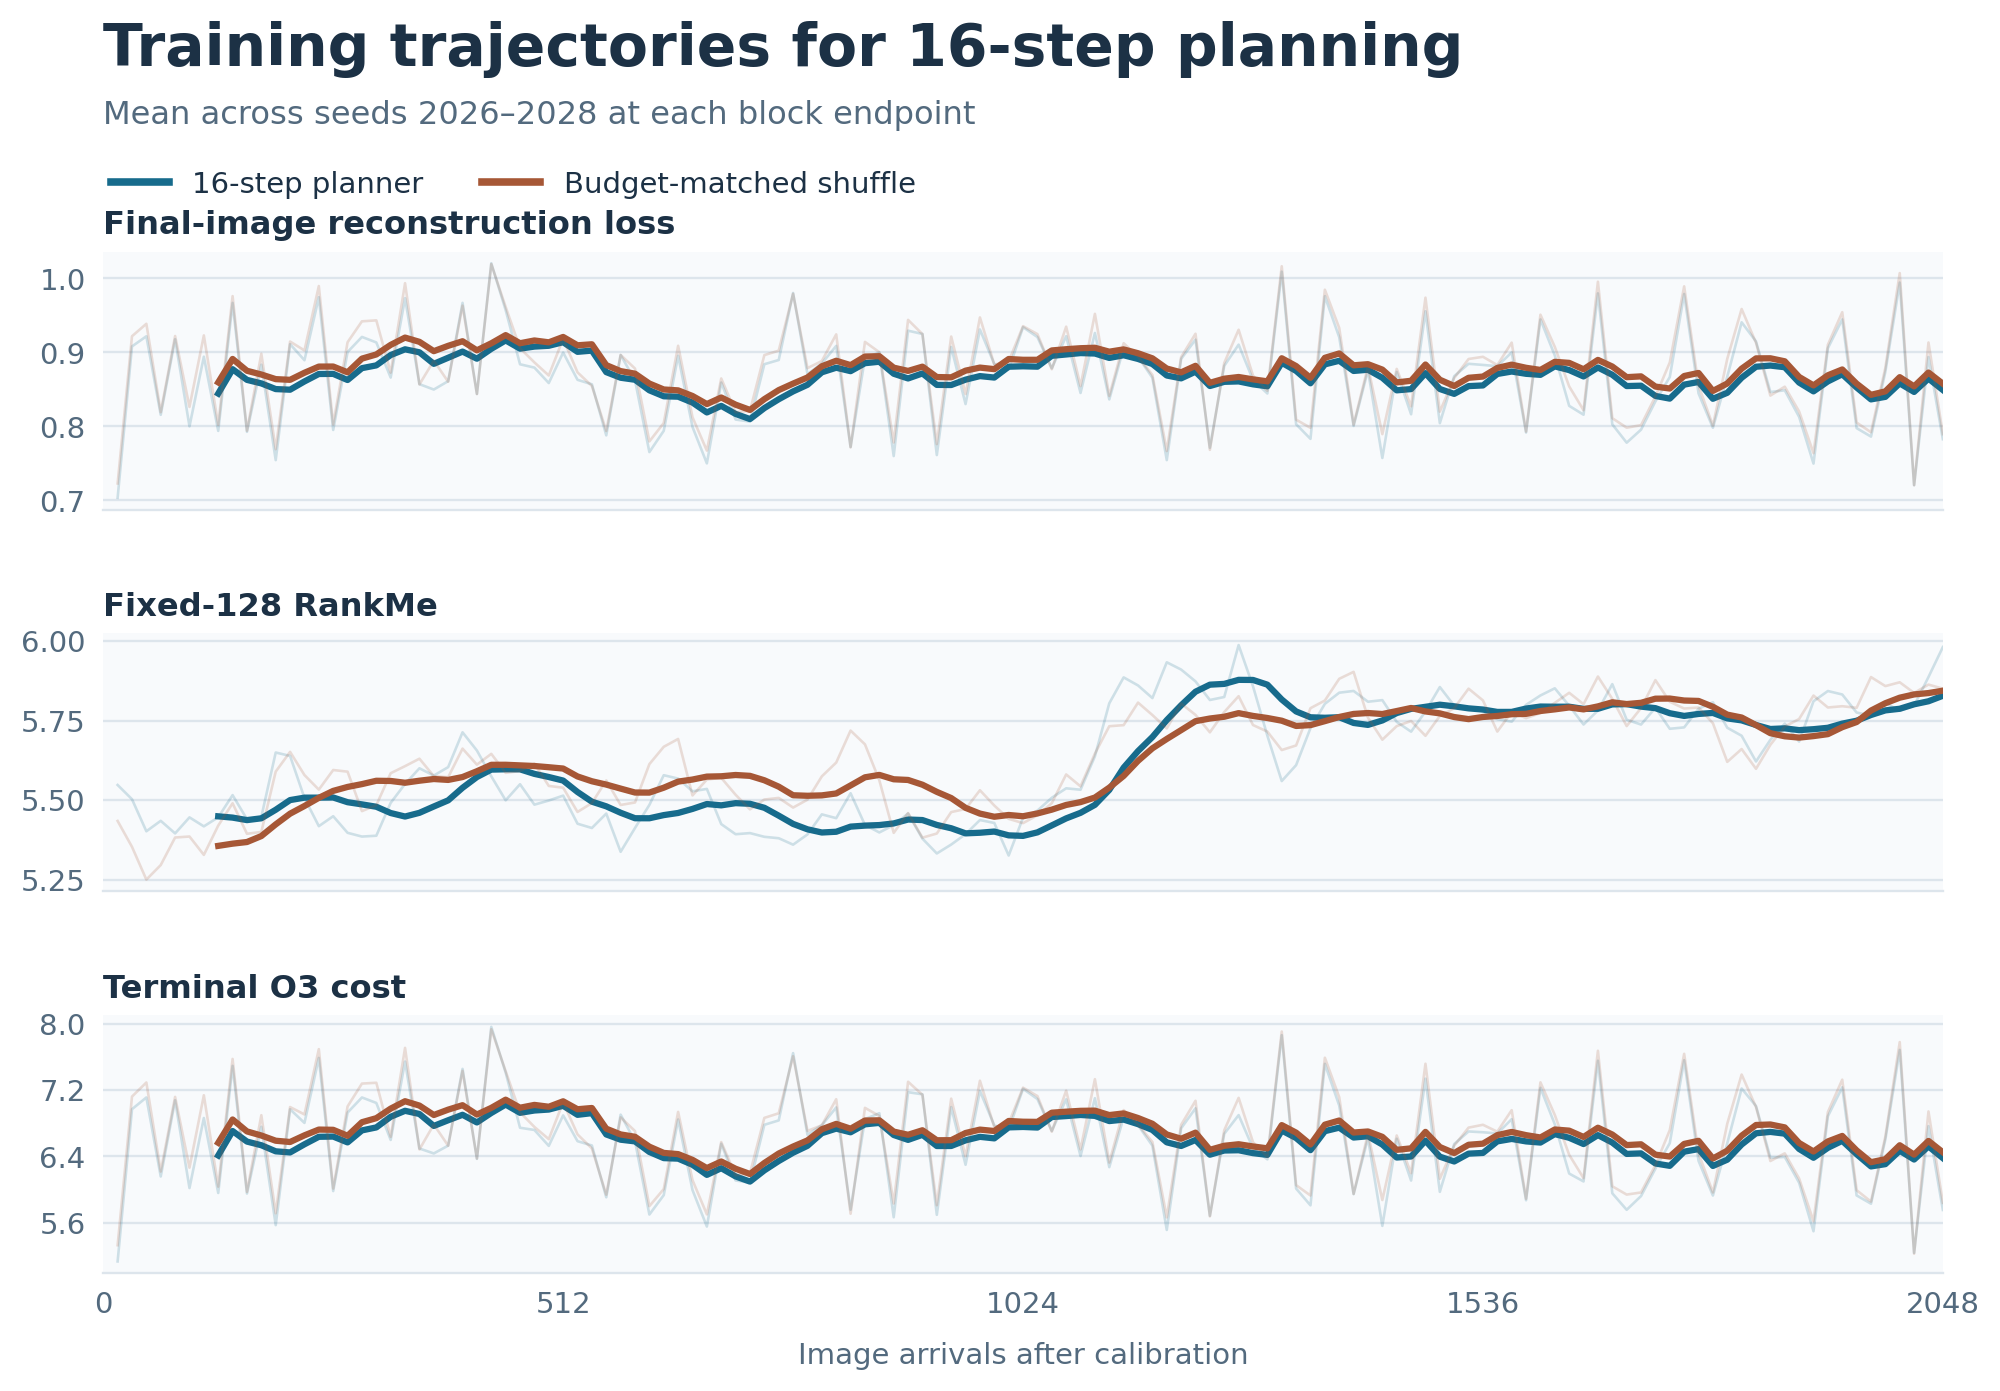

In [2]:
from collections import Counter
from IPython.display import Markdown, display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
import numpy as np

set_matplotlib_formats('retina')
runs = {(row['seed'], row['arm']): row for row in data['runs']}
design = data['design']
seeds = design['seeds']
arms = ('planner', 'shuffle')
frames = np.arange(design['block'], design['arrivals'] + 1, design['block'])
for seed in seeds:
    planned, shuffled = (runs[seed, arm] for arm in arms)
    assert planned['initial'] == shuffled['initial']
    for row in (planned, shuffled):
        np.testing.assert_array_equal(
            [block['start'] + design['block'] - design['calibration']
             for block in row['blocks']], frames
        )
        assert all(np.bincount(block['actions'], minlength=3).tolist() == design['action_counts']
                   for block in row['blocks'])

traces = {
    key: {arm: np.array([[block[key] for block in runs[seed, arm]['blocks']]
                         for seed in seeds]) for arm in arms}
    for key in ('loss', 'rankme', 'cost')
}
labels = {'planner': '16-step planner', 'shuffle': 'Budget-matched shuffle'}
colors = {'planner': '#176b8c', 'shuffle': '#a65736'}
ink, gray, grid = '#1c3145', '#536a7e', '#dde5ec'
metric_names = {'loss': 'Final-image reconstruction loss', 'rankme': 'Fixed-128 RankMe',
                'cost': 'Terminal O3 cost'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': ink,
                     'axes.labelcolor': gray, 'xtick.color': gray, 'ytick.color': gray,
                     'axes.titleweight': 'bold', 'axes.facecolor': '#f8fafc',
                     'figure.dpi': 105, 'savefig.facecolor': 'white'})

def series(ax, values, arm):
    color = colors[arm]
    ax.plot(frames, values, color=color, alpha=.19, linewidth=.9)
    smoothed = np.convolve(values, np.full(8, 1/8), mode='valid')
    ax.plot(frames[7:], smoothed, color=color, linewidth=2.15)

def style(ax):
    ax.set_axisbelow(True)
    ax.grid(axis='y', color=grid, linewidth=.8)
    ax.spines[['left', 'right', 'top']].set_visible(False)
    ax.spines['bottom'].set_color(grid)
    ax.tick_params(length=0, pad=6)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.set(xlim=(0, design['arrivals']), xticks=[0, 512, 1024, 1536, 2048])

handles = [Line2D([], [], color=colors[arm], linewidth=2.6, label=labels[arm]) for arm in arms]
fig, axes = plt.subplots(3, 1, figsize=(10.0, 7.0), sharex=True)
fig.subplots_adjust(left=.097, right=.973, bottom=.105, top=.80, hspace=.48)
fig.text(.097, .957, 'Training trajectories for 16-step planning', fontsize=20,
         fontweight='bold', va='top')
fig.text(.097, .903, 'Mean across seeds 2026–2028 at each block endpoint', fontsize=11,
         color=gray, va='top')
fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(.088, .873), ncol=2, frameon=False)
for ax, (key, paths) in zip(axes, traces.items()):
    style(ax)
    ax.set_title(metric_names[key], loc='left', fontsize=11, pad=6)
    for arm in arms:
        series(ax, paths[arm].mean(axis=0), arm)
axes[-1].set_xlabel('Image arrivals after calibration', labelpad=8)
plt.show()

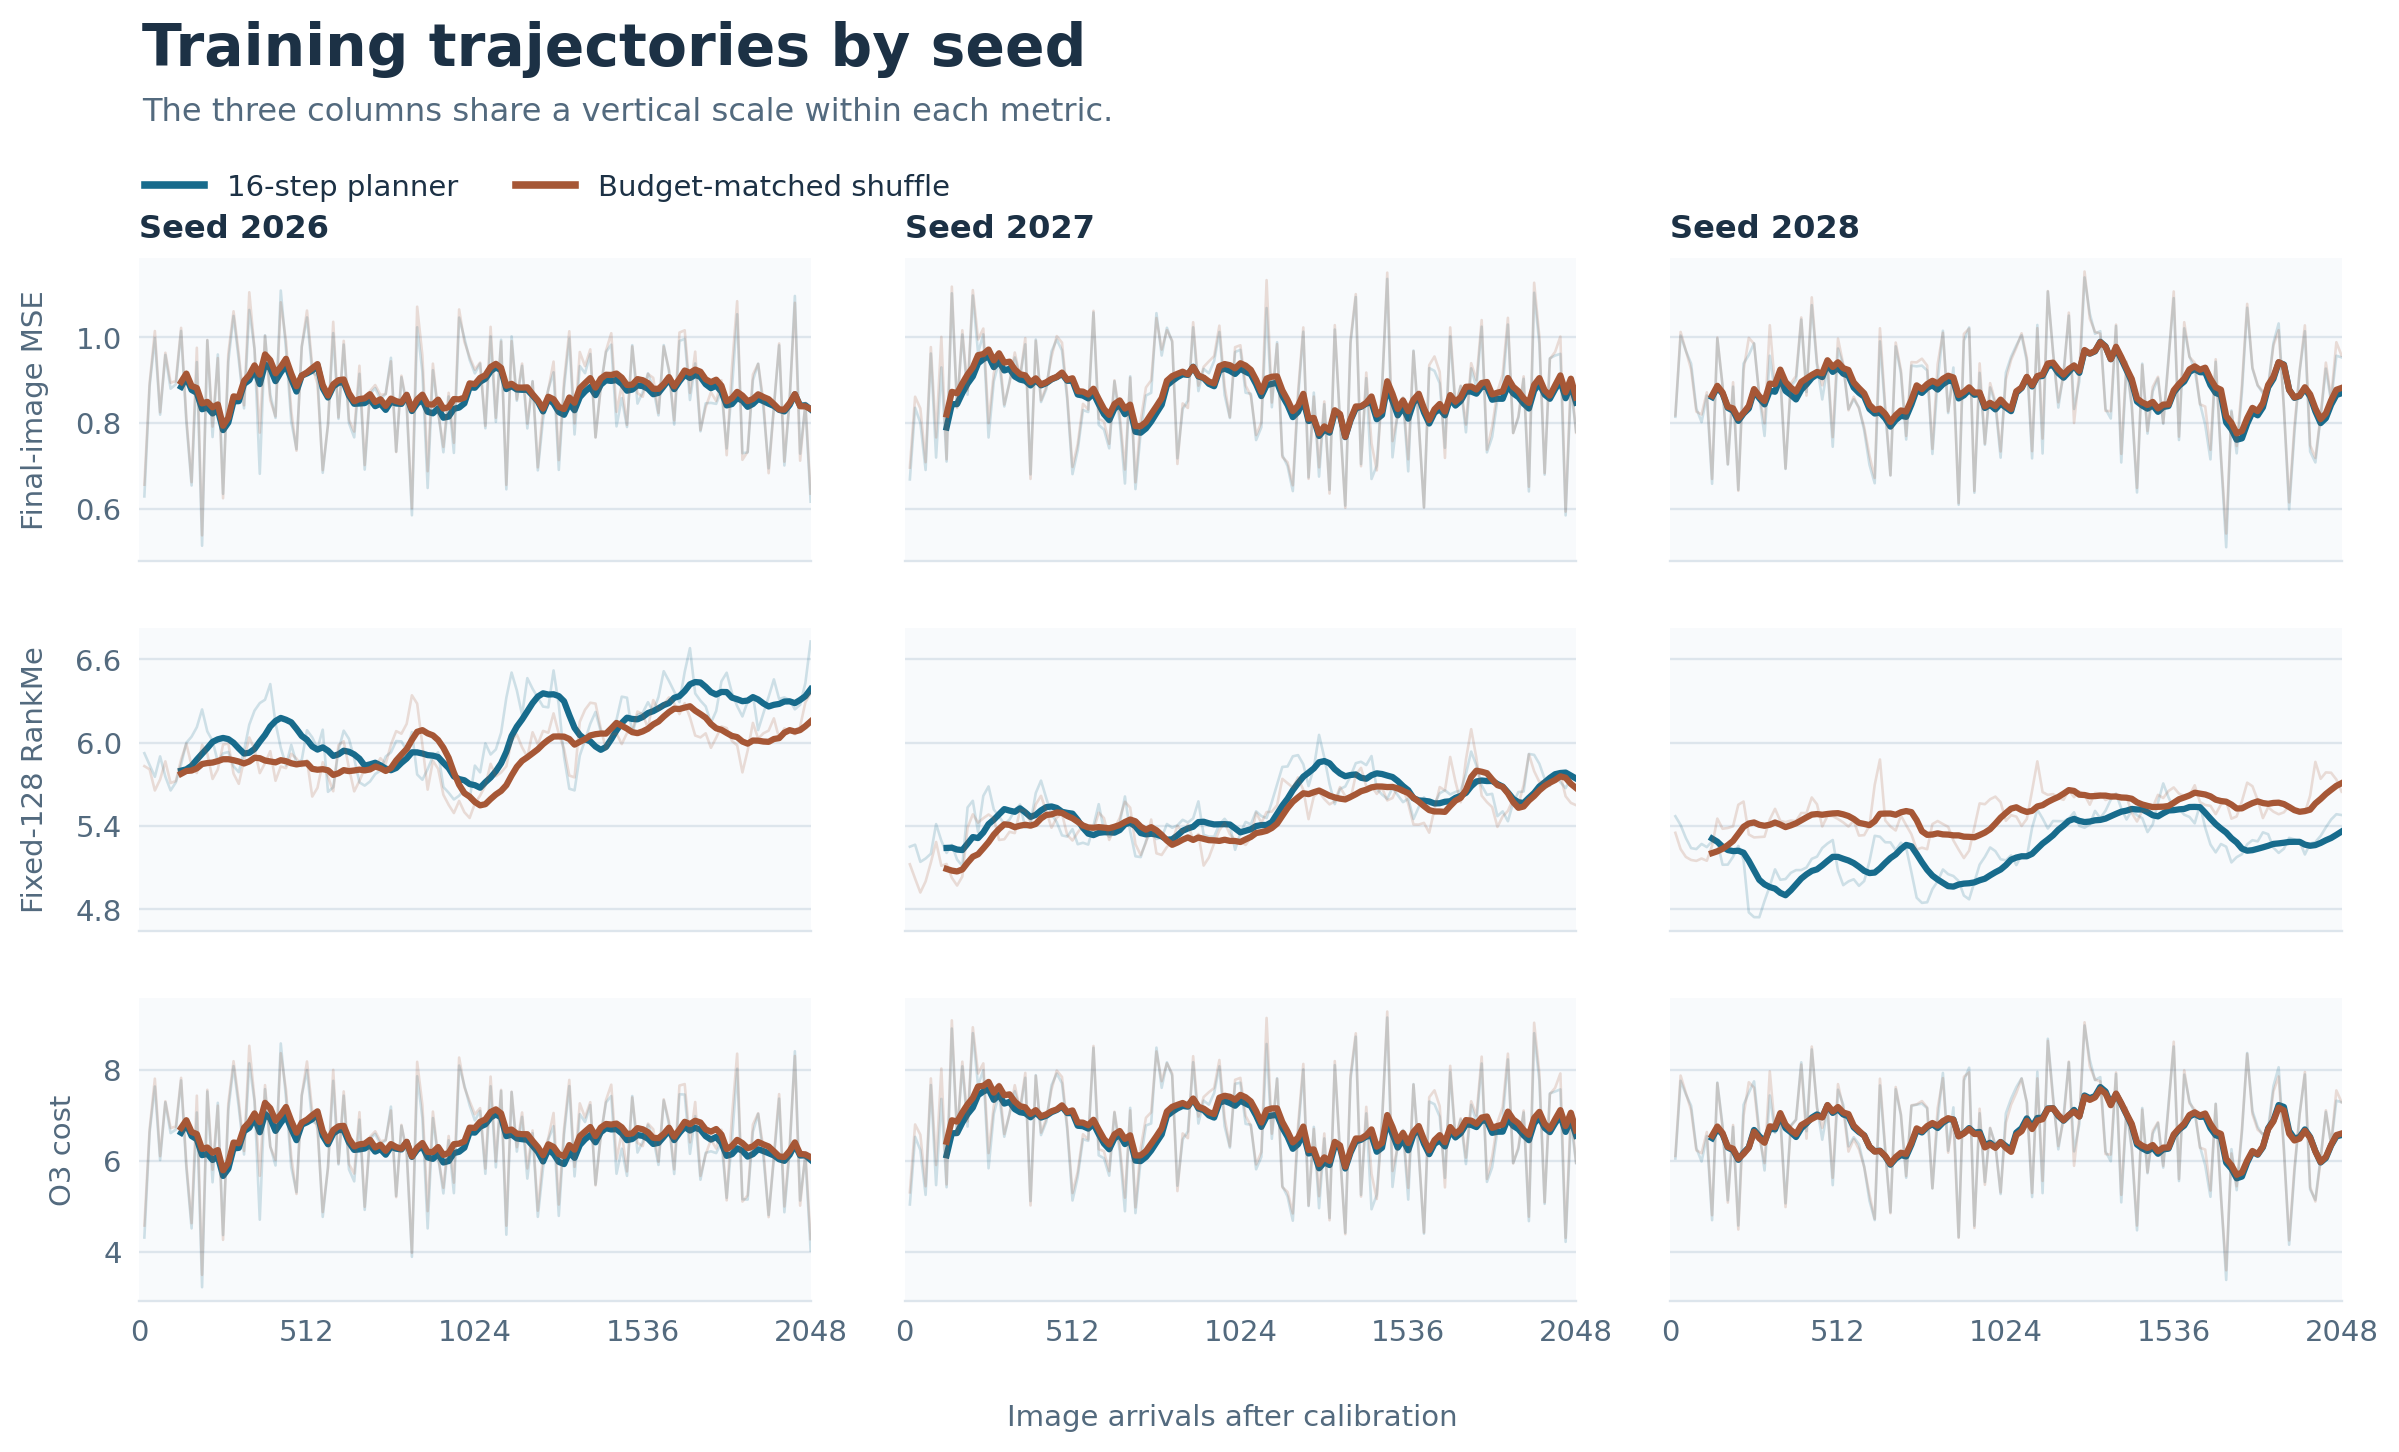

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12.0, 7.2), sharex=True, sharey='row')
fig.subplots_adjust(left=.10, right=.974, bottom=.11, top=.80, hspace=.22, wspace=.14)
fig.text(.101, .957, 'Training trajectories by seed', fontsize=20,
         fontweight='bold', va='top')
fig.text(.101, .907, 'The three columns share a vertical scale within each metric.',
         fontsize=11, color=gray, va='top')
fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(.092, .873), ncol=2, frameon=False)
for i, (key, paths) in enumerate(traces.items()):
    for j, seed in enumerate(seeds):
        ax = axes[i, j]
        style(ax)
        if i == 0:
            ax.set_title(f'Seed {seed}', loc='left', fontsize=11, pad=7)
        if j == 0:
            short = {'loss': 'Final-image MSE', 'rankme': 'Fixed-128 RankMe', 'cost': 'O3 cost'}
            ax.set_ylabel(short[key], labelpad=9)
        for arm in arms:
            series(ax, paths[arm][j], arm)
fig.text(.534, .028, 'Image arrivals after calibration', ha='center', color=gray)
plt.show()

## Probe endpoints and schedule choices

The probe mean gives equal weight to scene, weather, lighting, traffic lights and pedestrians.
Probes were measured before the first block and after the last block. The trajectory plots
above show the label-free training readouts.

In [4]:
tasks = ('scene', 'weather', 'lighting', 'traffic light', 'pedestrian')

def table(headers, rows):
    return Markdown('\n'.join([
        '| ' + ' | '.join(headers) + ' |',
        '| ' + ' | '.join(['---'] * len(headers)) + ' |',
        *['| ' + ' | '.join(row) + ' |' for row in rows],
    ]))

summary = []
for seed in seeds:
    initial = runs[seed, 'planner']['initial']['scores']
    start = 100 * np.mean([initial[key] for key in tasks])
    plan, shuffle = [runs[seed, arm]['endpoint_probe_pct'] for arm in arms]
    summary.append((str(seed), f'{start:.2f}%', f'{plan:.2f}%', f'{shuffle:.2f}%',
                    f'{plan-shuffle:+.2f} pp'))
display(table(('Seed', 'Start', 'Planner endpoint', 'Shuffle endpoint', 'Planner − shuffle'), summary))

readouts = []
for key, paths in traces.items():
    plan, shuffle = (paths[arm].mean() for arm in arms)
    readouts.append((metric_names[key], f'{plan:.4f}', f'{shuffle:.4f}', f'{plan-shuffle:+.4f}'))
display(table(('Mean across block endpoints', 'Planner', 'Shuffle', 'Planner − shuffle'), readouts))

selections = Counter(block['selected'] for seed in seeds for block in runs[seed, 'planner']['blocks'])
assert sum(selections.values()) == len(seeds) * len(frames)
display(table(('Schedule selected', 'Blocks', 'Share'),
              [(name, str(count), f'{count/sum(selections.values()):.1%}')
               for name, count in selections.most_common()]))

| Seed | Start | Planner endpoint | Shuffle endpoint | Planner − shuffle |
| --- | --- | --- | --- | --- |
| 2026 | 60.90% | 60.86% | 60.90% | -0.04 pp |
| 2027 | 60.19% | 61.30% | 60.61% | +0.69 pp |
| 2028 | 60.82% | 60.53% | 60.20% | +0.33 pp |

| Mean across block endpoints | Planner | Shuffle | Planner − shuffle |
| --- | --- | --- | --- |
| Final-image reconstruction loss | 0.8664 | 0.8763 | -0.0099 |
| Fixed-128 RankMe | 5.6185 | 5.6371 | -0.0186 |
| Terminal O3 cost | 6.5762 | 6.6586 | -0.0824 |

| Schedule selected | Blocks | Share |
| --- | --- | --- |
| full late | 79 | 20.6% |
| late full interleaved with quarter | 75 | 19.5% |
| two cycles with full at both ends | 73 | 19.0% |
| four cycles ending full | 67 | 17.4% |
| full middle | 28 | 7.3% |
| early full interleaved with quarter | 25 | 6.5% |
| full early | 25 | 6.5% |
| four cycles starting full | 12 | 3.1% |

Planning finished **0.33 percentage points higher on the mean downstream probe** across
these three seeds. The paired change was near zero for 2026 and positive for 2027 and 2028.
The planner's lower average O3 cost came with lower final-image reconstruction loss and
slightly lower mean Fixed-128 RankMe. Planner execution averaged **30.4 seconds per seed**,
including about 18.0 seconds of schedule selection, versus **12.6 seconds** for the shuffle.
The pilot covers one action budget and one set of eight candidate schedules.

## Run records

The worker updates this notebook as blocks and paired arms finish. Reopen the notebook to read the latest
saved snapshot. The [runner](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/run_block_plan16.py)
and [study records](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/block-plan16-live/pilot-2048/)
are in the research workspace.